# **More Complex Ant Life-Cycle Model and Machine Learning**
***
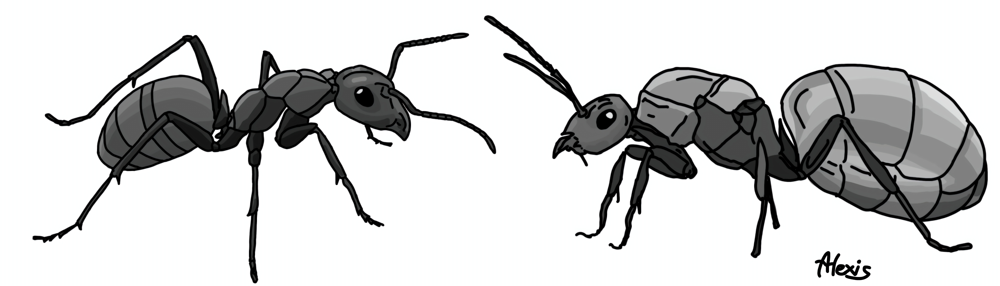
***

**Predicting when a rare, *de novo* allele can persist in a more complex biological model.**

## **Overview**

Ant colonies contain two castes, **queens** and **workers**, that share the same genome but are selected towards different phenotypic optima. Colonies also produce **males**, which are haploid sons of queens. In the model analysed here, males have an optimum of their own as well. A newly arisen allele can therefore be beneficial for one caste or sex and costly for another. Whether such an allele is eventually **lost**, **fixed**, or **maintained as a polymorphism** depends on two groups of factors: the *ecology* of the colonies (survival, extinction, migration of queens and of males, number of queens and of mating males) and the *genetics* of the allele (its effect in each of the three groups, and its dominance in queens and workers; males are haploid, so there is no male dominance).

Answering this question directly requires an individual-based life-cycle simulation, and that is expensive: every combination of parameters is run for 100 replicate simulations over 10'000 generations. This notebook uses **machine learning as a tool to understand the simulation**. It is the adaptation to the **three-way model** (queens, workers and males) of an analysis first made on a simpler two-caste model, which serves as a point of comparison in Section 14.12. We proceed in four steps:

1. **Describe** the simulation and the dataset it produced.
2. **Explore and prepare** the *complete* dataset for a binary classification task: *is polymorphism maintained or not?* We also analyse how well the simulated parameter sets cover the feature space and how noisy the label is.
3. **Train and compare** five classifiers of increasing flexibility: logistic regression, decision tree, random forest, XGBoost and a multilayer perceptron. Polymorphism is a **minority class**, so accuracy is not a good headline metric. The models are compared on the **ROC AUC** (primary metric, used to select the hyperparameters) and on the **precision-recall AUC** (PR AUC), with threshold-based metrics (precision, recall, F1, MCC) at a threshold chosen on out-of-fold predictions. Every model is tuned by 5-fold cross-validation.
4. **Interpret** the best model with simple SHAP, partial dependence and ICE plots, model-free checks directly on the simulated data, and a distilled rule-based surrogate. We use them to test a specific hypothesis about dominance in queens and workers. Because distillation reproduces the black box poorly, we continue with readable alternatives: better student models, a glass-box Explainable Boosting Machine and an interaction screen that does not rely on SHAP interaction values. We finish with what is new in this model: the role of selection in **males** (Section 14.11) and a **comparison with the previous model** (Section 14.12).

## **Contents**

1. Setup
2. The Simulation Model and the Dataset
3. Data Loading and Cleaning
4. Exploratory Data Analysis
5. Data Preparation
6. Data Analysis: Coverage of the Feature Space and Label Noise
7. Modelling Strategy
8. Logistic Regression
9. Decision Tree
10. Random Forest
11. XGBoost
12. Multilayer Perceptron
13. Model Comparison and Diagnostics
14. Interpreting XGBoost
15. Conclusions, Limitations and Next Steps

> **Reading guide.** Blocks labelled **Takeaway** summarise what the preceding result tells us. Blocks labelled **Note** give practical or methodological context. The numbered result tables (Table 1: hyperparameters, Table 2: metrics) are built in Sections 13.1 and 13.2.

## **1. Setup**

### **1.1 Libraries and Random Seed**

The cell below imports every library used in the notebook, grouped by purpose. A fixed **random seed** (`random_seed = 5`) makes the train/test split, the cross-validation folds and every hyperparameter search reproducible, and `POLYMORPH_THRESHOLD` defines what we call a *polymorphic* parameter set (see Section 4.3).

> **Note.** The notebook works directly from the data files listed in `DATASET_FILES` (Section 3). If a file sits in the same folder as the notebook it is used, otherwise it is downloaded from the project's GitHub repository. The generator scripts are only needed to *produce* new data (optional cell at the start of Section 3, `GENERATE_DATA = False`).
>
> **Run configuration.** `QUICK_RUN = True` shrinks every expensive step (rows, search sizes, bootstrap, EBM, interaction screen) so that the whole notebook runs in minutes: use it to check that everything works, then set it back to `False` for the real run. All the budgets are collected in the `BUDGET` dictionary of the cell below.

In [ ]:
### --- Libraries for General Use --- ###
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import warnings


### --- Libraries for Data Splitting, Cross-Validation and Hyperparameter Tuning --- ###
from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_score, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

### --- Libraries for the Models --- ###
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
try:
    from xgboost import XGBClassifier
except ImportError:                      # xgboost is not pre-installed on Google Colab.
    %pip install -q xgboost
    from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
try:
    from interpret.glassbox import ExplainableBoostingClassifier
except ImportError:                      # interpret is not pre-installed on Google Colab.
    %pip install -q interpret
    from interpret.glassbox import ExplainableBoostingClassifier

### --- Libraries for Evaluation and Model Inspection --- ###
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             log_loss, brier_score_loss, r2_score, average_precision_score,
                             precision_recall_curve, precision_score, recall_score, f1_score,
                             matthews_corrcoef, balanced_accuracy_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
try:
    import shap
except ImportError:                      # shap is not pre-installed on Google Colab.
    %pip install -q shap
    import shap

### --- Libraries for Statistics and Sampling Designs --- ###
from scipy import stats
from scipy.stats import qmc
from scipy.spatial import cKDTree

### --- Random Seed and Definition of the Polymorphic Class --- ###
random_seed = 5
POLYMORPH_THRESHOLD = 0.0   # A parameter set is polymorphic if frac_polymorphic > this value.

### --- Run Configuration: One Switch and One Dictionary for Every Budget --- ###
QUICK_RUN = False   # True: tiny budgets, to check in minutes that the whole notebook runs. False: the real run.

BUDGET = {
    'max_rows':         20_000 if QUICK_RUN else None,     # Rows kept from the data set (None = all of them).
    'search_rows':      4_000 if QUICK_RUN else 40_000,    # Training rows used by the hyperparameter searches (Section 7.1).
    'n_iter':           ({'Decision Tree': 4, 'Random Forest': 3, 'XGBoost': 3, 'Multilayer Perceptron': 3} if QUICK_RUN
                         else {'Decision Tree': 60, 'Random Forest': 30, 'XGBoost': 40, 'Multilayer Perceptron': 24}),
    'n_boot':           50 if QUICK_RUN else 1000,         # Bootstrap resamples of the test set (Sections 13.4 and 14.9).
    'perm_repeats_mlp': 2 if QUICK_RUN else 10,            # Shuffles per feature, permutation importance of the MLP (Section 12.3).
    'perm_repeats_xgb': 2 if QUICK_RUN else 5,             # Same for XGBoost (Section 14.2).
    'lc_sizes':         np.linspace(0.3, 1.0, 3) if QUICK_RUN else np.linspace(0.1, 1.0, 6),   # Learning curve (Section 13.8).
    'n_syn':            20_000 if QUICK_RUN else 200_000,  # Synthetic parameter sets labelled by the teacher (Section 14.7).
    'ebm_interactions': [0, 5] if QUICK_RUN else [0, 5, 10, 20],   # Numbers of pair terms tried by the EBM (Section 14.9).
    'screen_rows':      6_000 if QUICK_RUN else 40_000,    # Rows of the interaction screen (Section 14.10).
    'screen_folds':     2 if QUICK_RUN else 3,
    'n_curve_pairs':    3 if QUICK_RUN else 12,            # Pairs added one by one in the cumulative curve (Section 14.10).
}

### **1.2 Helper Plotting Functions**

The same figures are needed several times (once per model, for instance), so they are wrapped in small helper functions. Defining them once keeps the rest of the notebook short and the figures consistent.

| Function | What it displays |
|---|---|
| `barplot_polymorphic_or_not` | Number and fraction of non polymorphic versus polymorphic samples. |
| `plot_feature_distr` | Distribution of every feature, drawn separately for polymorphic and non polymorphic samples. |
| `plot_feature_pairwise_corr` | Correlation matrix of all the features and the response variable. |
| `plot_confusion_matrix` | Confusion matrix of a fitted model on a chosen data set, at a chosen probability threshold, with the counts of TN, FP, FN and TP. |
| `plot_pr` | Precision-recall curve and average precision (PR AUC) of a fitted model on a chosen data set. |
| `plot_roc` | ROC curve and area under the curve (AUC) of a fitted model on a chosen data set. |
| `feat_imp_plot` | Top 10 impurity-based feature importances of a fitted tree ensemble. |
| `wilson_ci` | 95% Wilson confidence interval of an observed proportion (used for observed polymorphism rates). |

The helpers used for tuning and for the result tables are defined in Section 7.1, and those used for partial dependence in Section 14.4.

In [62]:
### --- Polymorphic Versus Non Polymorphic Barplot Helper --- ###
def barplot_polymorphic_or_not(df, polymorph_threshold = 0.0):
    """Bar plot of the non polymorphic versus polymorphic share of the samples."""
    polymorph_samples = (df['frac_polymorphic'] > polymorph_threshold)
    n_poly = int(polymorph_samples.sum())
    n_non = int((~polymorph_samples).sum())

    fig, ax = plt.subplots()
    bars = ax.bar([0, 1], [n_non / len(df), n_poly / len(df)], color = 'moccasin')
    ax.bar_label(bars, labels = [f'n = {n_non}', f'n = {n_poly}'], padding = 3)
    ax.set_xticks(ticks = [0, 1], labels = ['Non Polymorphic', 'Polymorphic'])
    ax.set_ylabel('Fraction of Samples')
    ax.set_ylim(0, 1.05)
    ax.set_title('Non-Polymorphic vs Polymorphic Fraction', fontweight = 'bold', pad = 15)
    plt.show()


### --- Features Distribution Plotting Helper --- ###
def plot_feature_distr(df, params, polymorph_threshold = 0.0, ncols = 4):
    """Histogram of every feature, drawn separately for polymorphic and non polymorphic samples."""
    polymorph_samples = (df['frac_polymorphic'] > polymorph_threshold)

    nrows = int(np.ceil(len(params) / ncols))
    fig, axs = plt.subplots(nrows = nrows, ncols = ncols, figsize = (4 * ncols, 3.6 * nrows), squeeze = False)
    axs = axs.ravel()
    for ax, col_name in zip(axs, params):
        # Counts (Nq, Nm) get one bin per integer value, continuous features get 20 bins.
        if col_name in ('Nq', 'Nm'):
            bins = np.arange(df[col_name].min() - 0.5, df[col_name].max() + 1.5)
        else:
            bins = 20
        ax.hist(df.loc[polymorph_samples, col_name], bins = bins, alpha = 0.5, label = 'Polymorphic', density = True)
        ax.hist(df.loc[~polymorph_samples, col_name], bins = bins, alpha = 0.5, label = 'Non Polymorphic', density = True)
        ax.set_title(col_name, fontweight = 'bold')
        ax.set_xlabel('Value')
        ax.set_ylabel('Density')

    # Hide the unused axes and add one shared legend.
    for ax in axs[len(params):]:
        ax.set_visible(False)
    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc = 'upper center', ncol = 2, fontsize = 14, bbox_to_anchor = (0.5, 1.03))
    plt.tight_layout(rect = [0, 0, 1, 0.97])
    plt.show()


### --- Correlation Matrix Plotting Helper --- ###
def plot_feature_pairwise_corr(df):
    """Correlation matrix of all the columns of df (features and response variable)."""
    corr_matrix = df.corr()

    fig, ax = plt.subplots(figsize = (10, 8))
    cax = ax.matshow(corr_matrix, cmap = 'PuOr', vmin = -1, vmax = 1)
    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_yticks(range(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns, rotation = 90)
    ax.set_yticklabels(corr_matrix.columns)
    fig.colorbar(cax)
    plt.show()


### --- Confusion Matrix Plotting Helper --- ###
def plot_confusion_matrix(model, X_set, y_set, type_of_set = "Test", threshold = 0.5):
    """Confusion matrix of a fitted model at a given probability threshold."""
    pred = (model.predict_proba(X_set)[:, 1] >= threshold).astype(int)
    cm = confusion_matrix(y_set, pred, labels = [0, 1])
    cm_percent = cm / cm.sum() * 100
    cm_row = cm / cm.sum(axis = 1, keepdims = True) * 100

    names = [['True Negative (TN)', 'False Positive (FP)'], ['False Negative (FN)', 'True Positive (TP)']]
    annot_labels = np.array([[f'{names[i][j]}\n{cm[i, j]:,}  ({cm_percent[i, j]:.2f}% of all)' for j in range(2)] for i in range(2)])

    plt.figure(figsize = (8, 6))
    sns.heatmap(cm_row, annot = annot_labels, fmt = '', cmap = 'Oranges', cbar = True,
                linewidths = 2, annot_kws = {'size': 11, 'weight': 'bold'}, vmin = 0, vmax = 100,
                cbar_kws = {'label': '% of the true class'})
    plt.title(f'Confusion Matrix of the {type_of_set} Set (threshold = {threshold:.3f})', fontsize = 14, fontweight = 'bold', pad = 15)
    plt.xlabel('Predicted Label', fontsize = 12)
    plt.ylabel('True Label', fontsize = 12)
    plt.show()


### --- ROC Curve Plotting Helper --- ###
def plot_roc(model, X_set, y_set, type_of_set = "Test"):
    """ROC curve (orange) of a fitted model, with the area under the curve (AUC)."""
    y_proba = model.predict_proba(X_set)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_set, y_proba)
    auc_score = roc_auc_score(y_set, y_proba)

    plt.figure(figsize = (8, 6))
    plt.plot(fpr, tpr, color = 'orange', lw = 2, label = 'ROC Curve')
    plt.plot([0, 1], [0, 1], color = 'gray', linestyle = '--')
    plt.fill_between(fpr, tpr, color = 'skyblue', alpha = 0.4, label = f'AUC (={auc_score:.3f})')

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.title(f'Receiver Operating Characteristic (ROC) for the {type_of_set} Set', fontsize = 14,
              fontweight = 'bold', pad = 15)
    plt.xlabel('False Positive Rate', fontsize = 12)
    plt.ylabel('True Positive Rate', fontsize = 12)
    plt.legend(loc = 'lower right')
    plt.grid(alpha = 0.3)
    plt.show()


### --- Feature Importance Plotting Helper --- ###
def feat_imp_plot(model, feature_names, model_name):
    """Top 10 impurity-based feature importances of a fitted tree ensemble (RF, XGB)."""
    importances = pd.Series(model.feature_importances_, index = feature_names)

    plt.figure(figsize = (10, 6))
    importances.nlargest(10).sort_values().plot(kind = 'barh', color = 'moccasin')
    plt.title(f'Top 10 Feature Importances for {model_name}', fontweight = 'bold')
    plt.xlabel('Relative Importance')
    plt.ylabel('Features')
    plt.tight_layout()
    plt.show()


### --- Wilson Confidence Interval for a Proportion --- ###
def wilson_ci(k, n, confidence = 0.95):
    """Wilson confidence interval (low, high) of an observed proportion k / n."""
    ci = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level = confidence, method = 'wilson')
    return ci.low, ci.high

### --- Precision-Recall Curve Plotting Helper --- ###
def plot_pr(model, X_set, y_set, type_of_set = "Test", threshold = None):
    """Precision-recall curve of a fitted model; the dashed line is a random classifier (precision = prevalence)."""
    y_proba = model.predict_proba(X_set)[:, 1]
    precision, recall, _ = precision_recall_curve(y_set, y_proba)
    ap = average_precision_score(y_set, y_proba)

    plt.figure(figsize = (8, 6))
    plt.plot(recall, precision, color = 'orange', lw = 2, label = f'PR curve (AP = {ap:.3f})')
    plt.axhline(np.mean(y_set), color = 'gray', linestyle = '--', label = f'Random classifier (precision = {np.mean(y_set):.3f})')
    if threshold is not None:
        pred = y_proba >= threshold
        plt.scatter([recall_score(y_set, pred)], [precision_score(y_set, pred, zero_division = 0)], color = 'blue', zorder = 3,
                    label = f'Chosen threshold = {threshold:.3f}')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.title(f'Precision-Recall Curve for the {type_of_set} Set', fontsize = 14, fontweight = 'bold', pad = 15)
    plt.xlabel('Recall', fontsize = 12)
    plt.ylabel('Precision', fontsize = 12)
    plt.legend(loc = 'upper right')
    plt.grid(alpha = 0.3)
    plt.show()

## **2. The Simulation Model and the Dataset**

This section explains how the `.csv` file used in the rest of the notebook was produced. Each row is **one random combination of parameters** (a parameter set), together with what happened to the *de novo* allele over `n_reps` independent replicate simulations of that parameter set.

### **2.1 The Biological Model**

The simulation describes a **structured metapopulation** of demes (ant colonies), each hosting `Nq` queens (between 1 and 10). A *de novo* allele, i.e. one that has just appeared in the population, is introduced in some of the colonies and followed over many generations.

- **Selection on queens and workers.** The colony fecundity is `max(0, (1 - queen phenotype) x worker phenotype)` (function `fecundity` of the generator): a **lower** queen phenotype and a **higher** worker phenotype are better, so the two castes are selected in opposite directions on the same trait. The parameter `z` (0 to 1) describes the current phenotype, `zq` for queens and `zw` for workers.
- **New in this model: males.** Males are **haploid** (sons of queens), so they carry the allele in a single copy and **there is no male dominance parameter**. Males have their own optimum `om` (0 to 1), their own current phenotype `zm` and their own allelic effect `sm`. These three parameters change **which males survive with the *de novo* allele after the queens have produced them**, so the allele is now exposed to selection in three groups (queens, workers, males) instead of two.
- **The allele** has an effect `s` on the trait (from -0.1 to 0.1), set separately for queens (`sq`), workers (`sw`) and males (`sm`), and a dominance `d` in queens (`dq`) and in workers (`dw`).
- **By construction of the data set,** `zw = zq = zm` and `sw = sq = sm`. The current phenotype and the allelic effect are therefore the same in the three groups, and the groups differ through their optima (1, 0 and `om`) and, for the diploid castes, through dominance.

> **Note.** In the dataset the letter `s` is used twice: `s` is the **survival rate** (an ecological parameter), whereas the allelic effect is stored as `sq`, `sw` and `sm`. Be careful not to confuse them.

> **A useful reading of `om` (small-effect approximation).** A male that carries the allele has the phenotype `zm + sm`. If male survival decreases with the squared distance to the optimum `om`, the allele is **favoured in males when `sm x (om - zm) > 0`**, that is, when it moves the male phenotype towards `om`. With `sm = sq` and `zm = zq`, this is `sq x (om - zq) > 0`. This is the rule of the generator: male survival is `1 - min(|om - z|, 1)` and it is applied to the fraction of males carrying each allele (the exact condition has an extra second-order term in `sm`, negligible for small effects). Section 14.11 tests it on the data.

### **2.2 Simulation Parameters**

| Symbol | Meaning | Range |
|---|---|---|
| `Nq` | Number of queens per colony | 1 to 10 |
| `Nm` | Number of males each new queen mates with | 1 to 20 |
| `s` | Survival rate (a queen that has just reproduced survives another cycle) | 0.0 to 1.0 |
| `e` | Extinction rate of colonies | 0.0 to 1.0 |
| `mq`, `mm` | Migration (dispersal) rate of queens and of males (they replace the single `m` of the previous model) | 0.0 to 1.0 |
| `zq`, `zw`, `zm` | Current phenotype of queens, workers and males | 0.0 to 1.0 |
| `sq`, `sw`, `sm` | Effect of the allele in queens, workers and males | -0.1 to 0.1 |
| `dq`, `dw` | Dominance of the allele in queens and workers (none in males, which are haploid) | 0.0 to 1.0 |
| `om` | Optimum of the males | 0.0 to 1.0 |

### **2.3 Recorded Outputs**

For every parameter set, the generator stored all the parameter values above plus the following summaries of the replicate runs:

| Column | Meaning |
|---|---|
| `n_reps` | Number of replicates per parameter set, kept constant (100) during the whole data generation. |
| `mean_pA` | Mean frequency of the *de novo* allele, i.e. the arithmetic mean over the replicates. |
| `sd_pA` | Standard deviation of that frequency across the replicates. |
| `frac_lost` | Fraction of replicates in which the allele was **lost**. |
| `frac_fixed` | Fraction of replicates in which the allele was **fixed**. |
| `frac_polymorphic` | Fraction of replicates in which the allele was **neither fixed nor lost**, i.e. polymorphism was maintained. |


> **Note.** If you work locally, keep `ant_ml_3way_ant_dataset.csv` in the same folder as this notebook. Otherwise it is downloaded automatically.

### **2.4 Figure 1: The Life Cycle**
***
![Figure 1: ant life cycle](<attachment:Sans titre.jpg>)
***

**Figure 1 explained.** The figure shows the life cycle that is simulated in each deme. It is the **ecological backbone** of the model (it comes from the previous, two-caste version; the ecology is shared by both). The only addition is that we now track the difference of survival for males depending of their alleles:

1. **Survival or extinction.** A colony either survives or goes extinct.
2. **Reproduction.** Surviving colonies first produce **workers**, then **sexuals** (new queens and males).
3. **Mating.** Sexuals mate either locally or during mating flights, with `Nm` males per new queen.
4. **Recolonisation.** Queen slots left empty, by the death of a queen or by the extinction of a colony, are refilled.

Two probabilities govern this cycle. **Survival** is the probability that a queen that has just reproduced survives another cycle. **Dispersal** is the probability that a local queen, or a queen arriving by dispersal, recolonises an empty queen slot. In the three-way model, queens and males disperse at their own rates (`mq` and `mm`).

### **2.5 Figure 2: Genotype and Phenotype in Queens and Workers**
***
![Figure 2: queen and worker genotype to phenotype](<attachment:Capture d’écran 2026-10-30 à 18.40.58.png>)
***

**Figure 2 explained.** The figure shows the genotype-to-phenotype map for **queens and workers** of the previous model. The model follows **one focal diploid locus with two alleles**: `A`, the *de novo* allele, and `a`, with opposite effects in queens and workers. In the three-way model the haploid males are added to this picture: a male carries a single allele, `A` or `a`, with no dominance, and its phenotype is selected towards `om`. The figure is kept because the queen and worker part is unchanged.

## **3. Data Loading and Cleaning**

We now load the data and remove the columns that carry no useful information for learning.

| Column removed | Reason |
|---|---|
| `frac_lost`, `frac_fixed` | **Redundant** with `frac_polymorphic`, since $1 - (\text{frac\_lost} + \text{frac\_fixed}) = \text{frac\_polymorphic}$. |
| `n_reps` | **Constant**: it equals 100 in every row, so it cannot explain anything. |
| `mean_pA` | **Misleading** as a response. A mean frequency of 0.5 looks like widespread polymorphism, but it can arise just as well when half of the replicates lose the allele (frequency 0) and half fix it (frequency 1), with no polymorphism at all. |
| `sd_pA` | Spread of the same quantity. As `mean_pA` is not a good metric, neither is its standard deviation. |

After cleaning, we are left with the fifteen simulation parameters (`param_cols_all`) and the response variable `frac_polymorphic`. The cell also checks that every parameter lies in the range documented in Section 2.2.
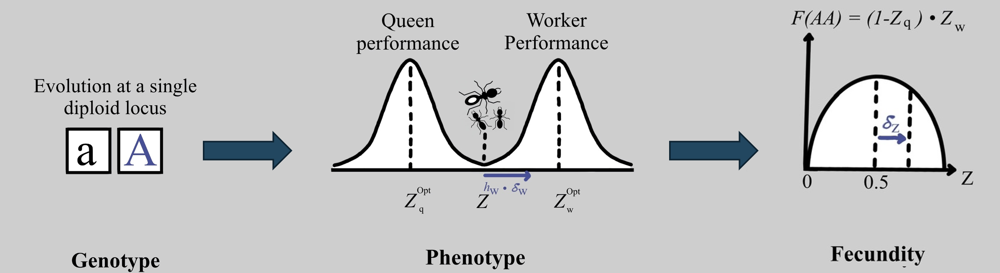
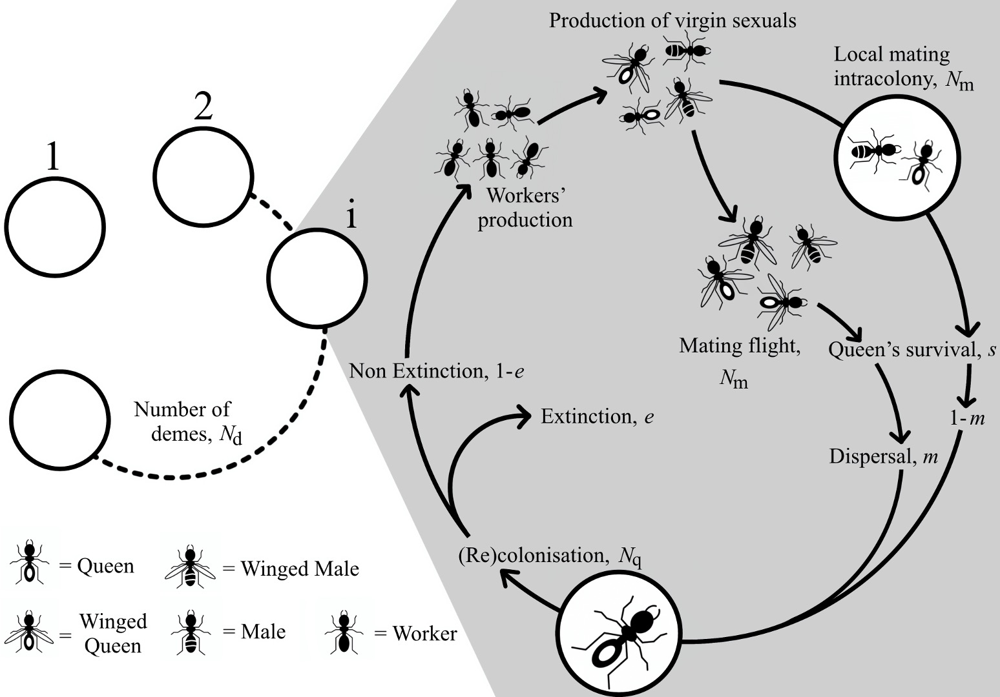

In [63]:
### --- Data Generation (Optional: Skipped by Default) --- ###
# The data set already exists (Section 3 loads it), so this cell does nothing unless GENERATE_DATA is True.
# It downloads the generator scripts from GitHub, checks the GPU and writes a new CSV next to the notebook.
GENERATE_DATA = False

if GENERATE_DATA:
    import urllib.request
    scripts_url = 'https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/DatasetGenerators/'
    for script_name in ('dataset_generator_3way_model_on_CPU.py', 'dataset_generator_3way_model_on_GPU.py'):
        print(f'Downloading {script_name} from GitHub...')
        urllib.request.urlretrieve(scripts_url + script_name, script_name)
    import dataset_generator_3way_model_on_GPU as gpu

    ### --- Check GPUs --- ###
    print(gpu.pick_device('auto'))           # Expect device(type='mps') on a MacBook.
    gpu.selftest()                           # About 1-2 min; compares the GPU model with the CPU one.

    ### --- Generate the Dataset --- ###
    ok, msg = gpu.generate_dataset_gpu(
        n_samples = 10000,
        reps = 100,
        out_path = 'ant_male_freq_gpu.csv',  # Saved next to the notebook.
        rows_per_batch = 500,                # Lower it if you hit a memory error.
        male_exponent = 1.0,
        seed = random_seed
    )
    print(ok, msg)

In [64]:
### --- Data Loading (Works both Locally and on Colab) --- ###
repo_url = 'https://raw.githubusercontent.com/EnvinyatarTheRenewer/ant_life_cycle_simulation_and_ml/main/Datasets/'
DATASET_FILES = ['ant_ml_3way_ant_dataset_part1.csv', 'ant_ml_3way_ant_dataset_part2.csv']


def load_dataset(files):
    """Load every file (local if available, otherwise GitHub) and stack them under a fresh, unique row index.

    The `sample_id` of the CSV restarts at 0 for every run of the generator, so it is NOT unique in the stacked table. It is kept as a
    column (it tells where a run starts, see below) and never used as the index: a repeated index silently breaks `.loc` look-ups.
    """
    parts = []
    for file in files:
        if os.path.exists(file):
            print(f'Using local file {file}.')
            part = pd.read_csv(file, index_col = 0)
        else:
            print(f'Downloading {file} from GitHub...')
            part = pd.read_csv(repo_url + file, index_col = 0)
        parts.append(part.rename_axis('sample_id').reset_index())
    df = pd.concat(parts, ignore_index = True)
    print(f'Loaded {len(df):,} rows from {len(files)} file(s).')
    return df


def check_generation_runs(df, polymorph_threshold = 0.0, alpha = 1e-3, min_rows = 1000):
    """Split the data set into generation runs and test that they share the same polymorphism share.

    `sample_id` restarts at 0 for every run of the generator (and carries on across the CSV files), so a new run starts wherever it goes
    back down. Runs made with another generator version or other settings give a different share of polymorphic parameter sets, and
    pooling them would mix two simulators with no column to tell them apart. A warning is raised instead of an error (the table is
    printed so that the cause can be seen), and the check is skipped when the ids are not in generation order.
    """
    ids = df['sample_id'].to_numpy()
    run = np.cumsum(np.r_[False, np.diff(ids) < 0])
    positive = (df['frac_polymorphic'] > polymorph_threshold).to_numpy()
    table = pd.DataFrame({'rows': np.bincount(run), 'polymorphic': np.bincount(run, weights = positive)})
    table['share polymorphic'] = table['polymorphic'] / table['rows']
    big = table[table['rows'] >= min_rows]
    if len(table) > 50 or len(big) < 2:
        print(f'Run check skipped: {len(table)} run(s) detected, {len(big)} with at least {min_rows:,} rows.')
        return table
    display(table.round(4))
    p_value = stats.chi2_contingency(np.c_[big['polymorphic'], big['rows'] - big['polymorphic']])[1]
    if p_value < alpha:
        warnings.warn(f'The {len(big)} generation runs disagree on the share of polymorphic parameter sets '
                      f'({big["share polymorphic"].min():.1%} to {big["share polymorphic"].max():.1%}, chi-square p = {p_value:.2g}). '
                      'They probably come from different generator versions or settings: do not pool them.')
    else:
        print(f'The {len(big)} generation runs agree on the share of polymorphic parameter sets (chi-square p = {p_value:.2g}).')
    return table


df_raw = load_dataset(DATASET_FILES)
runs_table = check_generation_runs(df_raw, polymorph_threshold = POLYMORPH_THRESHOLD)
df_raw = df_raw.drop(columns = 'sample_id')        # Not a feature, and not an index either (see load_dataset).
if BUDGET['max_rows']:                             # QUICK_RUN only.
    df_raw = df_raw.sample(n = BUDGET['max_rows'], random_state = random_seed).reset_index(drop = True)
    print(f'QUICK_RUN: keeping a random subsample of {len(df_raw):,} rows.')

### --- Documented Parameter Ranges (Section 2.2) --- ###
# Single source of truth for the ranges: used for the sanity check below, for the coverage analysis
# (Section 6) and to sample new parameter sets in the distillation step (Section 14.7).
PARAM_RANGES = {
    's': (0.0, 1.0), 'e': (0.0, 1.0), 'mq': (0.0, 1.0), 'mm': (0.0, 1.0),
    'zw': (0.0, 1.0), 'zq': (0.0, 1.0), 'zm': (0.0, 1.0),
    'dw': (0.0, 1.0), 'dq': (0.0, 1.0),
    'sw': (-0.1, 0.1), 'sq': (-0.1, 0.1), 'sm': (-0.1, 0.1),
    'om': (0.0, 1.0),
    'Nq': (1, 10), 'Nm': (1, 20),
}
param_cols_all = list(PARAM_RANGES)   # All the simulation parameters.

### --- Data Cleaning --- ###
# Remove everything that is neither an explanatory feature nor the response variable.
df_sim = df_raw.drop(columns = ['sd_pA', 'n_reps', 'frac_lost', 'frac_fixed', 'mean_pA'])

### --- Sanity Check: Observed Ranges Versus Documented Ranges --- ###
range_check = pd.DataFrame({
    'observed min': df_sim[param_cols_all].min(),
    'documented min': [PARAM_RANGES[c][0] for c in param_cols_all],
    'observed max': df_sim[param_cols_all].max(),
    'documented max': [PARAM_RANGES[c][1] for c in param_cols_all],
})
display(range_check)
assert (range_check['observed min'] >= range_check['documented min'] - 1e-9).all()
assert (range_check['observed max'] <= range_check['documented max'] + 1e-9).all()
assert df_sim.index.is_unique        # Every later `.loc[X_test.index]` look-up relies on it.
print(f'{len(df_sim):,} parameter sets, {df_sim.isna().sum().sum()} missing values.')

Loaded 419,520 rows from 2 file(s).


,rows,polymorphic,share polymorphic
0,50000,11161.0,0.2232
1,119520,26975.0,0.2257
2,50000,11128.0,0.2226
3,50000,11227.0,0.2245
4,50000,11410.0,0.2282
5,50000,11200.0,0.2240
6,50000,11231.0,0.2246


The 7 generation runs agree on the share of polymorphic parameter sets (chi-square p = 0.4).


,observed min,documented min,observed max,documented max
s,0.000003,0.0,0.999998,1.0
e,0.000005,0.0,0.999998,1.0
mq,0.000002,0.0,0.999994,1.0
mm,0.000001,0.0,1.000000,1.0
zw,0.000003,0.0,0.999998,1.0
zq,0.000003,0.0,0.999998,1.0
zm,0.000003,0.0,0.999998,1.0
dw,0.000001,0.0,0.999997,1.0
dq,0.000001,0.0,0.999999,1.0
sw,-0.100000,-0.1,0.100000,0.1


419,520 parameter sets, 0 missing values.


A first look at the data confirms the structure described in Section 2. Note that `zw`, `zq` and `zm` are identical in every row, and so are `sw`, `sq` and `sm`: this is by design of the simulation, and we remove these duplicates in Section 5.1. The `frac_polymorphic` column is the response variable; every other column is a simulation parameter.

In [5]:
### --- Data Display --- ###
df_sim.head(5) # Display head of the data.

,s,e,mq,mm,zw,zq,zm,dw,dq,sw,sq,sm,Nq,Nm,om,frac_polymorphic
0,0.613055,0.849654,0.142557,0.940705,0.418118,0.418118,0.418118,0.126778,0.841092,0.009328,0.009328,0.009328,5,16,0.051235,0.00
1,0.964625,0.126637,0.131570,0.548279,0.064850,0.064850,0.064850,0.428194,0.262157,-0.041829,-0.041829,-0.041829,9,12,0.836872,0.00
2,0.882037,0.628730,0.800464,0.638928,0.169057,0.169057,0.169057,0.513577,0.866683,0.089583,0.089583,0.089583,5,8,0.228524,0.00
3,0.232578,0.459356,0.394233,0.193663,0.757207,0.757207,0.757207,0.043562,0.002677,-0.043353,-0.043353,-0.043353,1,8,0.981752,0.00
4,0.791809,0.237323,0.496088,0.532893,0.599755,0.599755,0.599755,0.262703,0.411658,-0.003305,-0.003305,-0.003305,9,17,0.270765,0.09


## **4. Exploratory Data Analysis**

Before choosing a model, we look at the data to decide **how it should be processed**.

### **4.1 Distribution of the Response Variable**

We begin with a histogram of `frac_polymorphic`. For each parameter set, this variable is the fraction of replicates (out of 100) in which polymorphism was maintained.

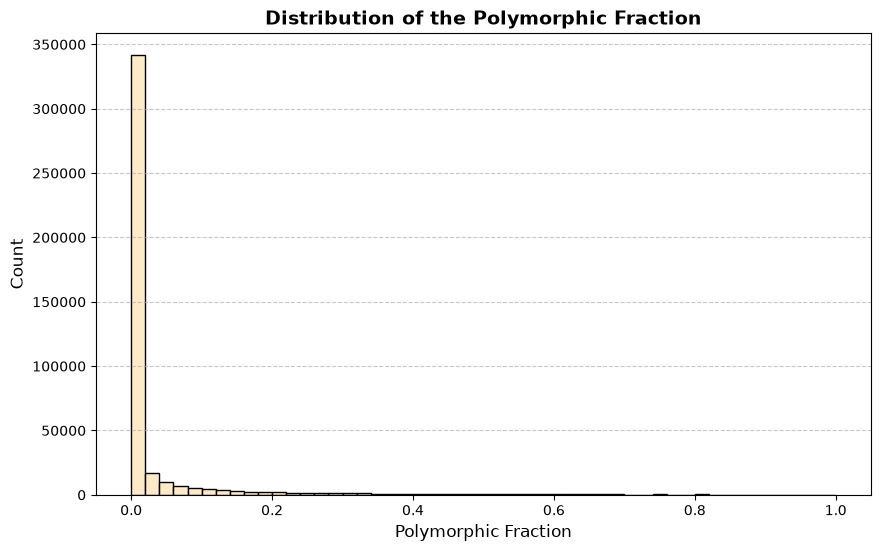

In [6]:
### --- Distribution of the Polymorphic Fraction --- ###
plt.figure(figsize = (10, 6)) # Set figure dimensions.
sns.histplot(df_sim['frac_polymorphic'], bins = 50, color = 'moccasin') # Plots the histogram.

# Add labels, title and horizontal dashed grid lines for clarity.
plt.title('Distribution of the Polymorphic Fraction', fontsize = 14, fontweight = 'bold')
plt.xlabel('Polymorphic Fraction', fontsize = 12)
plt.ylabel('Count', fontsize = 12)
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)
plt.show()

The distribution is the classical **zero-inflated** shape: a very large spike at 0, and the remaining values spread over the rest of the range. In most parameter sets, the allele is lost or fixed in every single replicate, and only some parameter sets let polymorphism survive.

### **4.2 Classification or Regression?**

The problem can be framed in two valid ways. Both make biological sense, but they answer slightly different questions:

| Framing | Question answered | Cost |
|---|---|---|
| **Regression** on `frac_polymorphic` | *How much* polymorphism do we expect? | Hard to fit on such a skewed variable. |
| **Binary classification** (polymorphic or not) | *Whether* polymorphism is maintained for a given parameter set. | Loses the information on how frequent polymorphism is. |

Because the data is so skewed, a regression model would concentrate on the many zeros and would systematically under-predict polymorphism. The better option is therefore a **binary classification** on all the rows:

- **0**: non polymorphic (`frac_polymorphic = 0`)
- **1**: polymorphic (`frac_polymorphic > 0`)

Biologically, the main interest is whether polymorphism is maintained at all, so giving up the quantification of its frequency is an acceptable trade-off. If quantification becomes relevant later, the problem can be extended into a **hurdle model**: a classifier that decides *whether* polymorphism occurs (this notebook), followed by a regressor trained only on the polymorphic parameter sets that estimates *how frequent* it is.

### **4.3 Class Balance**

We need to know how many parameter sets actually show some polymorphism. A sample is called polymorphic as soon as at least one replicate kept the allele (`POLYMORPH_THRESHOLD = 0.0`). The bar plot shows the share of each class, and the cell also prints the accuracy of a "classifier" that always predicts the majority class: the baseline that every model has to beat.

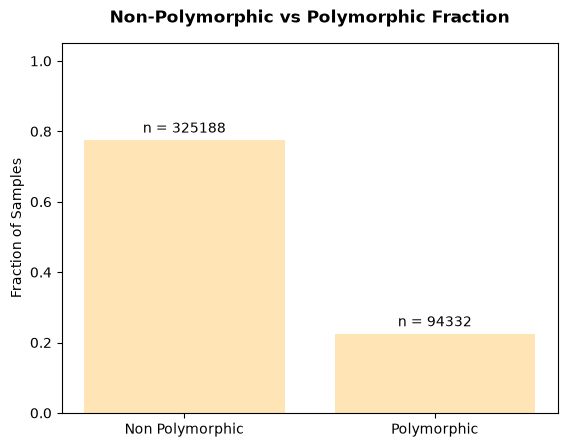

Polymorphic parameter sets:     22.49%  (94,332 of 419,520)
Non polymorphic parameter sets: 77.51%
Majority-class baseline accuracy: 0.775   (a "classifier" that always answers "not polymorphic")
PR AUC of a random classifier:    0.225   (= the prevalence)   |   chance-level ROC AUC: 0.500


In [7]:
### --- Class Balance of the Complete Data Set --- ###
barplot_polymorphic_or_not(df_sim, polymorph_threshold = POLYMORPH_THRESHOLD)

prevalence = (df_sim['frac_polymorphic'] > POLYMORPH_THRESHOLD).mean()
print(f'Polymorphic parameter sets:     {prevalence:.2%}  ({int((df_sim["frac_polymorphic"] > POLYMORPH_THRESHOLD).sum()):,} of {len(df_sim):,})')
print(f'Non polymorphic parameter sets: {1 - prevalence:.2%}')
print(f'Majority-class baseline accuracy: {max(prevalence, 1 - prevalence):.3f}   (a "classifier" that always answers "not polymorphic")')
print(f'PR AUC of a random classifier:    {prevalence:.3f}   (= the prevalence)   |   chance-level ROC AUC: 0.500')

> **Takeaway.** Polymorphism is the **minority class**, so **accuracy is not a good headline metric**: always answering "not polymorphic" already reaches the majority-class accuracy printed above. We therefore use

1. the **ROC AUC** as the primary metric. It measures how well the predicted probabilities rank polymorphic above non polymorphic parameter sets, it does not depend on the share of positives, and it is the metric of the previous notebook, so the two analyses stay comparable;
2. the **PR AUC** (average precision) as the second metric. It is the area under the precision-recall curve, it only looks at the positive class, and a random classifier scores the prevalence, so it separates strong models better than the ROC AUC when both are close to 1;
3. **precision, recall, F1 and MCC** at a decision threshold that is **chosen on out-of-fold predictions** (the threshold that maximises the F1), not fixed at 0.5.

As before, we deliberately **do not rebalance** the data (no resampling, no class weights). Re-weighting the classes would multiply the odds of polymorphism by a constant factor, so the predicted probabilities (and the SHAP baseline, and every probability map drawn later) would no longer be real probabilities of polymorphism. The calibration of the final model is checked in Section 13.5.

> **Note.** The share above is defined as `frac_polymorphic > 0`. Section 6.5 shows how it depends on the threshold used in the definition.

### **4.4 Feature Distributions**

The figure below shows the distribution of each feature, separately for polymorphic and non polymorphic samples. As each parameter was drawn uniformly within its range, any visible difference between the two histograms points to a feature that influences polymorphism.

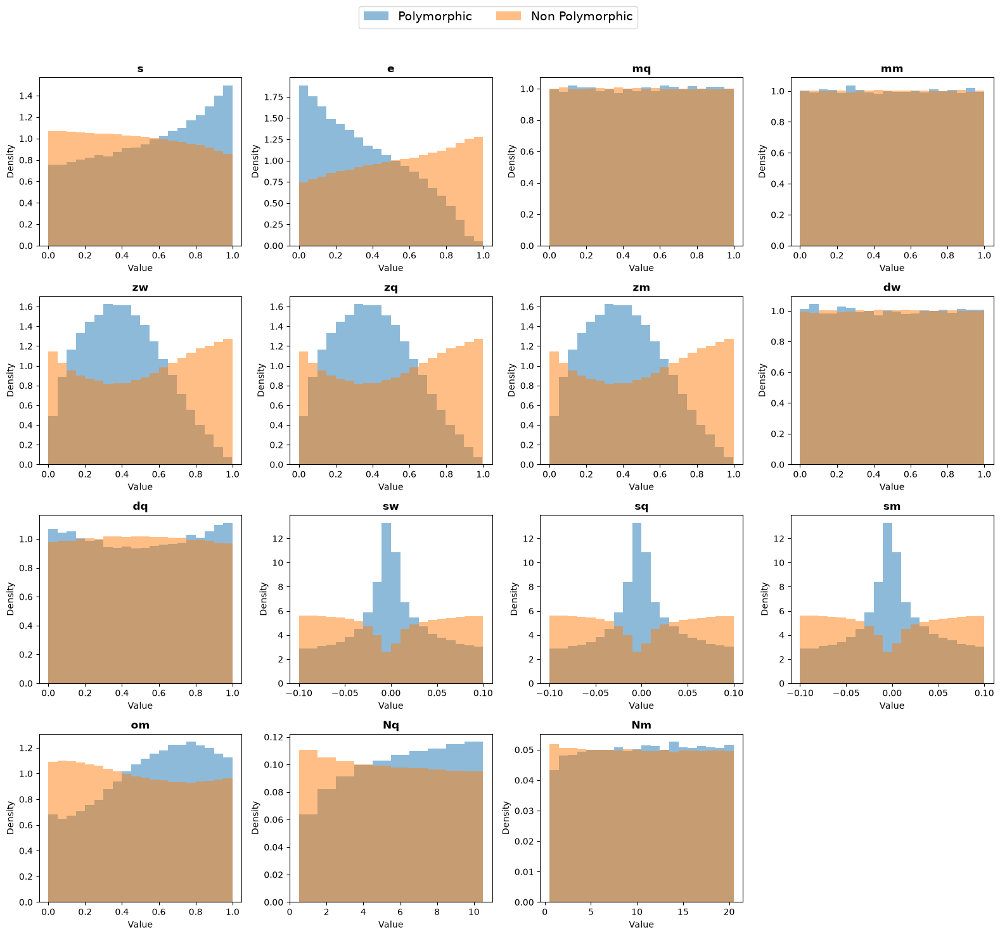

In [8]:
### --- Plotting Using the Helper plot_feature_distr --- ###
plot_feature_distr(df_sim, param_cols_all, polymorph_threshold = POLYMORPH_THRESHOLD)

### **4.5 Correlation Between Features**

The correlation matrix below includes all the parameters and the response variable. We want to **avoid strongly correlated features**, because they make models harder to interpret and make feature-importance measures unreliable. Some correlations are known in advance from the way the simulation is built.

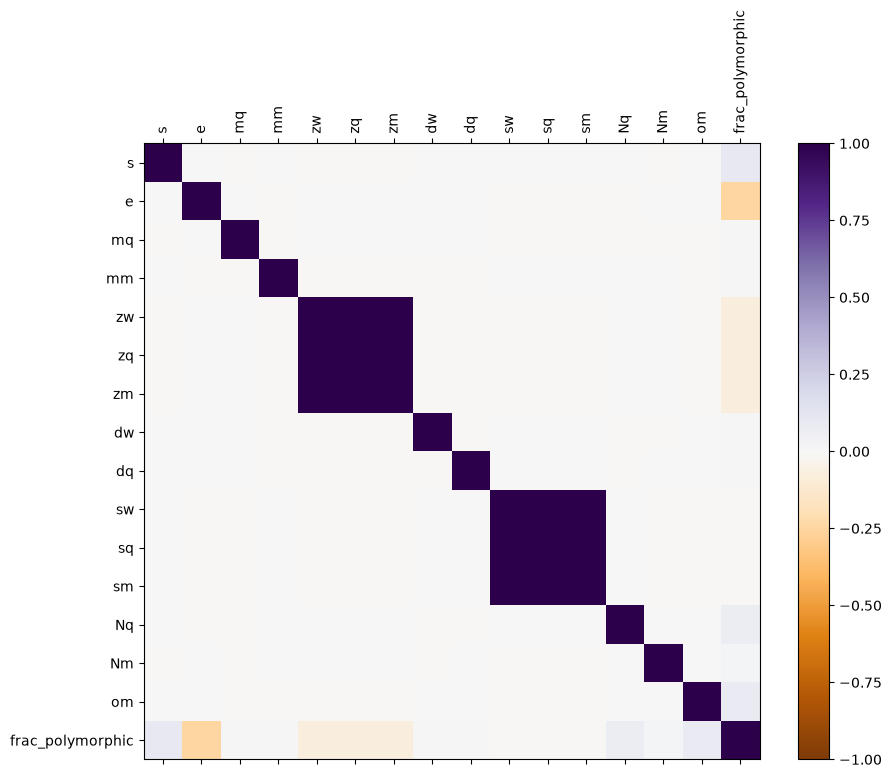

In [9]:
### --- Plotting Using the Helper plot_feature_pairwise_corr --- ###
plot_feature_pairwise_corr(df_sim)

> **Takeaway.** The only strongly correlated groups are **`zq`/`zw`/`zm`** and **`sq`/`sw`/`sm`**, which are identical by design of the simulation. We keep one variable from each group. Every other parameter is uncorrelated with the others because they were drawn **independently**. This matters later: explanation methods such as SHAP and partial dependence are most trustworthy when features are independent (Section 14).

## **5. Data Preparation**

### **5.1 Removing Redundant Features and Defining the Response**

Two operations are applied:

1. **Dropping duplicated features.** We remove `zw`, `zm`, `sw` and `sm`, which are identical to `zq` and `sq` (the cell checks it first). The effect of the allele and the current phenotype are therefore represented once, as `sq` and `zq`, and **apply to the three groups**. What is specific to males, in this data set, is `om`.
2. **Binary response.** The response `polymorphic` is 1 if at least one replicate maintained the allele (`frac_polymorphic > POLYMORPH_THRESHOLD`) and 0 otherwise.

The continuous `frac_polymorphic` stays in `df_model` **only for analysis** (label noise in Sections 6.5, 13.6 and 13.7, and observed rates in Section 14). It is never used as a feature.

No rows are removed: the complete data is used.

In [10]:
### --- Redundant Features and Binary Response --- ###
# zw = zq = zm and sw = sq = sm by design of the simulation: verify it, then drop the duplicates.
assert np.allclose(df_sim['zq'], df_sim['zw']) and np.allclose(df_sim['zq'], df_sim['zm'])
assert np.allclose(df_sim['sq'], df_sim['sw']) and np.allclose(df_sim['sq'], df_sim['sm'])
feature_cols = [c for c in param_cols_all if c not in ('zw', 'zm', 'sw', 'sm')]   # The 11 features.
target_col = 'polymorphic'                                                        # The response variable.

df_model = df_sim[feature_cols + ['frac_polymorphic']].copy()
df_model[target_col] = (df_model['frac_polymorphic'] > POLYMORPH_THRESHOLD).astype(int)

print('Features:', feature_cols)
print('Shape of the modelling table:', df_model.shape)
df_model.head(5)


Features: ['s', 'e', 'mq', 'mm', 'zq', 'dw', 'dq', 'sq', 'om', 'Nq', 'Nm']
Shape of the modelling table: (419520, 13)


,s,e,mq,mm,zq,dw,dq,sq,om,Nq,Nm,frac_polymorphic,polymorphic
0,0.613055,0.849654,0.142557,0.940705,0.418118,0.126778,0.841092,0.009328,0.051235,5,16,0.00,0
1,0.964625,0.126637,0.131570,0.548279,0.064850,0.428194,0.262157,-0.041829,0.836872,9,12,0.00,0
2,0.882037,0.628730,0.800464,0.638928,0.169057,0.513577,0.866683,0.089583,0.228524,5,8,0.00,0
3,0.232578,0.459356,0.394233,0.193663,0.757207,0.043562,0.002677,-0.043353,0.981752,1,8,0.00,0
4,0.791809,0.237323,0.496088,0.532893,0.599755,0.262703,0.411658,-0.003305,0.270765,9,17,0.09,1


### **5.2 Train / Test Split**

The data is split **once**, with the same class proportions in both parts (stratified split):

| Set | Share | Role |
|---|---|---|
| **Train** | 90% | Fit the models and tune the hyperparameters by **5-fold cross-validation**. |
| **Validation** | (inside the train set) | Each fold of the cross-validation serves once as validation set. |
| **Test** | 10% | Used **once** per model, for the final evaluation. |

In [11]:
### --- Features / Response Separation and Train-Test Split --- ###
# Features are stored as floats (Nq and Nm are counts, but ordered numbers: see Section 5.3).
X = df_model[feature_cols].astype('float64')   # Features, in their original (biological) units.
y = df_model[target_col]                       # Response variable (a Series, not a one-column DataFrame).

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.1, stratify = y, random_state = random_seed)

print(f'Train: {len(X_train)} samples ({y_train.mean():.1%} polymorphic)')
print(f'Test:  {len(X_test)} samples ({y_test.mean():.1%} polymorphic)')

Train: 377568 samples (22.5% polymorphic)
Test:  41952 samples (22.5% polymorphic)


### **5.3 Feature Encoding**

All the models see the same eleven features. What changes is how they are scaled:

| Models | Input | Why |
|---|---|---|
| Logistic regression, MLP | All eleven features **min-max scaled to [0, 1]**, inside a `Pipeline` | Regularisation and gradient descent are sensitive to the scale of the features. The scaler is fitted on the training folds only, inside each cross-validation split, so nothing leaks from the validation fold or the test set. |
| Decision tree, random forest, XGBoost | **Raw features** | Trees are invariant to monotone rescaling. Keeping raw units means that thresholds, SHAP values and partial dependence plots are expressed in biological units. |

`Nq` (1 to 10 queens) and `Nm` (1 to 20 males) are counts with a natural order, so they are treated as **numeric** and not one-hot encoded. One-hot encoding would split their importance over 30 dummy columns and make the SHAP output much harder to read.

> **Takeaway.** The data is complete, free of redundant features and ready for machine learning. Before modelling, Section 6 asks how far the data can take us.

## **6. Data Analysis: Coverage of the Feature Space and Label Noise**

Two questions decide how far our conclusions can go.

1. **Coverage.** How well do about 420,000 randomly drawn parameter sets (377,568 of them in the training set) cover the eleven-dimensional feature space? A model, and any explanation of it, can only be trusted where there is data.
2. **Label noise.** Each label summarises only 100 stochastic replicates, so for some parameter sets it is close to a coin flip. This limits the accuracy that any model can reach.

### **6.1 Pairwise Coverage**

The figure shows a random subsample of 1,500 parameter sets projected on every pair of features. The diagonal shows the marginal distributions.

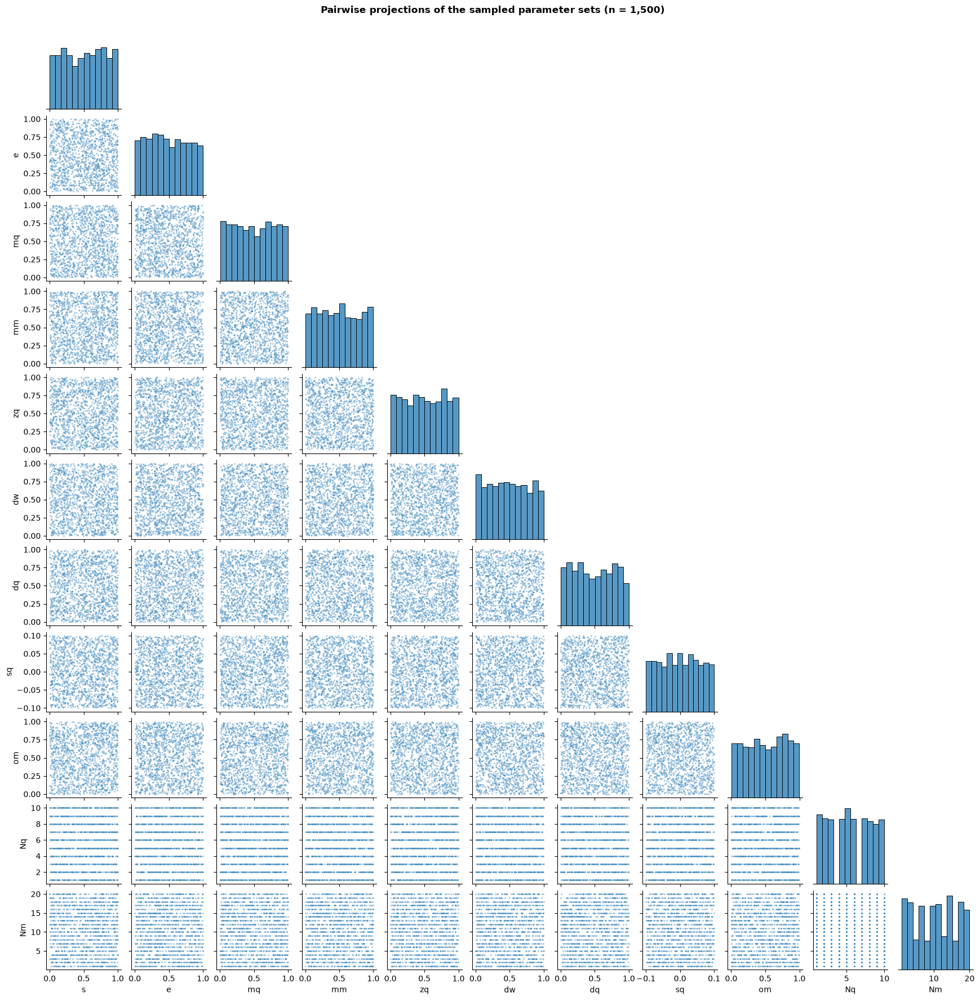

In [12]:
### --- Pairwise Coverage of the Feature Space --- ###
sample_for_pairplot = X.sample(n = 1500, random_state = random_seed)
g = sns.pairplot(sample_for_pairplot, corner = True, diag_kind = 'hist',
                 plot_kws = {'s': 5, 'alpha': 0.4}, height = 1.6)
g.figure.suptitle('Pairwise projections of the sampled parameter sets (n = 1,500)', y = 1.01, fontweight = 'bold')
plt.show()

> **Takeaway.** Every two-dimensional projection is filled evenly, with no empty region and no visible dependence between parameters. The stripes for `Nq` and `Nm` come from the fact that they are integer counts.

### **6.2 How Uniform Is the Design?**

Random sampling leaves gaps and clusters. The **centered discrepancy** quantifies this (lower means more uniform). We compare our design with three references of the same size (2048 points) in the nine continuous dimensions: independent random uniform draws, a Latin hypercube and a scrambled Sobol sequence. The last two are *space-filling* designs that could have been used to generate the parameter sets.

In [13]:
### --- Discrepancy of Our Design Versus Reference Designs --- ###
continuous_cols = [c for c in feature_cols if c not in ('Nq', 'Nm')]   # 9 continuous features.
lo = np.array([PARAM_RANGES[c][0] for c in continuous_cols])
hi = np.array([PARAM_RANGES[c][1] for c in continuous_cols])

def to_unit_cube(frame):
    """Rescale the continuous features to [0, 1] with the documented ranges."""
    return ((frame[continuous_cols].to_numpy() - lo) / (hi - lo))

n_design = 2048
rng_design = np.random.default_rng(random_seed)
U_ours = to_unit_cube(X.sample(n = n_design, random_state = random_seed))

disc_random = [qmc.discrepancy(rng_design.random((n_design, len(continuous_cols)))) for _ in range(10)]
disc_table = pd.Series({
    'Our parameter sets (random subsample)': qmc.discrepancy(U_ours),
    'Independent uniform draws (mean of 10)': np.mean(disc_random),
    'Latin hypercube': qmc.discrepancy(qmc.LatinHypercube(d = len(continuous_cols), seed = random_seed).random(n_design)),
    'Scrambled Sobol sequence': qmc.discrepancy(qmc.Sobol(d = len(continuous_cols), scramble = True, seed = random_seed).random(n_design)),
}, name = 'Centered discrepancy')
display(disc_table.to_frame())

,Centered discrepancy
Our parameter sets (random subsample),0.002356
Independent uniform draws (mean of 10),0.002494
Latin hypercube,0.001284
Scrambled Sobol sequence,0.000176


> **Takeaway.** Our design behaves like independent random draws, as expected (centred discrepancy 0.0024, against 0.0025 for independent uniform draws). The space-filling designs have a clearly lower discrepancy (0.0013 for the Latin hypercube and 0.0002 for the Sobol sequence, about 2 and 13 times lower): for the same number of simulations they would have left fewer gaps. This is useful to know when deciding how to spend further simulation time (Section 15).

### **6.3 How Far Apart Are the Points?**

In nine continuous dimensions, even tens of thousands of points are sparse. The histogram shows, for every training point, the distance to its nearest neighbour in the unit cube. For reference, one cell of a grid with 10 bins per axis has a width of 0.1.

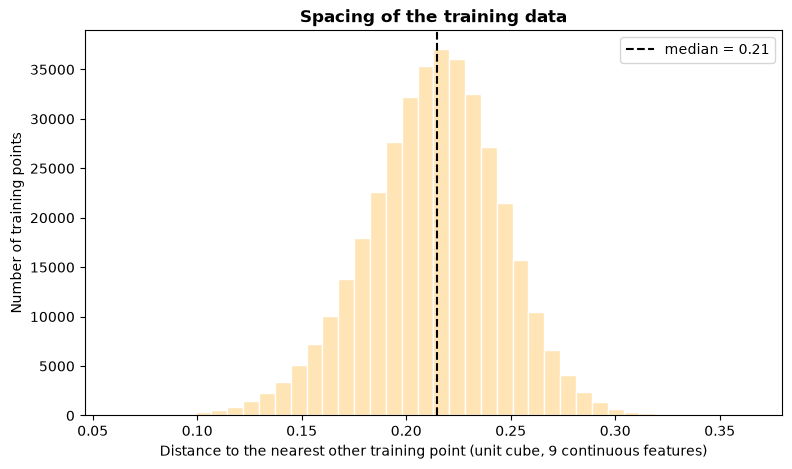

In [14]:
### --- Nearest-Neighbour Distances in the Training Set --- ###
U_train = to_unit_cube(X_train)
nn_dist = cKDTree(U_train).query(U_train, k = 2)[0][:, 1]   # k = 2: the first neighbour is the point itself.

plt.figure(figsize = (9, 5))
plt.hist(nn_dist, bins = 40, color = 'moccasin', edgecolor = 'white')
plt.axvline(np.median(nn_dist), color = 'black', linestyle = '--', label = f'median = {np.median(nn_dist):.2f}')
plt.xlabel('Distance to the nearest other training point (unit cube, 9 continuous features)')
plt.ylabel('Number of training points')
plt.title('Spacing of the training data', fontweight = 'bold')
plt.legend()
plt.show()

> **Takeaway.** One- and two-parameter effects are well supported by data, but fine structure involving many parameters at once is not: even with 377,568 training points, the median distance between neighbouring points is about 0.21, roughly twice the width of a 10-bin cell (0.1). This is why the later analyses (Section 14) concentrate on one or two parameters at a time and use bins that contain enough points.

### **6.4 Is the Test Set Drawn From the Same Region as the Training Set?**

**Adversarial validation** trains a classifier to tell training samples from test samples using only the features. If the two sets come from the same distribution, this is impossible and the cross-validated AUC stays near 0.5.

In [15]:
### --- Adversarial Validation: Train Versus Test --- ###
X_all = pd.concat([X_train, X_test])
is_test = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))].astype(int)

adv_scores = cross_val_score(
    RandomForestClassifier(n_estimators = 100, min_samples_leaf = 20, random_state = random_seed, n_jobs = -1),
    X_all, is_test, cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = random_seed), scoring = 'roc_auc')
print(f'Adversarial ROC AUC (train vs test): {adv_scores.mean():.3f} +/- {adv_scores.std():.3f}   (0.5 = indistinguishable)')

Adversarial ROC AUC (train vs test): 0.497 +/- 0.003   (0.5 = indistinguishable)


> **Takeaway.** The adversarial classifier cannot tell the training rows from the test rows (cross-validated ROC AUC 0.497 +/- 0.003, against 0.5 for indistinguishable sets). The stratified split therefore gives a test set drawn from the same region as the training set, and the test scores are representative of the whole design.


### **6.5 How Noisy Is the Label?**

A parameter set is called polymorphic if **one** replicate out of 100 kept the allele. A parameter set with `frac_polymorphic = 0.01` and one with `0.00` may differ only by chance. The table shows how many parameter sets would stay polymorphic under stricter thresholds, and the histogram shows how the positives are distributed.

,share of all parameter sets above the threshold,share of the current positives kept
threshold on frac_polymorphic,,
0.00,0.225,1.000
0.01,0.185,0.823
0.05,0.121,0.540
0.10,0.087,0.386
0.25,0.044,0.195
0.50,0.016,0.072


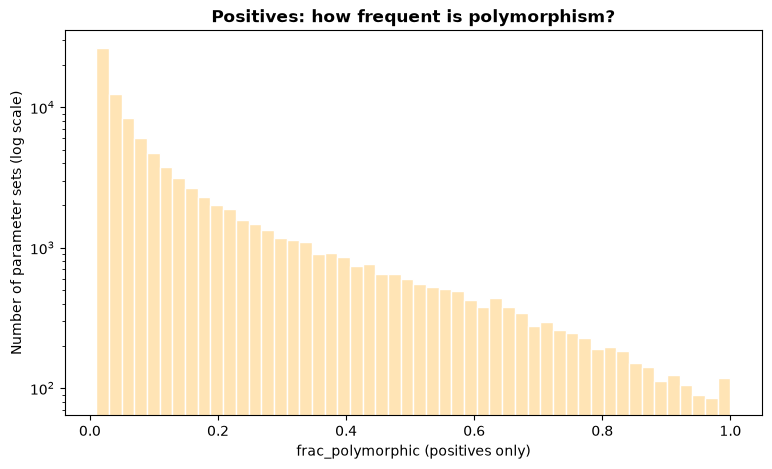

In [16]:
### --- Label Noise: How Many Positives Sit Close to the Threshold? --- ###
frac_all = df_model['frac_polymorphic']
label_noise = pd.DataFrame({
    'share of all parameter sets above the threshold': [(frac_all > t).mean() for t in [0.0, 0.01, 0.05, 0.10, 0.25, 0.50]],
    'share of the current positives kept': [(frac_all > t).sum() / (frac_all > 0).sum() for t in [0.0, 0.01, 0.05, 0.10, 0.25, 0.50]],
}, index = pd.Index([0.0, 0.01, 0.05, 0.10, 0.25, 0.50], name = 'threshold on frac_polymorphic'))
display(label_noise.round(3))

plt.figure(figsize = (9, 5))
plt.hist(frac_all[frac_all > 0], bins = 50, color = 'moccasin', edgecolor = 'white')
plt.yscale('log')
plt.xlabel('frac_polymorphic (positives only)')
plt.ylabel('Number of parameter sets (log scale)')
plt.title('Positives: how frequent is polymorphism?', fontweight = 'bold')
plt.show()

> **Takeaway.** Polymorphism is rarely strong: only 82% of the positives remain positive with a threshold of 0.01, 54% with 0.05, 39% with 0.10, 20% with 0.25 and 7% with 0.50. Nearly half of the positives (46%) have `frac_polymorphic` of 0.05 or less, i.e. the allele persisted in at most 5 replicates out of 100, and the histogram (log scale) falls steadily from its first bin. Those parameter sets sit close to the 0 / 1 boundary, where the label is partly decided by chance, so no classifier can be expected to reach 100% accuracy. Section 13.6 shows where the errors of the best model concentrate, and Section 13.7 repeats the analysis with stricter thresholds.


## **7. Modelling Strategy**

We train five classifiers in order of increasing flexibility, which also means decreasing interpretability. The goal is not only to reach a high accuracy but also to see **how much each additional level of complexity buys**, and what we lose in biological insight in exchange.

| Section | Model | Main strength |
|---|---|---|
| 8 | Logistic regression | Simple, linear baseline |
| 9 | Decision tree | Fully readable "white-box" rules |
| 10 | Random forest | Ensemble of trees, much more accurate |
| 11 | XGBoost | Gradient-boosted trees, usually the most accurate on tabular data |
| 12 | Multilayer perceptron | Neural network, can capture complex non-linearities |

### **7.1 Common Protocol**

Every model is tuned and evaluated in exactly the same way. Because polymorphic parameter sets are a minority, the protocol differs from a balanced-classes protocol on three points: the metrics, the decision threshold and the compute budget.

- **5-fold stratified cross-validation** on the training set, for every model. Each fold serves once as the **validation set**.
- **Two ranking metrics, computed for every candidate configuration**: the **ROC AUC** (how well polymorphic parameter sets are ranked above non polymorphic ones, whatever the share of positives) and the **PR AUC** (average precision: how well polymorphic parameter sets are ranked at the top, with a random classifier scoring the prevalence). The **primary metric**, which selects the configuration, is the **ROC AUC** (`PRIMARY_METRIC`, a single constant in the cell below). The PR AUC of the same configuration is always reported, and the notebook says when the configuration that would maximise it is a different one. (Accuracy is not used as a headline metric: the majority-class baseline of Section 4.3 is already high.)
- **A decision threshold chosen on out-of-fold predictions.** The five validation folds give one prediction for every training row, made by a model that has not seen that row. The threshold that maximises the **F1 score** on these predictions is kept, and **precision, recall, F1, MCC and balanced accuracy** are then reported on the test set at that threshold. The test set plays no role in the choice.
- **A two-stage search to respect the compute budget** (two CPU cores). The hyperparameter search (`RandomizedSearchCV`, or an exhaustive `GridSearchCV` for the logistic regression) runs on a **stratified subsample of `SEARCH_ROWS` training rows**. The selected configuration is then evaluated by the **same 5-fold protocol on the whole training set** and refitted on all of it. All the numbers reported below come from this second stage, never from the subsample.
- **Reported numbers**, for the selected configuration:
  - **Train**: mean score over the five training folds.
  - **Validation**: mean score (and standard deviation) over the five validation folds.
  - **Test**: score on the held-out test set, computed once, after the tuning.

  A large gap between train and validation is a sign of overfitting. A validation score that is much lower than the test score, or a large standard deviation across folds, would signal an unstable model.
- A **confusion matrix**, a **ROC curve** and a **precision-recall curve** on the test set.
- A **hyperparameter table** per model: searched values, chosen value, whether the chosen value sits at the edge of the searched range, and the reason for that range. The tables are collected in Section 13.1.

Tree-based models and neural networks overfit easily, so the search spaces were restricted to limit model complexity. When a chosen value equals the upper cap of its range, the cap is **binding** by design. The tables flag these cases explicitly.

The cell below defines the helpers that implement this protocol.

In [17]:
### --- Cross-Validation Protocol, Tuning Helper and Result Tables --- ###
CV = StratifiedKFold(n_splits = 5, shuffle = True, random_state = random_seed)    # Same 5 folds for every model.
SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'}                   # Both metrics, for every candidate.
PRIMARY_METRIC = 'roc_auc'                                                        # Metric used to pick the final configuration (PR AUC is reported too).
METRIC_LABEL = {'pr_auc': 'PR AUC', 'roc_auc': 'ROC AUC'}
SEARCH_ROWS = BUDGET['search_rows']                                               # Training rows used by the hyperparameter search.
RESULTS = {}                                                                      # Collects everything for the final tables.

prevalence_train = y_train.mean()          # PR AUC of a random classifier.
majority_baseline = 1 - prevalence_train   # Accuracy of "always not polymorphic".


def _short(param_name):
    """Remove the pipeline prefix, e.g. 'clf__C' -> 'C'."""
    return param_name.split('__')[-1]


def f1_optimal_threshold(y_true, proba):
    """Probability threshold that maximises the F1 score of the positive class."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[int(np.argmax(f1))])


def threshold_metrics(y_true, proba, threshold):
    """Precision, recall, F1, MCC and balanced accuracy of the positive class at a given threshold."""
    pred = (np.asarray(proba) >= threshold).astype(int)
    return {'precision': precision_score(y_true, pred, zero_division = 0), 'recall': recall_score(y_true, pred),
            'F1': f1_score(y_true, pred), 'MCC': matthews_corrcoef(y_true, pred),
            'balanced accuracy': balanced_accuracy_score(y_true, pred)}


def tune_model(name, estimator, param_space, rationale, n_iter = None):
    """Tune a model, evaluate it by 5-fold CV on the whole training set, refit it and store the results.

    Stage 1: hyperparameter search on a stratified subsample of SEARCH_ROWS training rows (primary metric: PR AUC).
    Stage 2: the selected configuration is cross-validated on ALL the training rows (train / validation scores,
             out-of-fold predictions for the F1-optimal threshold) and refitted on all of them.
    n_iter = None runs an exhaustive grid search, otherwise a randomised search with n_iter candidates.
    """
    if len(X_train) > SEARCH_ROWS:
        X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size = SEARCH_ROWS, stratify = y_train, random_state = random_seed)
    else:
        X_sub, y_sub = X_train, y_train

    common = dict(cv = CV, scoring = SCORING, refit = False, n_jobs = -1)
    if n_iter is None:
        search = GridSearchCV(estimator, param_space, **common)
    else:
        search = RandomizedSearchCV(estimator, param_space, n_iter = n_iter, random_state = random_seed, **common)
    search.fit(X_sub, y_sub)

    cv_res = pd.DataFrame(search.cv_results_)
    best = int(cv_res[f'rank_test_{PRIMARY_METRIC}'].idxmin())    # Configuration selected on the primary metric.
    best_params = cv_res.loc[best, 'params']
    same_config = {m: int(cv_res[f'rank_test_{m}'].idxmin()) == best for m in SCORING}

    def build():
        model = clone(estimator).set_params(**best_params)
        if 'n_jobs' in model.get_params():
            model.set_params(n_jobs = -1)                          # The search parallelises over candidates, this stage over trees.
        return model

    fold = {m: {'train': [], 'val': []} for m in SCORING}
    oof = np.zeros(len(X_train))                                   # Out-of-fold probability of every training row.
    for tr, va in CV.split(X_train, y_train):
        m = build().fit(X_train.iloc[tr], y_train.iloc[tr])
        p_tr, p_va = m.predict_proba(X_train.iloc[tr])[:, 1], m.predict_proba(X_train.iloc[va])[:, 1]
        oof[va] = p_va
        fold['pr_auc']['train'].append(average_precision_score(y_train.iloc[tr], p_tr))
        fold['pr_auc']['val'].append(average_precision_score(y_train.iloc[va], p_va))
        fold['roc_auc']['train'].append(roc_auc_score(y_train.iloc[tr], p_tr))
        fold['roc_auc']['val'].append(roc_auc_score(y_train.iloc[va], p_va))

    model = build().fit(X_train, y_train)
    p_test = model.predict_proba(X_test)[:, 1]
    metrics = {m: {'train': np.mean(fold[m]['train']), 'val': np.mean(fold[m]['val']), 'val_sd': np.std(fold[m]['val'])} for m in SCORING}
    metrics['pr_auc']['test'] = average_precision_score(y_test, p_test)
    metrics['roc_auc']['test'] = roc_auc_score(y_test, p_test)

    threshold = f1_optimal_threshold(y_train, oof)
    RESULTS[name] = dict(model = model, space = param_space, rationale = rationale, best_params = best_params, metrics = metrics,
                         search_cv = cv_res, search_rows = len(X_sub), same_config = same_config, threshold = threshold, oof = oof,
                         thr_oof = threshold_metrics(y_train, oof, threshold), thr_test = threshold_metrics(y_test, p_test, threshold))
    show_metrics(name)
    return model


def show_metrics(name):
    """Print the train / validation / test table of a tuned model, and its threshold-based metrics."""
    r = RESULTS[name]
    m = r['metrics']
    table = pd.DataFrame({
        'PR AUC':  [m['pr_auc']['train'], m['pr_auc']['val'], m['pr_auc']['val_sd'], m['pr_auc']['test']],
        'ROC AUC': [m['roc_auc']['train'], m['roc_auc']['val'], m['roc_auc']['val_sd'], m['roc_auc']['test']],
    }, index = ['Train (mean of the 5 training folds)', 'Validation (mean of the 5 validation folds)',
                'Validation (sd across the 5 folds)', 'Test (held-out set)'])
    print(f'--- {name}: {len(r["search_cv"])} configuration(s) x 5 folds searched on {r["search_rows"]:,} rows, '
          f'selected on {METRIC_LABEL[PRIMARY_METRIC]}; scores below: 5-fold CV on all {len(X_train):,} training rows ---')
    print('Selected hyperparameters:', {_short(k): v for k, v in r['best_params'].items()})
    display(table.round(4))
    print(f'Random classifier: PR AUC = {prevalence_train:.3f}  |  ROC AUC = 0.500')
    thr_table = pd.DataFrame({'out-of-fold (training rows)': r['thr_oof'], 'test set': r['thr_test']}).T
    print(f'Decision threshold maximising the F1 on the out-of-fold predictions: {r["threshold"]:.3f}')
    display(thr_table.round(3))
    for metric, same in r['same_config'].items():
        if not same:
            i = int(r['search_cv'][f'rank_test_{metric}'].idxmin())
            print(f'Note: the configuration with the best search {METRIC_LABEL[metric]} differs from the selected one: '
                  f'{ {_short(k): v for k, v in r["search_cv"].loc[i, "params"].items()} } '
                  f'(search PR AUC {r["search_cv"].loc[i, "mean_test_pr_auc"]:.4f}, search ROC AUC {r["search_cv"].loc[i, "mean_test_roc_auc"]:.4f}).')


def hyperparam_table(name):
    """Searched values, chosen value, edge-of-range flag and reason for every hyperparameter of a model."""
    r = RESULTS[name]
    chosen_all = {_short(k): v for k, v in r['best_params'].items()}
    rows = []
    for key, values in r['space'].items():
        p = _short(key)
        values = list(values)
        chosen = chosen_all[p]
        numeric = all(isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, bool) for v in values)
        edge = ''
        if numeric and len(values) > 1:
            if chosen == max(values):
                edge = 'at upper cap'
            elif chosen == min(values):
                edge = 'at lower bound'
        searched = f'{min(values)} to {max(values)} ({len(values)} values)' if numeric and len(values) > 6 else str(values)
        rows.append({'Model': name, 'Hyperparameter': p, 'Searched values': searched,
                     'Chosen': chosen, 'Edge of range': edge, 'Why this range': r['rationale'].get(p, '')})
    return pd.DataFrame(rows)

> **Note on the preprocessing.** Preprocessing is part of the model. The logistic regression and the MLP are `Pipeline` objects (min-max scaling, then the classifier), so the scaler is re-fitted on the training part of every fold. The tree-based models take the raw features directly.

## **8. Logistic Regression**

We start simple with a **logistic regression**. It is a linear model: it can only capture relationships in which each feature pushes the log-odds of polymorphism steadily in one direction, so it makes a good baseline.

Its only tunable hyperparameter is `C`, the inverse of the regularisation strength (a larger `C` means weaker regularisation). We search over six values on a logarithmic scale, from very strong shrinkage to almost none. With only six candidates, the search is **exhaustive** (`GridSearchCV`) and uses the common 5-fold protocol.

In [18]:
### --- Best Logistic Regression Model --- ###
lr_pipeline = Pipeline([
    ('scale', MinMaxScaler()),                                           # Fitted inside every CV training fold.
    ('clf', LogisticRegression(max_iter = 2000, random_state = random_seed)),
])
lr_space = {'clf__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
lr_rationale = {
    'C': 'Inverse regularisation strength, on a log scale. 0.001 = very strong L2 shrinkage (underfitting risk), '
         '100 = almost none. Only 6 values, so every one is tried (grid search).',
}

best_log_reg_model = tune_model('Logistic Regression', lr_pipeline, lr_space, lr_rationale, n_iter = None)
display(hyperparam_table('Logistic Regression'))

--- Logistic Regression: 6 configuration(s) x 5 folds searched on 40,000 rows, selected on ROC AUC; scores below: 5-fold CV on all 377,568 training rows ---
Selected hyperparameters: {'C': 10.0}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.4229,0.7548
Validation (mean of the 5 validation folds),0.4229,0.7547
Validation (sd across the 5 folds),0.0013,0.0012
Test (held-out set),0.4304,0.7568


Random classifier: PR AUC = 0.225  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.216


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.378,0.718,0.495,0.316,0.687
test set,0.379,0.715,0.496,0.317,0.688


Note: the configuration with the best search PR AUC differs from the selected one: {'C': 0.001} (search PR AUC 0.4226, search ROC AUC 0.7526).


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Logistic Regression,C,"[0.001, 0.01, 0.1, 1.0, 10.0, 100.0]",10.0,,"Inverse regularisation strength, on a log scal..."


Because the features were min-max scaled, the coefficients below are directly comparable: each one is the change in log-odds when the feature goes from the bottom to the top of its range, the other features being fixed. A linear model can only describe such monotone, additive effects. The largest coefficients are those of `e` (about -2.7) and `zq` (about -1.6), which lower the log-odds, and `s`, `om` and `Nq` (about +1.0, +1.0 and +0.7), which raise it. All the other coefficients are close to zero, including `sq` (about 0.04), although `sq` is one of the two most important parameters of the tree-based models (Section 14.2): its effect is not monotone (the allele is most likely to be maintained when `sq` is close to 0, Section 14.3), and a straight line cannot represent a peak.


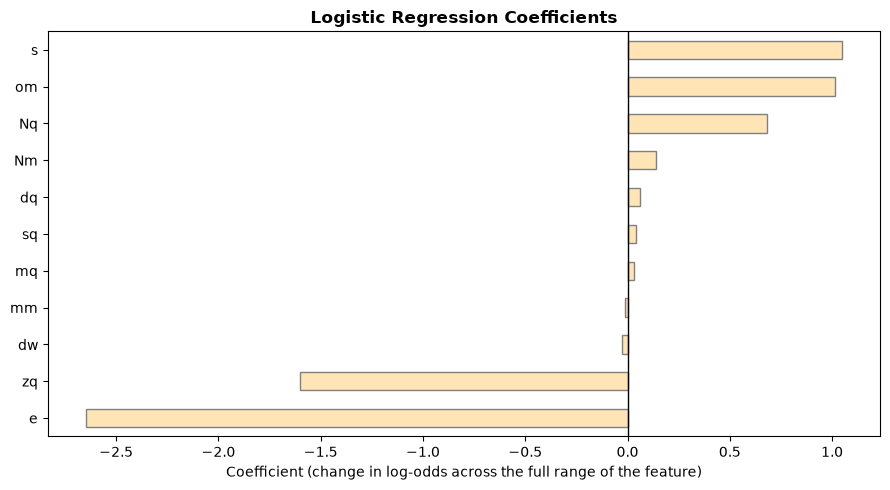

In [19]:
### --- Coefficients of the Logistic Regression (Scaled Features) --- ###
lr_coefs = pd.Series(best_log_reg_model.named_steps['clf'].coef_[0], index = feature_cols).sort_values()
plt.figure(figsize = (9, 5))
lr_coefs.plot(kind = 'barh', color = 'moccasin', edgecolor = 'gray')
plt.axvline(0, color = 'black', linewidth = 1)
plt.xlabel('Coefficient (change in log-odds across the full range of the feature)')
plt.title('Logistic Regression Coefficients', fontweight = 'bold')
plt.tight_layout()
plt.show()

The train and validation scores are identical (PR AUC 0.423 in both, ROC AUC 0.755 in both) and the test scores are close (0.430 and 0.757): the model does not overfit, and the limit comes from the model, which is too simple, rather than from the data. It does extract some signal, since its PR AUC is about 1.9 times that of a random classifier (0.225), but at the F1-optimal threshold (0.216) it reaches a precision of only 0.38 for a recall of 0.72. The choice of `C` is not what limits it: even a very different regularisation (`C = 0.001`, which maximises the PR AUC on the search subsample) gives almost the same scores there (PR AUC 0.4226, ROC AUC 0.7526).

### **8.1 Confusion Matrix**


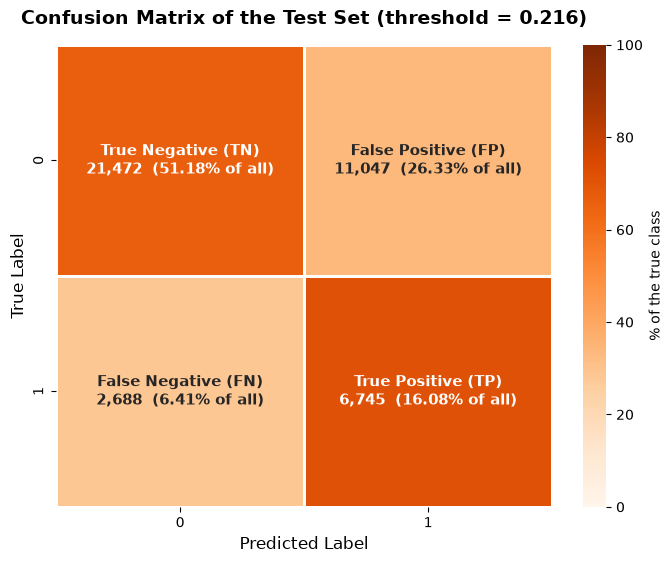

In [20]:
### --- Confusion Matrix for Logistic Regression --- ###
plot_confusion_matrix(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Logistic Regression']['threshold'])

### **8.2 ROC and Precision-Recall Curves**

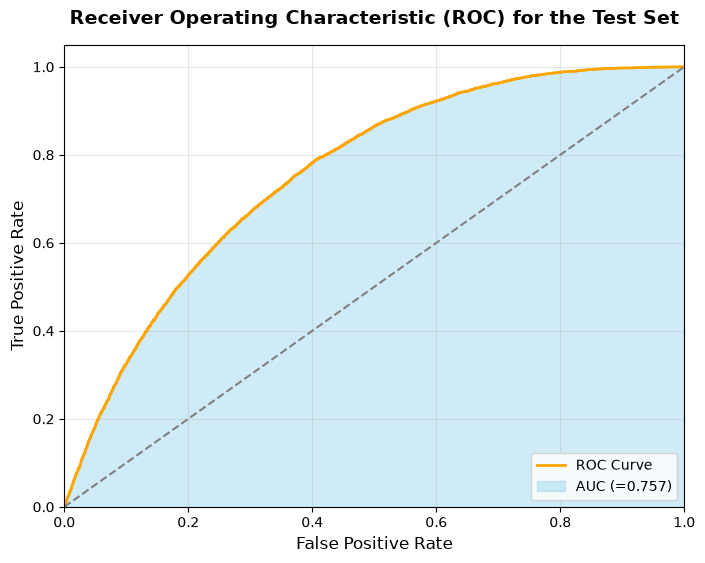

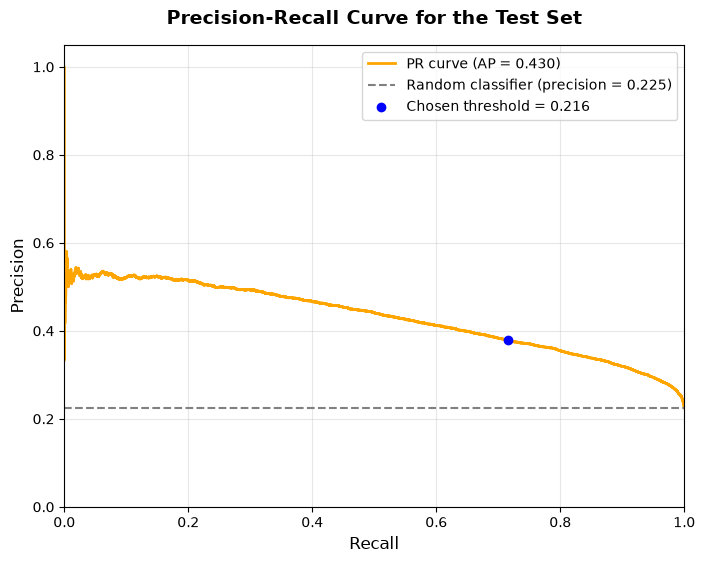

In [21]:
### --- ROC Curve for Logistic Regression --- ###
plot_roc(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_log_reg_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Logistic Regression']['threshold'])

> **Takeaway.** The logistic regression is the linear baseline, and a weak one: a test ROC AUC of 0.757 and a PR AUC of 0.430 (random classifier: 0.225), with identical train and validation scores, so it underfits. It cannot represent interactions, thresholds or peaks, and the near-zero coefficient of `sq` shows what that costs. The much higher scores of the next models show that most of the signal is **non-linear**. We explore it with a decision tree.


## **9. Decision Tree**

A **decision tree** repeatedly splits the data with simple threshold rules on one feature at a time, so it can capture non-linear effects and interactions. Trees tend to **overfit**: a default, unrestricted tree memorises the training set.

To limit this, the search combines two strategies:

- Limits on the **size of the tree** (depth, minimum leaf size) and on the number of features examined per split.
- **Cost-complexity pruning** (`ccp_alpha`), which removes branches that add little accuracy. It is now **part of the search** (it used to be fixed), so that the pruning strength is chosen on the validation folds like every other hyperparameter.

The search tests 60 random combinations with the common protocol (search on a subsample, then 5-fold evaluation on the whole training set, Section 7.1).

In [22]:
### --- Best Decision Tree --- ###
dt_space = {
    'max_depth': [12, 13, 14],                          # Bridges Run 3 (11) and Run 2 (15)
    'min_samples_leaf': [20, 25, 30],                   # Centers on the proven sweet spot of 20
    'min_samples_split': [50, 65, 80],                  # Bridges Run 2 (50) and Run 3 (100)
    'max_features': [0.8],                              # Locked in from consistent wins
    'criterion': ['entropy'],                           # Locked in from consistent wins
    'ccp_alpha': [1e-5, 2e-5, 3e-5, 4e-5],              # Fine-grained steps between 1e-5 and 5e-5
}

dt_rationale = {
    'max_depth': 'Targets 12 to 14 to retain multi-feature interactions from Run 2 while capping leaf growth.',
    'min_samples_leaf': 'Keeps the floor at 20 (which unlocked Run 2 performance) and tests slightly higher stability at 25 and 30.',
    'min_samples_split': 'Bridges the gap between 50 and 100 to prune noisy sub-branches without choking the 40k search sample.',
    'max_features': 'Fixed at 0.8, which repeatedly outperformed full features and smaller subsets.',
    'criterion': 'Fixed at entropy, which consistently outperformed gini on this dataset.',
    'ccp_alpha': 'Explores fine increments between 1e-5 (Run 2) and 5e-5 (Run 3) to shave off overfitting without losing signal.',
}

best_model_dt = tune_model('Decision Tree', DecisionTreeClassifier(random_state = random_seed),
                           dt_space, dt_rationale, n_iter = BUDGET['n_iter']['Decision Tree'])
display(hyperparam_table('Decision Tree'))
print(f'Selected tree: depth {best_model_dt.get_depth()}, {best_model_dt.get_n_leaves()} leaves.')

--- Decision Tree: 60 configuration(s) x 5 folds searched on 40,000 rows, selected on ROC AUC; scores below: 5-fold CV on all 377,568 training rows ---
Selected hyperparameters: {'min_samples_split': 80, 'min_samples_leaf': 20, 'max_features': 0.8, 'max_depth': 14, 'criterion': 'entropy', 'ccp_alpha': 1e-05}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.8944,0.9680
Validation (mean of the 5 validation folds),0.8405,0.9463
Validation (sd across the 5 folds),0.0025,0.0006
Test (held-out set),0.8402,0.9472


Random classifier: PR AUC = 0.225  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.413


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.742,0.809,0.774,0.706,0.864
test set,0.738,0.811,0.773,0.704,0.864


Note: the configuration with the best search PR AUC differs from the selected one: {'min_samples_split': 50, 'min_samples_leaf': 25, 'max_features': 0.8, 'max_depth': 13, 'criterion': 'entropy', 'ccp_alpha': 4e-05} (search PR AUC 0.7583, search ROC AUC 0.9117).


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Decision Tree,max_depth,"[12, 13, 14]",14,at upper cap,Targets 12 to 14 to retain multi-feature inter...
1,Decision Tree,min_samples_leaf,"[20, 25, 30]",20,at lower bound,Keeps the floor at 20 (which unlocked Run 2 pe...
2,Decision Tree,min_samples_split,"[50, 65, 80]",80,at upper cap,Bridges the gap between 50 and 100 to prune no...
3,Decision Tree,max_features,[0.8],0.8,,"Fixed at 0.8, which repeatedly outperformed fu..."
4,Decision Tree,criterion,['entropy'],entropy,,"Fixed at entropy, which consistently outperfor..."
5,Decision Tree,ccp_alpha,"[1e-05, 2e-05, 3e-05, 4e-05]",0.00001,at lower bound,Explores fine increments between 1e-5 (Run 2) ...


Selected tree: depth 14, 2202 leaves.


### **9.1 The Tree Itself**

Each box shows a rule, the number of samples, the class distribution and the majority class (colour). Reading the tree from the root to a leaf gives a set of conditions under which polymorphism is, or is not, predicted. Only the first four levels are drawn, to keep the figure readable.

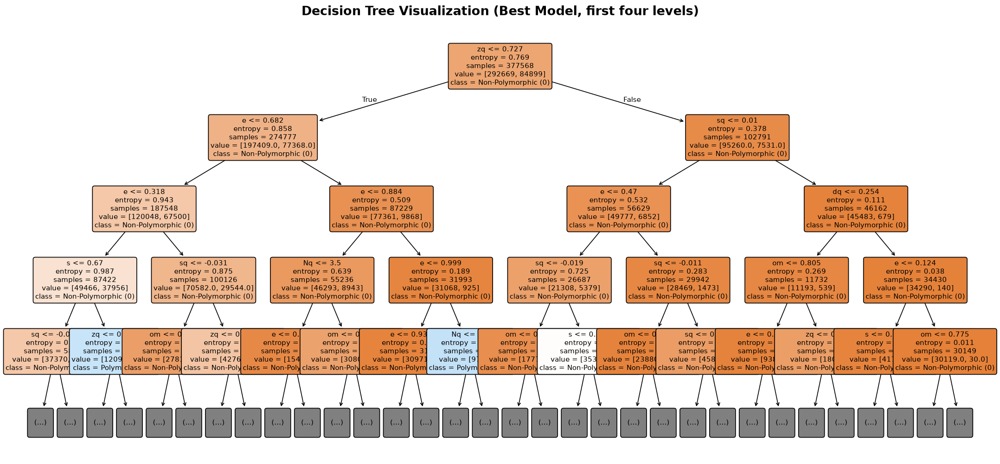

In [23]:
### --- Plot the Decision Tree (first four levels) --- ###
plt.figure(figsize = (22, 10), dpi = 120)
plot_tree(
    best_model_dt,
    feature_names = feature_cols,
    class_names = ['Non-Polymorphic (0)', 'Polymorphic (1)'],
    filled = True,          # Colors nodes by majority class
    rounded = True,         # Rounds the node boxes for a clean look
    max_depth = 4,          # Draw only the first four levels.
    fontsize = 9,
)
plt.title("Decision Tree Visualization (Best Model, first four levels)", fontsize = 16, fontweight = 'bold', pad = 20)
plt.show()

The selected tree is deep (14 levels, 2,202 leaves), so only its top levels can be read: they show which parameters are used first and which thresholds matter, but the full tree is not a short set of rules. Its test PR AUC (0.840) and ROC AUC (0.947) are far above those of the logistic regression (0.430 and 0.757) but clearly below those of the ensembles (Table 2), and the gap between train and validation (PR AUC 0.894 against 0.841) shows that some overfitting remains despite the pruning, so we keep going with ensembles.

### **9.2 Confusion Matrix**


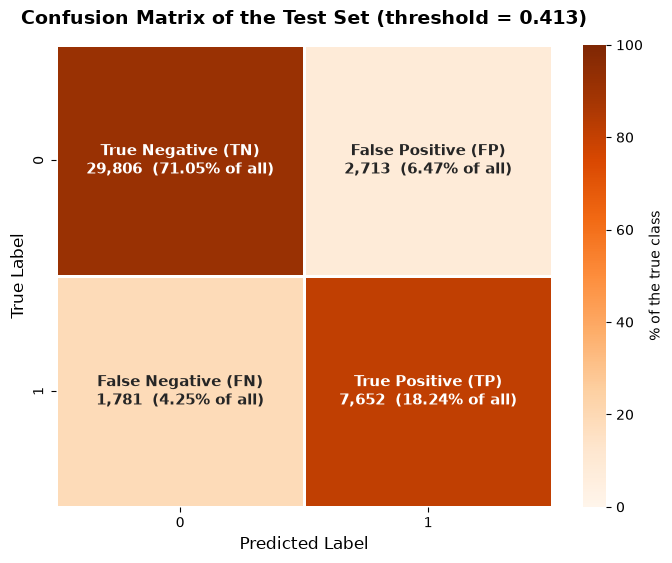

In [24]:
### --- Confusion Matrix for Decision Tree --- ###
plot_confusion_matrix(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Decision Tree']['threshold'])

### **9.3 ROC and Precision-Recall Curves**

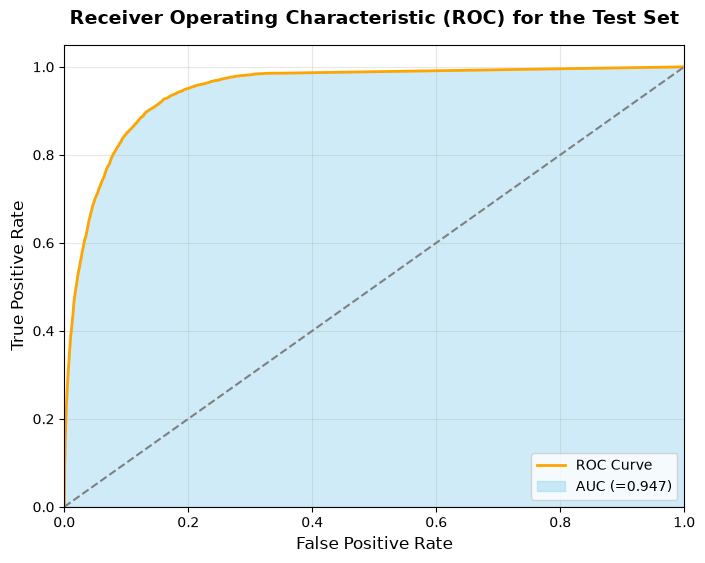

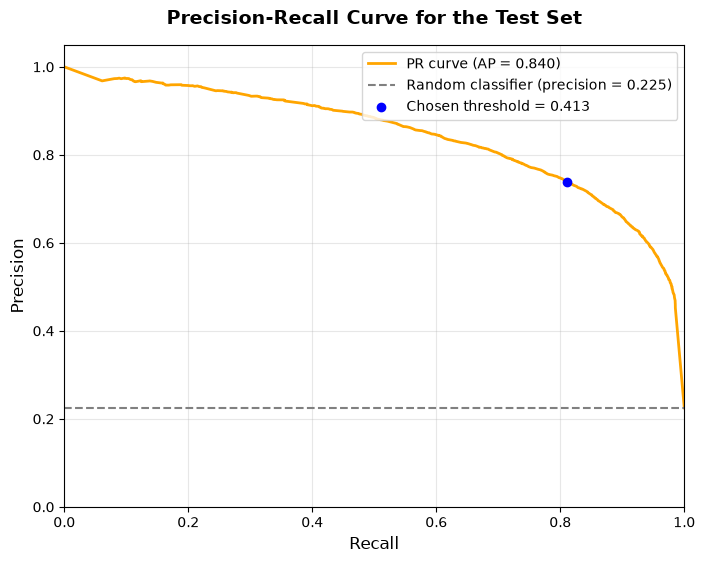

In [25]:
### --- ROC Curve for Decision Tree --- ###
plot_roc(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_model_dt, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Decision Tree']['threshold'])

> **Takeaway.** The decision tree can use thresholds and interactions, and it is also a **white-box model**: its rules can be read and translated into biological statements. Going from the logistic regression to a tree raises the test PR AUC from 0.430 to 0.840 and the F1 from 0.496 to 0.773 (precision 0.738 and recall 0.811 at its threshold of 0.413), so a large part of the signal is non-linear. The price is a tree with 2,202 leaves, which cannot be read as a whole, and a train-validation gap of 0.05 PR AUC. Ensembles improve its accuracy further, at the price of this readability.


## **10. Random Forest**

A **random forest** is an ensemble of decision trees. Each tree is trained on a bootstrap sample of the data and considers only a random subset of the features at each split, and the final prediction is the **average vote** of all the trees. Averaging many different trees reduces the variance of a single tree and usually gives a more accurate and stable model.

Random forests can overfit too (a default forest memorises the training set), so the search space limits the complexity of the trees:

- **Limited depth** (`max_depth` up to 12), which stops the trees from memorising the data and bounds the cost. This cap is a **deliberate regularisation choice**: if the selected depth equals 12, the cap is binding and the table says so.
- **Large leaves and splits** (`min_samples_split`, `min_samples_leaf`), which prevent tiny, hyper-specific groups.
- **Feature subsampling** (`max_features`), which adds diversity between the trees.

The search uses 30 random combinations and the common protocol of Section 7.1.

In [26]:
### --- Best Random Forest --- ###
rf_space = {
    'n_estimators': [100, 200],                       # 100 is plenty, but test 200 to check stability
    'max_depth': [10, 12, 14, 16],                    # Push past the 12 cap to see if deeper trees help
    'min_samples_split': [30, 40, 50],                # Center around the successful 40 choice
    'min_samples_leaf': [10, 20, 30],                 # Center around 10, test slightly higher for safety
    'max_features': [0.4, 0.5, 'sqrt'],               # Explore around 0.5 feature fraction
}

rf_rationale = {
    'n_estimators': 'Keeps 100 for speed and tests 200 to ensure ensemble convergence.',
    'max_depth': 'Raises the upper limit to 16 since depth 12 hit the cap, testing if deeper trees extract more signal.',
    'min_samples_split': 'Refines the search around the winning value of 40.',
    'min_samples_leaf': 'Keeps leaves large enough to be robust for the minority positive class (22.5% of the parameter sets).',
    'max_features': 'Tests feature fractions around 0.5 to maintain tree decorrelation.',
}
best_rf_model = tune_model('Random Forest', RandomForestClassifier(random_state = random_seed, n_jobs = 1),
                           rf_space, rf_rationale, n_iter = BUDGET['n_iter']['Random Forest'])
display(hyperparam_table('Random Forest'))

--- Random Forest: 30 configuration(s) x 5 folds searched on 40,000 rows, selected on ROC AUC; scores below: 5-fold CV on all 377,568 training rows ---
Selected hyperparameters: {'n_estimators': 200, 'min_samples_split': 30, 'min_samples_leaf': 10, 'max_features': 0.4, 'max_depth': 16}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.9711,0.9911
Validation (mean of the 5 validation folds),0.9304,0.9771
Validation (sd across the 5 folds),0.0010,0.0003
Test (held-out set),0.9318,0.9781


Random classifier: PR AUC = 0.225  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.414


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.830,0.863,0.846,0.800,0.906
test set,0.826,0.869,0.847,0.802,0.908


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Random Forest,n_estimators,"[100, 200]",200.0,at upper cap,Keeps 100 for speed and tests 200 to ensure en...
1,Random Forest,max_depth,"[10, 12, 14, 16]",16.0,at upper cap,Raises the upper limit to 16 since depth 12 hi...
2,Random Forest,min_samples_split,"[30, 40, 50]",30.0,at lower bound,Refines the search around the winning value of...
3,Random Forest,min_samples_leaf,"[10, 20, 30]",10.0,at lower bound,Keeps leaves large enough to be robust for the...
4,Random Forest,max_features,"[0.4, 0.5, 'sqrt']",0.4,,Tests feature fractions around 0.5 to maintain...


The forest overfits less than the tree but still somewhat: the train PR AUC is 0.971 against 0.930 on the validation folds (ROC AUC 0.991 against 0.977). The validation and test scores agree closely (PR AUC 0.930 and 0.932, ROC AUC 0.977 and 0.978) and the standard deviation across folds is 0.001, which is reassuring. The forest is a clear step above the tree (test PR AUC 0.932 against 0.840; F1 0.847 at a threshold of 0.414). Several chosen values sit at the edge of their range (200 trees, depth 16, `min_samples_split` 30, `min_samples_leaf` 10; Table 1), so a wider search could still improve it.

### **10.1 Confusion Matrix**


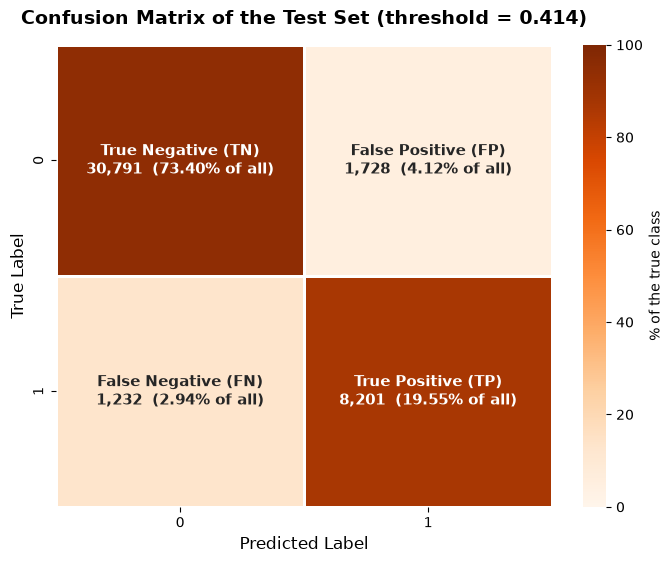

In [27]:
### --- Confusion Matrix for Random Forest --- ###
plot_confusion_matrix(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Random Forest']['threshold'])

### **10.2 ROC and Precision-Recall Curves**

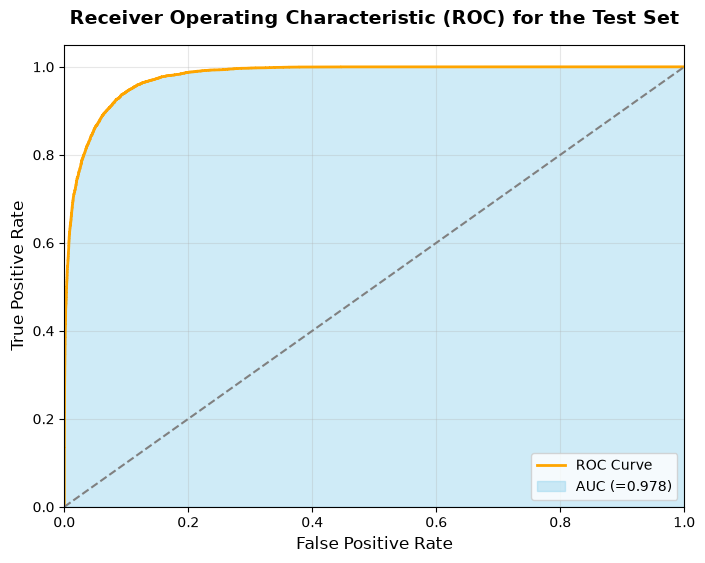

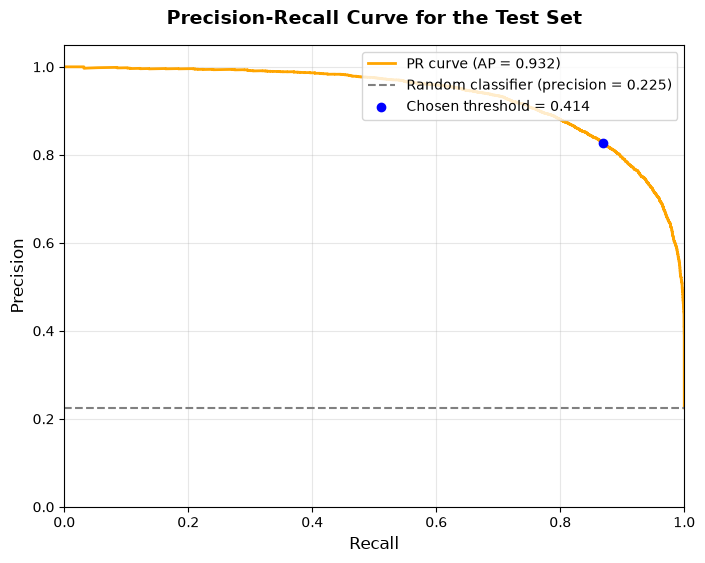

In [28]:
### --- ROC Curve for Random Forest --- ###
plot_roc(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_rf_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Random Forest']['threshold'])

### **10.3 Feature Importance**

The plot below ranks the features by their contribution to the splits of the forest. It tells us **which features the model relies on** to classify. Such a plot is reliable here because the features are uncorrelated by design (Section 4.5), and because all of them are numeric (impurity-based importances favour features with many distinct values, which is not an issue when every feature is continuous or counts).

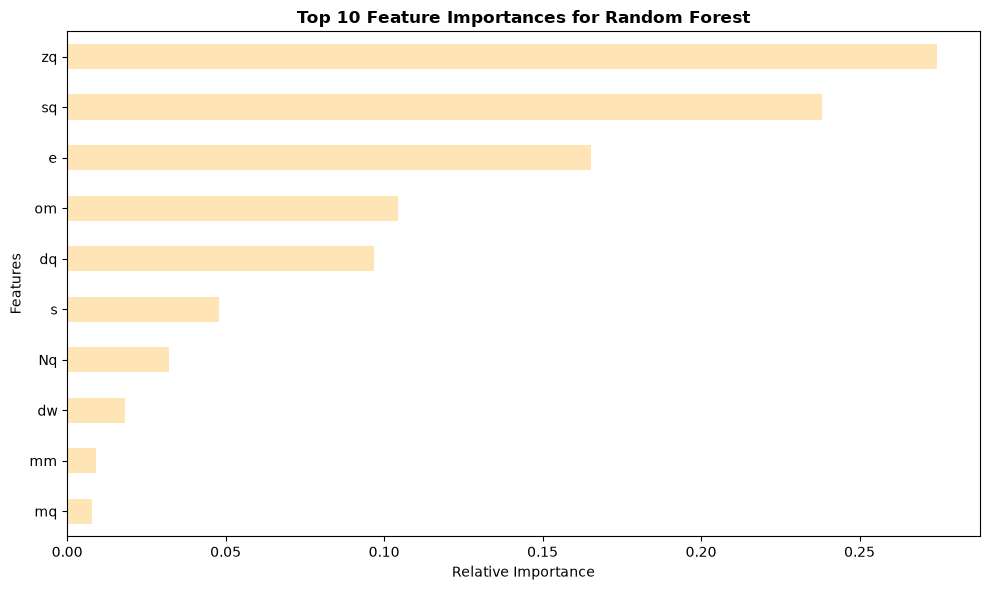

In [29]:
### --- Feature Importance Plot for Random Forest --- ###
feat_imp_plot(model = best_rf_model, feature_names = feature_cols, model_name = 'Random Forest')

> **Takeaway.** The forest relies mostly on `zq`, `sq` and `e`, then on `om` and `dq`, followed by `s` and `Nq`; `dw`, `mm` and `mq` are almost unused (`Nm` is not among the ten bars shown). The importance plot says *which* features matter, not *how* they act, nor whether they interact. Both questions come back in Section 14.


## **11. XGBoost**

**XGBoost** (eXtreme Gradient Boosting) also builds an ensemble of trees, but in a different way from the random forest. The trees are trained **sequentially**, each one correcting the errors of the previous ones (**gradient boosting**). It often outperforms a random forest on tabular data.

Boosting overfits easily, so the search space contains several regularisation levers: a small learning rate (step-size shrinkage), subsampling of the rows and columns for every tree, a minimum child weight, and L1 (`reg_alpha`) and L2 (`reg_lambda`) penalties. The ranges include small values of `min_child_weight` on purpose: the hessian of a row is at most 0.25 (it is p(1 - p)) and is close to 0 for rows that the model already predicts with confidence, so a high minimum would forbid many useful leaves (see Table 1). When a chosen value sits at the edge of its range, the table flags it. The search uses 40 random combinations and the common protocol of Section 7.1.

In [30]:
### --- Best eXtreme Gradient Boosting --- ###
xgb_space = {
    'n_estimators': [1000, 1500, 2000],               # Pushes past the 1000 cap to handle lower learning rates
    'max_depth': [5, 6, 7, 8],                        # Focuses on proven depth sweet spots
    'learning_rate': [0.005, 0.01, 0.02],             # Explores finer step-sizes below 0.02
    'subsample': [0.8, 0.9],                          # Retains strong row sampling
    'colsample_bytree': [0.7, 0.9],                   # Maintains feature decorrelation
    'min_child_weight': [3, 5],                       # Prevents leaves from isolating tiny subsets
    'reg_alpha': [1, 2],                              # Fine-tunes L1 sparsity penalty
    'reg_lambda': [1, 2],                             # Fine-tunes L2 leaf smoothing
}

xgb_rationale = {
    'n_estimators': 'Increased up to 2000 to give slower learning rates enough rounds to fully converge.',
    'max_depth': 'Restricted to 5-8 to avoid deep single-tree overfitting while capturing multi-feature interactions.',
    'learning_rate': 'Explores ultra-fine steps (0.005 and 0.01) for maximum generalisation power.',
    'subsample': 'Keeps high row fractions to ensure each tree sees plenty of data.',
    'colsample_bytree': 'Keeps feature subsampling high to prevent overly restricted trees.',
    'min_child_weight': 'Maintains structural regularization for the minority positive class (22.5% of the parameter sets).',
    'reg_alpha': 'Refines L1 regularization around the winning value of 1.',
    'reg_lambda': 'Refines L2 regularization around the winning value of 1.',
}

best_xgb_model = tune_model('XGBoost', XGBClassifier(random_state = random_seed, eval_metric = 'logloss', n_jobs = 1),
                            xgb_space, xgb_rationale, n_iter = BUDGET['n_iter']['XGBoost'])
display(hyperparam_table('XGBoost'))

--- XGBoost: 40 configuration(s) x 5 folds searched on 40,000 rows, selected on ROC AUC; scores below: 5-fold CV on all 377,568 training rows ---
Selected hyperparameters: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 2000, 'min_child_weight': 3, 'max_depth': 7, 'learning_rate': 0.02, 'colsample_bytree': 0.9}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.9808,0.9942
Validation (mean of the 5 validation folds),0.9577,0.9866
Validation (sd across the 5 folds),0.0011,0.0003
Test (held-out set),0.9576,0.9868


Random classifier: PR AUC = 0.225  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.458


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.878,0.893,0.886,0.852,0.929
test set,0.876,0.897,0.886,0.853,0.930


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,XGBoost,n_estimators,"[1000, 1500, 2000]",2000.00,at upper cap,Increased up to 2000 to give slower learning r...
1,XGBoost,max_depth,"[5, 6, 7, 8]",7.00,,Restricted to 5-8 to avoid deep single-tree ov...
2,XGBoost,learning_rate,"[0.005, 0.01, 0.02]",0.02,at upper cap,Explores ultra-fine steps (0.005 and 0.01) for...
3,XGBoost,subsample,"[0.8, 0.9]",0.80,at lower bound,Keeps high row fractions to ensure each tree s...
4,XGBoost,colsample_bytree,"[0.7, 0.9]",0.90,at upper cap,Keeps feature subsampling high to prevent over...
5,XGBoost,min_child_weight,"[3, 5]",3.00,at lower bound,Maintains structural regularization for the mi...
6,XGBoost,reg_alpha,"[1, 2]",1.00,at lower bound,Refines L1 regularization around the winning v...
7,XGBoost,reg_lambda,"[1, 2]",1.00,at lower bound,Refines L2 regularization around the winning v...


**Reading the XGBoost results.** XGBoost improves on the forest on both metrics (test PR AUC 0.958 against 0.932, ROC AUC 0.987 against 0.978, F1 0.886 at a threshold of 0.458). The train PR AUC (0.981) is above the validation one (0.958) by 0.023, a smaller gap than for the forest, and the validation and test scores are the same (0.958 and 0.958, fold standard deviation 0.001), so the model is stable. Many selected values sit at the edge of the range searched (2,000 rounds, learning rate 0.02, `colsample_bytree` 0.9, and the lower bounds of `subsample`, `min_child_weight`, `reg_alpha` and `reg_lambda`; Table 1), so a longer search could improve it further.


### **11.1 Confusion Matrix**

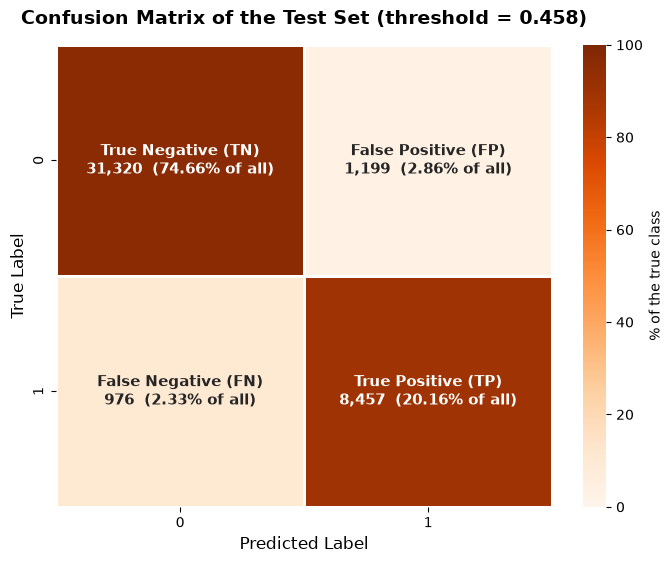

In [31]:
### --- Confusion Matrix for XGBoost --- ###
plot_confusion_matrix(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['XGBoost']['threshold'])

### **11.2 ROC and Precision-Recall Curves**

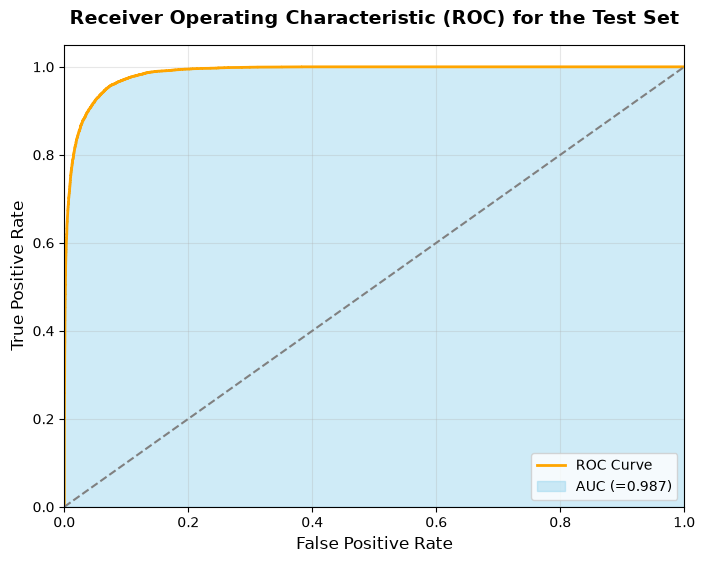

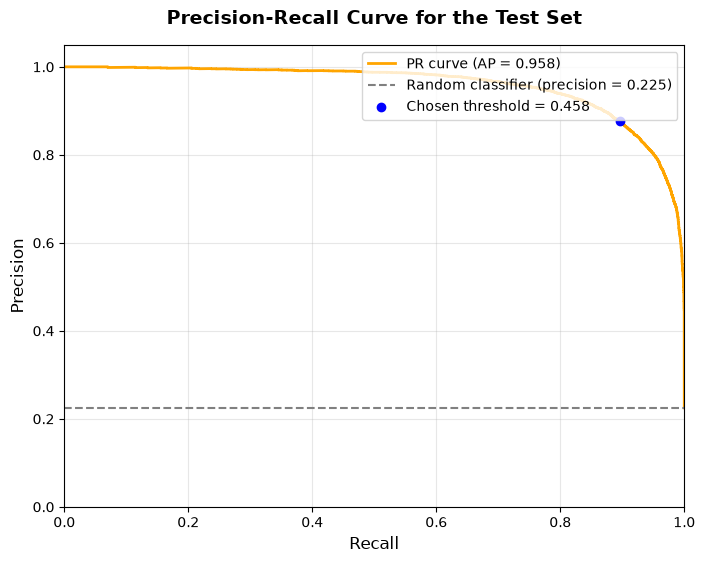

In [32]:
### --- ROC Curve for XGBoost --- ###
plot_roc(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_xgb_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['XGBoost']['threshold'])

### **11.3 Feature Importance**

As for the random forest, the features are uncorrelated, so this ranking is reliable. It is the importance used by XGBoost itself (how much each feature contributes to the splits); Section 14 gives importances that also tell the *direction* of each effect.

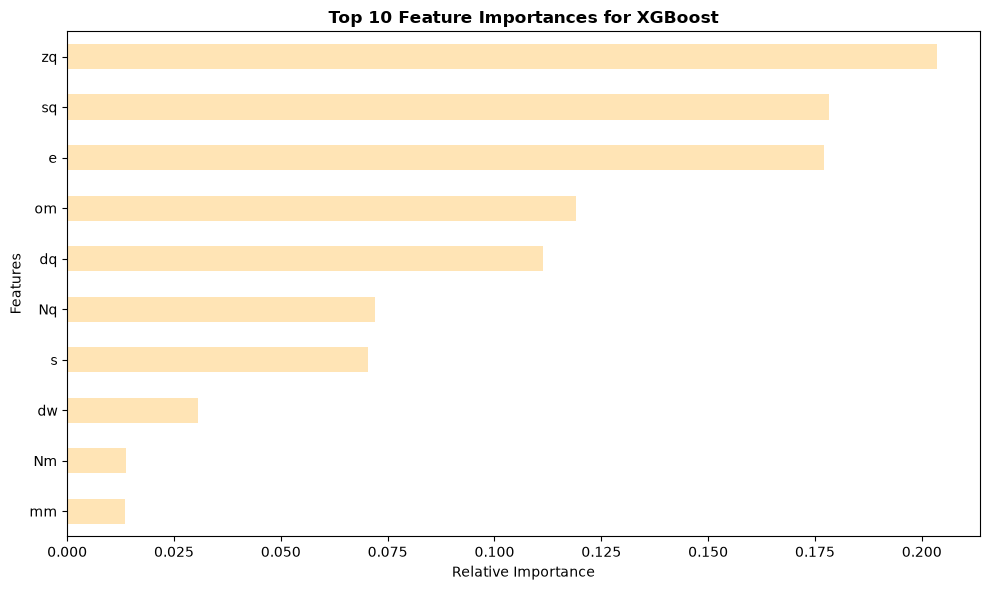

In [33]:
### --- Feature Importance Plot for XGBoost --- ###
feat_imp_plot(model = best_xgb_model, feature_names = feature_cols, model_name = 'XGBoost')

## **12. Multilayer Perceptron**

As a last model, we train a **multilayer perceptron** (MLP), a feed-forward neural network. It can represent very flexible non-linear relationships, but it needs more data than tree ensembles to shine and is the hardest to interpret.

The search space is **wider than in a first, over-regularised attempt**. The capacity (larger networks, up to three layers) and the weakness of the L2 penalty (`alpha` down to 1e-6) are no longer restricted by hand. Overfitting is controlled instead by **early stopping** (10% of every training fold is held out internally, training stops after 20 epochs without improvement) and by the L2 penalty being part of the search. Only the **Adam** optimiser is used: plain SGD needs its momentum and learning-rate schedule tuned and was unstable under early stopping. Features are min-max scaled inside a `Pipeline`. The search uses 24 random combinations (a neural network is the slowest model to fit on 377,568 training rows) and the common protocol of Section 7.1.

> **Note.** Some candidates in a randomised search may not converge within `max_iter`. These candidates simply obtain a low validation score and are not selected, so the `ConvergenceWarning` messages that may appear are expected. A large **standard deviation across folds** in the table below would reveal an unstable network.

In [34]:
### --- Best Multilayer Perceptron --- ###
mlp_pipeline = Pipeline([
    ('scale', MinMaxScaler()),
    ('clf', MLPClassifier(solver = 'adam', early_stopping = True, validation_fraction = 0.1,
                          n_iter_no_change = 20, random_state = random_seed)),
])
mlp_space = {
    'clf__hidden_layer_sizes': [(32,), (64,), (128,), (64, 32), (128, 64), (128, 128), (64, 64, 32)],
    'clf__activation': ['relu', 'tanh'],
    'clf__alpha': [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    'clf__learning_rate_init': [3e-4, 1e-3, 3e-3, 1e-2],
    'clf__batch_size': [128, 256, 512],
    'clf__max_iter': [200, 500],
}
mlp_rationale = {
    'hidden_layer_sizes': 'Architecture, from one layer of 32 neurons to three layers (128, 128 or 64, 64, 32). '
                          'Wide enough to model interactions between eleven inputs without hand-limiting the capacity.',
    'activation': 'ReLU (default, fast) versus tanh (smooth, often better on small tabular data).',
    'alpha': 'L2 penalty on the weights, on a log scale from almost none (1e-6) to strong (0.1). Controls overfitting together with early stopping.',
    'learning_rate_init': 'Initial step of Adam, on a log-like scale. Too small learns slowly, too large is unstable.',
    'batch_size': 'Mini-batch size. Smaller batches add noise that can help generalisation; larger ones are more stable.',
    'max_iter': 'Maximum number of epochs. Early stopping normally ends training before this limit.',
}

best_mlp_model = tune_model('Multilayer Perceptron', mlp_pipeline, mlp_space, mlp_rationale, n_iter = BUDGET['n_iter']['Multilayer Perceptron'])
display(hyperparam_table('Multilayer Perceptron'))

/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/alexisfornallaz/Desktop/Biologie UNIL/Second year/Semester 1/Machine Learning/Project/Ant Life Cycle Simulation Project/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the

--- Multilayer Perceptron: 24 configuration(s) x 5 folds searched on 40,000 rows, selected on ROC AUC; scores below: 5-fold CV on all 377,568 training rows ---
Selected hyperparameters: {'max_iter': 500, 'learning_rate_init': 0.001, 'hidden_layer_sizes': (64, 64, 32), 'batch_size': 128, 'alpha': 0.01, 'activation': 'tanh'}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.9703,0.9903
Validation (mean of the 5 validation folds),0.9679,0.9894
Validation (sd across the 5 folds),0.0007,0.0004
Test (held-out set),0.9701,0.9903


Random classifier: PR AUC = 0.225  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.466


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.892,0.906,0.899,0.870,0.937
test set,0.889,0.909,0.899,0.869,0.938


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Multilayer Perceptron,hidden_layer_sizes,"[(32,), (64,), (128,), (64, 32), (128, 64), (1...","(64, 64, 32)",,"Architecture, from one layer of 32 neurons to ..."
1,Multilayer Perceptron,activation,"['relu', 'tanh']",tanh,,"ReLU (default, fast) versus tanh (smooth, ofte..."
2,Multilayer Perceptron,alpha,"[1e-06, 1e-05, 0.0001, 0.001, 0.01, 0.1]",0.01,,"L2 penalty on the weights, on a log scale from..."
3,Multilayer Perceptron,learning_rate_init,"[0.0003, 0.001, 0.003, 0.01]",0.001,,"Initial step of Adam, on a log-like scale. Too..."
4,Multilayer Perceptron,batch_size,"[128, 256, 512]",128,at lower bound,Mini-batch size. Smaller batches add noise tha...
5,Multilayer Perceptron,max_iter,"[200, 500]",500,at upper cap,Maximum number of epochs. Early stopping norma...


**Reading the MLP results.** The network is the best model of the comparison (test PR AUC 0.970, ROC AUC 0.990, F1 0.899 at a threshold of 0.466). It is also the one that overfits least: the train PR AUC (0.970) is hardly above the validation one (0.968), the validation and test scores agree, and the fold standard deviation is 0.001. The selected architecture is the only three-layer one offered (64, 64 and 32 units, `tanh`, `alpha` = 0.01). Its `max_iter` of 500 is the upper cap of the range and some fits reached it without converging (see the warnings above), so a longer training or a wider search could still gain a little. The price is interpretability: the MLP has no readable structure, which is why Section 14 explains XGBoost, the second best model.


### **12.1 Confusion Matrix**

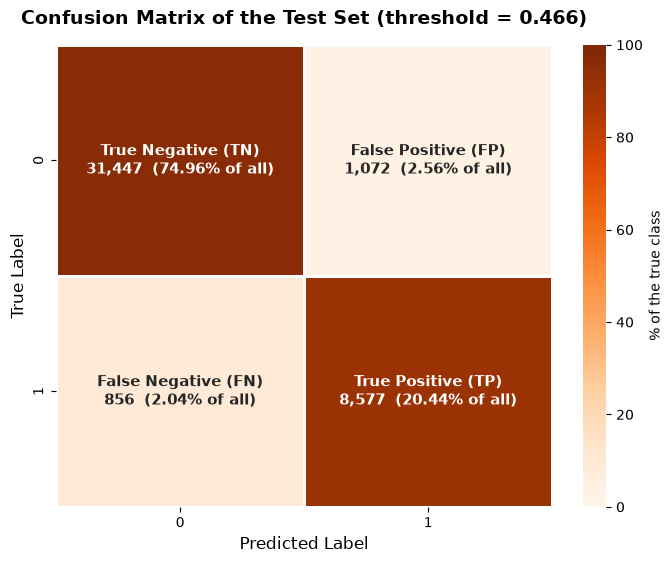

In [35]:
### --- Confusion Matrix for Multilayer Perceptron --- ###
plot_confusion_matrix(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Multilayer Perceptron']['threshold'])

### **12.2 ROC and Precision-Recall Curves**

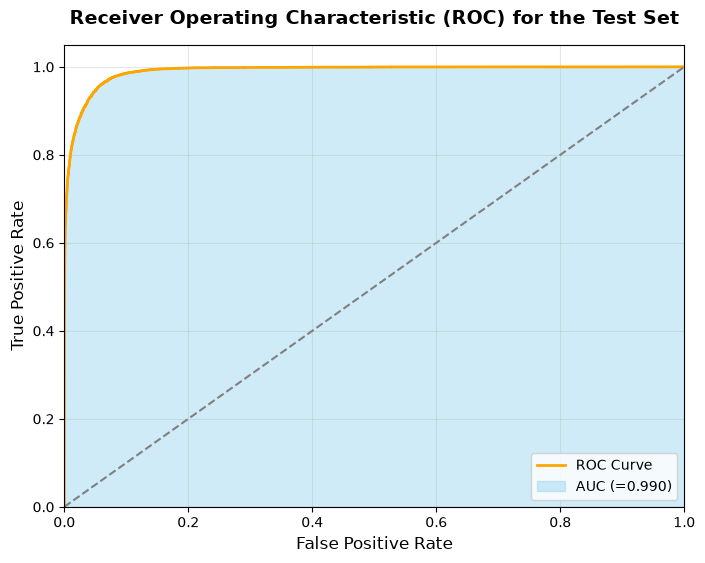

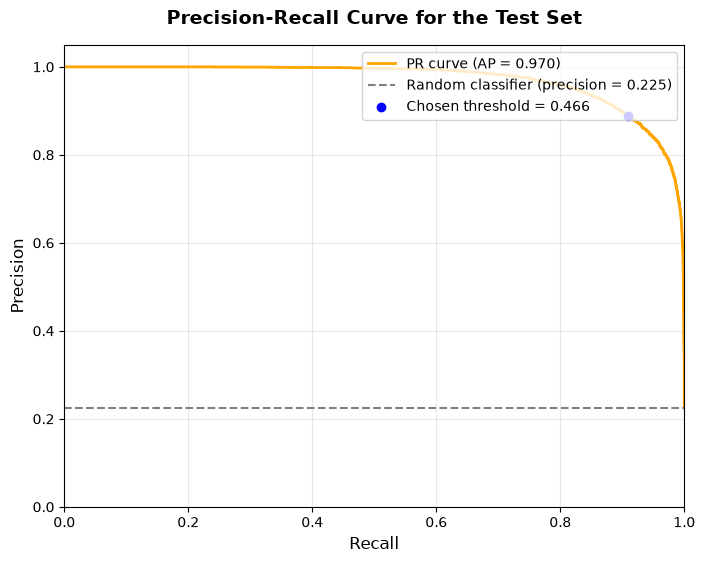

In [36]:
### --- ROC Curve for Multilayer Perceptron --- ###
plot_roc(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test")
plot_pr(model = best_mlp_model, X_set = X_test, y_set = y_test, type_of_set = "Test", threshold = RESULTS['Multilayer Perceptron']['threshold'])

### **12.3 Permutation Importance**

An MLP has no built-in feature importance. **Permutation importance** provides an equivalent: each feature is shuffled in turn on the test set, and the **drop in PR AUC** measures how much the model relied on it. The model is a `Pipeline`, so the shuffling happens on the raw features, before the scaler.

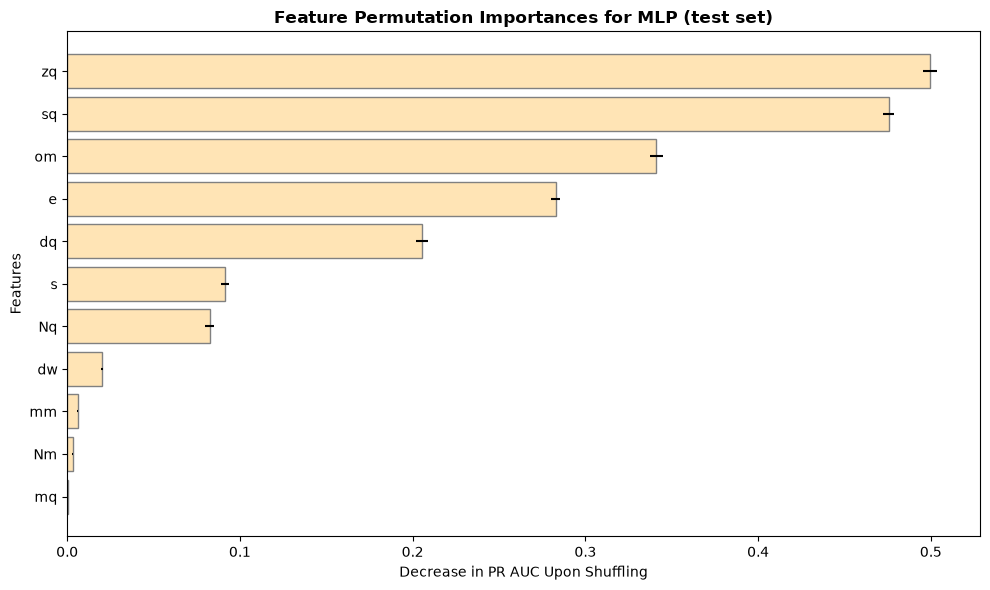

In [37]:
### --- Feature Permutation Importance Plot for Multilayer Perceptron --- ###
perm = permutation_importance(
    best_mlp_model, X_test, y_test,
    scoring = 'average_precision', n_repeats = BUDGET['perm_repeats_mlp'], random_state = random_seed, n_jobs = -1)

perm_importances = pd.Series(perm.importances_mean, index = feature_cols)
perm_sd = pd.Series(perm.importances_std, index = feature_cols)
order = perm_importances.sort_values().index
plt.figure(figsize = (10, 6))
plt.barh(order, perm_importances[order], xerr = perm_sd[order], color = 'moccasin', edgecolor = 'gray')
plt.title('Feature Permutation Importances for MLP (test set)', fontweight = 'bold')
plt.xlabel('Decrease in PR AUC Upon Shuffling')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## **13. Model Comparison and Diagnostics**

### **13.1 Table 1: Hyperparameter Search and Chosen Values**

The table collects, for every model, the searched values, the chosen value, whether it sits at the edge of the range, and the reason for the range. It is also saved as `table1_hyperparameters.csv`, ready to be turned into the hyperparameter table of the report.

In [38]:
### --- Table 1: Hyperparameters of All the Models --- ###
table1 = pd.concat([hyperparam_table(n) for n in RESULTS], ignore_index = True)
table1.to_csv('table1_hyperparameters.csv', index = False)
pd.set_option('display.max_colwidth', 120)
display(table1)

,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,Logistic Regression,C,"[0.001, 0.01, 0.1, 1.0, 10.0, 100.0]",10.0,,"Inverse regularisation strength, on a log scale. 0.001 = very strong L2 shrinkage (underfitting risk), 100 = almost ..."
1,Decision Tree,max_depth,"[12, 13, 14]",14,at upper cap,Targets 12 to 14 to retain multi-feature interactions from Run 2 while capping leaf growth.
2,Decision Tree,min_samples_leaf,"[20, 25, 30]",20,at lower bound,Keeps the floor at 20 (which unlocked Run 2 performance) and tests slightly higher stability at 25 and 30.
3,Decision Tree,min_samples_split,"[50, 65, 80]",80,at upper cap,Bridges the gap between 50 and 100 to prune noisy sub-branches without choking the 40k search sample.
4,Decision Tree,max_features,[0.8],0.8,,"Fixed at 0.8, which repeatedly outperformed full features and smaller subsets."
5,Decision Tree,criterion,['entropy'],entropy,,"Fixed at entropy, which consistently outperformed gini on this dataset."
6,Decision Tree,ccp_alpha,"[1e-05, 2e-05, 3e-05, 4e-05]",0.00001,at lower bound,Explores fine increments between 1e-5 (Run 2) and 5e-5 (Run 3) to shave off overfitting without losing signal.
7,Random Forest,n_estimators,"[100, 200]",200.0,at upper cap,Keeps 100 for speed and tests 200 to ensure ensemble convergence.
8,Random Forest,max_depth,"[10, 12, 14, 16]",16.0,at upper cap,"Raises the upper limit to 16 since depth 12 hit the cap, testing if deeper trees extract more signal."
9,Random Forest,min_samples_split,"[30, 40, 50]",30.0,at lower bound,Refines the search around the winning value of 40.


### **13.2 Table 2: Performance on Train, Validation and Test Sets, and Table 3: Threshold-Based Metrics**

Two ranking metrics are reported for every model: the **ROC AUC** (primary) and the **PR AUC**. *Train* is the mean over the five training folds, *Validation* the mean over the five validation folds (with its standard deviation across folds), and *Test* the score on the held-out test set. All of them are computed with the selected configuration on the **whole** training set (Section 7.1). Table 2 is saved as `table2_metrics.csv`.

Table 3 reports, on the test set, what a user of the model actually gets once a decision threshold has been chosen (on the out-of-fold predictions, not on the test set): **precision** (how many predicted polymorphic sets really are), **recall** (how many polymorphic sets are found), **F1**, **MCC** (a correlation that stays honest on a rare class) and **balanced accuracy**. It is saved as `table3_threshold_metrics.csv`.

In [39]:
### --- Table 2: Metrics of All the Models --- ###
columns = pd.MultiIndex.from_tuples([(lab, part) for lab in ('PR AUC', 'ROC AUC') for part in ('Train', 'Validation', 'Val. sd', 'Test')])
table2 = pd.DataFrame(
    [[RESULTS[n]['metrics'][metric][k] for metric in ('pr_auc', 'roc_auc') for k in ('train', 'val', 'val_sd', 'test')] for n in RESULTS],
    index = list(RESULTS), columns = columns)
table2.index.name = 'Model'
table2.round(4).to_csv('table2_metrics.csv')
display(table2.round(3))
print(f'Random classifier: PR AUC = {prevalence_train:.3f}  |  ROC AUC = 0.500')

ref_name = max(RESULTS, key = lambda n: RESULTS[n]['metrics'][PRIMARY_METRIC]['val'])
print(f'Best model on the validation {METRIC_LABEL[PRIMARY_METRIC]}: {ref_name}')

### --- Table 3: Threshold-Based Metrics on the Test Set --- ###
table3 = pd.DataFrame({n: {'threshold (F1-optimal, out-of-fold)': r['threshold'], **r['thr_test']} for n, r in RESULTS.items()}).T
table3.index.name = 'Model'
table3.round(4).to_csv('table3_threshold_metrics.csv')
display(table3.round(3))
print('The always-negative classifier has recall 0, precision undefined (0 by convention), F1 = 0, MCC = 0 and balanced accuracy 0.5.')

PR AUC                           ROC AUC             \
                       Train Validation Val. sd   Test   Train Validation   
Model                                                                       
Logistic Regression    0.423      0.423   0.001  0.430   0.755      0.755   
Decision Tree          0.894      0.841   0.003  0.840   0.968      0.946   
Random Forest          0.971      0.930   0.001  0.932   0.991      0.977   
XGBoost                0.981      0.958   0.001  0.958   0.994      0.987   
Multilayer Perceptron  0.970      0.968   0.001  0.970   0.990      0.989   

                                      
                      Val. sd   Test  
Model                                 
Logistic Regression     0.001  0.757  
Decision Tree           0.001  0.947  
Random Forest           0.000  0.978  
XGBoost                 0.000  0.987  
Multilayer Perceptron   0.000  0.990

Random classifier: PR AUC = 0.225  |  ROC AUC = 0.500
Best model on the validation ROC AUC: Multilayer Perceptron


,"threshold (F1-optimal, out-of-fold)",precision,recall,F1,MCC,balanced accuracy
Model,,,,,,
Logistic Regression,0.216,0.379,0.715,0.496,0.317,0.688
Decision Tree,0.413,0.738,0.811,0.773,0.704,0.864
Random Forest,0.414,0.826,0.869,0.847,0.802,0.908
XGBoost,0.458,0.876,0.897,0.886,0.853,0.930
Multilayer Perceptron,0.466,0.889,0.909,0.899,0.869,0.938


The always-negative classifier has recall 0, precision undefined (0 by convention), F1 = 0, MCC = 0 and balanced accuracy 0.5.


### **13.3 ROC Curves of All the Models**

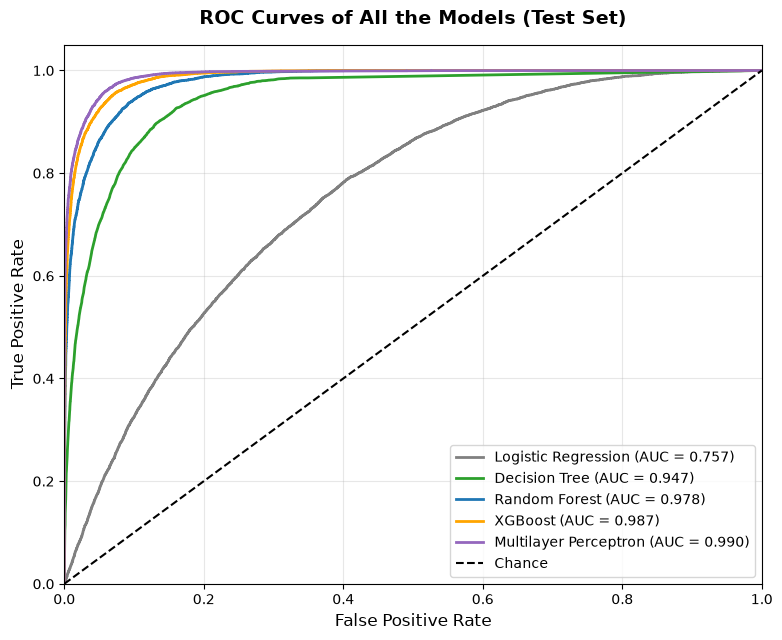

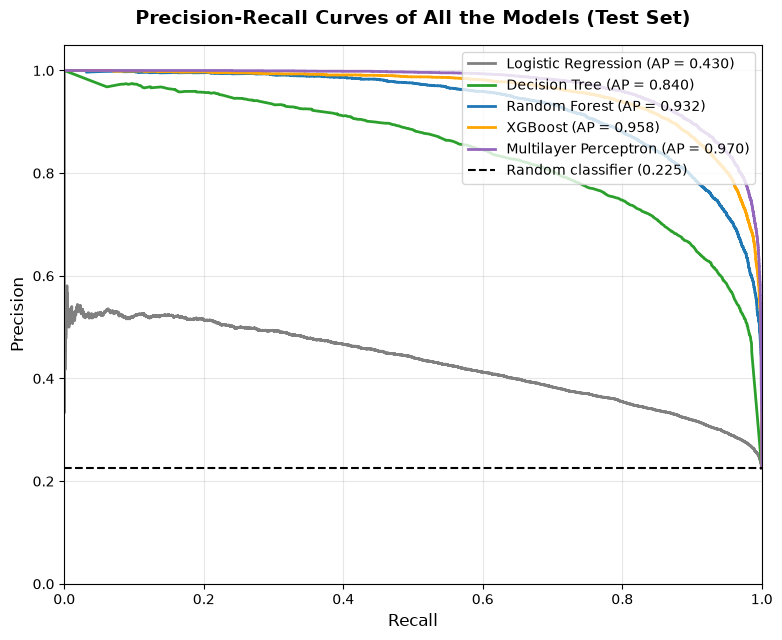

In [40]:
### --- Combined ROC Curves of All the Models --- ###
colors = ['gray', 'tab:green', 'tab:blue', 'orange', 'tab:purple']
test_proba = {n: r['model'].predict_proba(X_test)[:, 1] for n, r in RESULTS.items()}

plt.figure(figsize = (9, 7))
for (name, proba), color in zip(test_proba.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, color = color, lw = 2, label = f'{name} (AUC = {roc_auc_score(y_test, proba):.3f})')

plt.plot([0, 1], [0, 1], color = 'black', linestyle = '--', label = 'Chance')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.title('ROC Curves of All the Models (Test Set)', fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel('False Positive Rate', fontsize = 12)
plt.ylabel('True Positive Rate', fontsize = 12)
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()

### --- Combined Precision-Recall Curves of All the Models --- ###
plt.figure(figsize = (9, 7))
for (name, proba), color in zip(test_proba.items(), colors):
    precision, recall, _ = precision_recall_curve(y_test, proba)
    plt.plot(recall, precision, color = color, lw = 2, label = f'{name} (AP = {average_precision_score(y_test, proba):.3f})')
plt.axhline(y_test.mean(), color = 'black', linestyle = '--', label = f'Random classifier ({y_test.mean():.3f})')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.title('Precision-Recall Curves of All the Models (Test Set)', fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel('Recall', fontsize = 12)
plt.ylabel('Precision', fontsize = 12)
plt.legend(loc = 'upper right')
plt.grid(alpha = 0.3)
plt.show()

### **13.4 How Much Do the Differences Matter? Bootstrap Confidence Intervals**

A single test set gives a single, noisy number, and the test set contains about 9,400 polymorphic parameter sets (out of 41,952). We resample the test set 1,000 times (with replacement) to obtain **95% confidence intervals** for the test PR AUC, the test ROC AUC and the test F1 (at the threshold stored for each model), and, for both AUCs, the interval of the **paired difference** with the model that is best on the validation folds. If the interval of a difference contains 0, the test set cannot tell the two models apart.

In [41]:
### --- Bootstrap Confidence Intervals on the Test Set --- ###
rng = np.random.default_rng(random_seed)
y_test_arr = y_test.to_numpy()
n_boot = BUDGET['n_boot']
boot_idx = rng.integers(0, len(y_test_arr), size = (n_boot, len(y_test_arr)))

boot = {n: {k: np.empty(n_boot) for k in ('pr_auc', 'roc_auc', 'f1')} for n in RESULTS}
for b in range(n_boot):
    y_b = y_test_arr[boot_idx[b]]
    for n, proba in test_proba.items():
        p_b = proba[boot_idx[b]]
        boot[n]['pr_auc'][b] = average_precision_score(y_b, p_b)
        boot[n]['roc_auc'][b] = roc_auc_score(y_b, p_b)
        boot[n]['f1'][b] = f1_score(y_b, (p_b >= RESULTS[n]['threshold']).astype(int))

def fmt_ci(point, draws):
    low, high = np.percentile(draws, [2.5, 97.5])
    return f'{point:.3f} [{low:.3f}, {high:.3f}]'

def fmt_diff(n, metric):
    """Paired bootstrap difference between a model and the reference model (same resamples), with its 95% interval."""
    if n == ref_name:
        return '-'
    diff = boot[n][metric] - boot[ref_name][metric]
    return f'{np.mean(diff):+.3f} [{np.percentile(diff, 2.5):+.3f}, {np.percentile(diff, 97.5):+.3f}]'

rows = []
for n in RESULTS:
    rows.append({
        'Model': n,
        'Test ROC AUC [95% CI]': fmt_ci(RESULTS[n]['metrics']['roc_auc']['test'], boot[n]['roc_auc']),
        'Test PR AUC [95% CI]': fmt_ci(RESULTS[n]['metrics']['pr_auc']['test'], boot[n]['pr_auc']),
        'Test F1 [95% CI]': fmt_ci(RESULTS[n]['thr_test']['F1'], boot[n]['f1']),
        f'ROC AUC difference vs {ref_name} [95% CI]': fmt_diff(n, 'roc_auc'),
        f'PR AUC difference vs {ref_name} [95% CI]': fmt_diff(n, 'pr_auc'),
    })
display(pd.DataFrame(rows).set_index('Model'))

,Test ROC AUC [95% CI],Test PR AUC [95% CI],Test F1 [95% CI],ROC AUC difference vs Multilayer Perceptron [95% CI],PR AUC difference vs Multilayer Perceptron [95% CI]
Model,,,,,
Logistic Regression,"0.757 [0.752, 0.762]","0.430 [0.421, 0.441]","0.496 [0.489, 0.503]","-0.233 [-0.238, -0.228]","-0.540 [-0.549, -0.530]"
Decision Tree,"0.947 [0.945, 0.949]","0.840 [0.833, 0.847]","0.773 [0.766, 0.780]","-0.043 [-0.045, -0.041]","-0.130 [-0.137, -0.123]"
Random Forest,"0.978 [0.977, 0.979]","0.932 [0.928, 0.935]","0.847 [0.842, 0.853]","-0.012 [-0.013, -0.011]","-0.038 [-0.041, -0.036]"
XGBoost,"0.987 [0.986, 0.988]","0.958 [0.955, 0.960]","0.886 [0.881, 0.891]","-0.003 [-0.004, -0.003]","-0.012 [-0.014, -0.011]"
Multilayer Perceptron,"0.990 [0.990, 0.991]","0.970 [0.968, 0.972]","0.899 [0.895, 0.903]",-,-


### **13.5 Are the Predicted Probabilities Real Probabilities? Calibration**

Because the data was **not rebalanced**, the predicted probabilities should match observed frequencies: among parameter sets with a predicted probability near 0.3, about 30% should be polymorphic. The reliability diagram compares predicted and observed frequencies in ten bins of equal size (the left panel shows the whole range, the right panel zooms on the low probabilities, where most of the parameter sets are). The Brier score and the log loss summarise the quality of the probabilities (lower is better; the reference is the constant prediction equal to the prevalence).

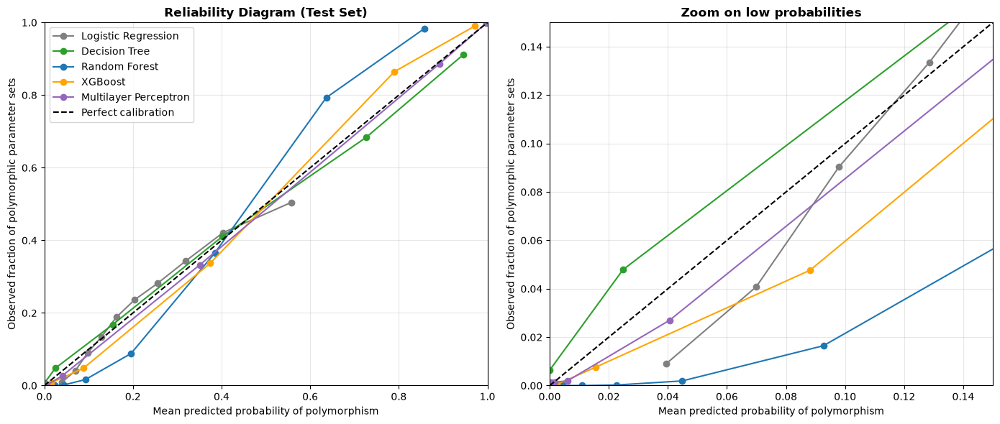

,Brier score,Log loss
Model,,
Logistic Regression,0.1510,0.4602
Decision Tree,0.0739,0.3507
Random Forest,0.0552,0.1920
XGBoost,0.0380,0.1278
Multilayer Perceptron,0.0319,0.1048
Constant prediction (prevalence),0.1743,0.5330


In [42]:
### --- Calibration (Reliability) Diagram and Probability Scores --- ###
fig, axes = plt.subplots(1, 2, figsize = (14, 6))
calib_rows = []
for (name, proba), color in zip(test_proba.items(), colors):
    frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins = 10, strategy = 'quantile')
    for ax in axes:
        ax.plot(mean_pred, frac_pos, marker = 'o', color = color, label = name)
    calib_rows.append({'Model': name, 'Brier score': brier_score_loss(y_test, proba), 'Log loss': log_loss(y_test, proba)})
for ax, limit in zip(axes, [1.0, 0.15]):
    ax.plot([0, limit], [0, limit], 'k--', label = 'Perfect calibration')
    ax.set_xlim(0, limit); ax.set_ylim(0, limit)
    ax.set_xlabel('Mean predicted probability of polymorphism')
    ax.set_ylabel('Observed fraction of polymorphic parameter sets')
    ax.grid(alpha = 0.3)
axes[0].set_title('Reliability Diagram (Test Set)', fontweight = 'bold')
axes[1].set_title('Zoom on low probabilities', fontweight = 'bold')
axes[0].legend(loc = 'upper left')
plt.tight_layout()
plt.show()

base_p = np.full(len(y_test), y_train.mean())
calib_rows.append({'Model': 'Constant prediction (prevalence)', 'Brier score': brier_score_loss(y_test, base_p), 'Log loss': log_loss(y_test, base_p)})
display(pd.DataFrame(calib_rows).set_index('Model').round(4))

### **13.6 Where Does the Best Model Make Errors? Label Noise**

If part of the errors comes from label noise (Section 6.5), the errors should be most frequent for parameter sets whose `frac_polymorphic` is small but non-zero: those are the ones that are positive only by chance. The table groups the test samples by `frac_polymorphic` and reports the error rate of XGBoost in each group, at its F1-optimal threshold. For the first group (not polymorphic) an error is a false alarm; for the others it is a missed polymorphic parameter set.

,n,error_rate,mean_predicted_probability
group,,,
"(0, 0.05]",4281,0.212,0.671
"(0.05, 0.2]",2905,0.018,0.892
"(0.2, 0.5]",1596,0.006,0.934
"(0.5, 1]",651,0.008,0.957
0 (not polymorphic),32519,0.037,0.056


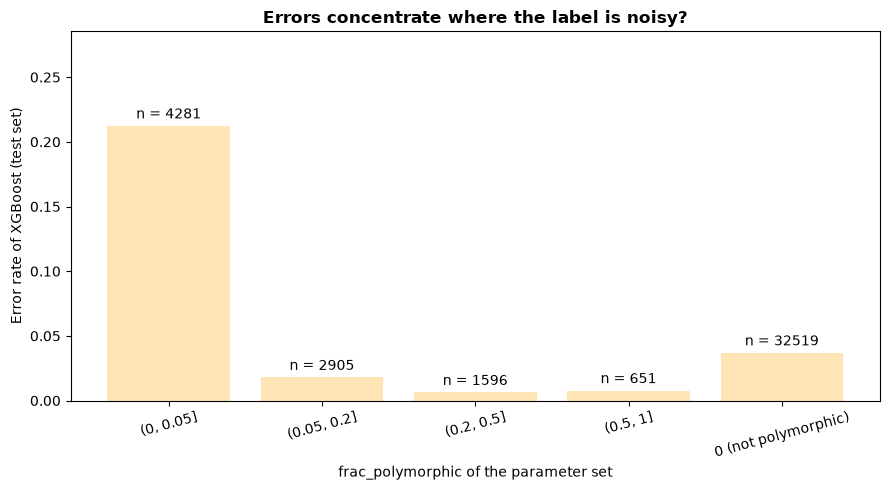

In [43]:
### --- Error Rate of XGBoost as a Function of frac_polymorphic --- ###
xgb_model = RESULTS['XGBoost']['model']
p_xgb = xgb_model.predict_proba(X_test)[:, 1]
frac_test = df_model.loc[X_test.index, 'frac_polymorphic']      # Exact look-up: the row index of df_model is unique (Section 3).
assert ((frac_test > POLYMORPH_THRESHOLD).astype(int).to_numpy() == y_test.to_numpy()).all()   # Same rows, same labels as y_test.

bins = [-0.001, 0.0, 0.05, 0.2, 0.5, 1.0]
labels = ['0 (not polymorphic)', '(0, 0.05]', '(0.05, 0.2]', '(0.2, 0.5]', '(0.5, 1]']
err_df = pd.DataFrame({
    'group': pd.cut(frac_test, bins = bins, labels = labels).to_numpy(),
    'error': ((p_xgb >= RESULTS['XGBoost']['threshold']).astype(int) != y_test.to_numpy()).astype(int),
    'p': p_xgb,
})
err_table = err_df.groupby('group', observed = True).agg(
    n = ('error', 'size'), error_rate = ('error', 'mean'), mean_predicted_probability = ('p', 'mean'))
display(err_table.round(3))

plt.figure(figsize = (9, 5))
bars = plt.bar(err_table.index.astype(str), err_table['error_rate'], color = 'moccasin')
plt.bar_label(bars, labels = [f'n = {n}' for n in err_table['n']], padding = 3)
plt.ylabel('Error rate of XGBoost (test set)')
plt.xlabel('frac_polymorphic of the parameter set')
plt.title('Errors concentrate where the label is noisy?', fontweight = 'bold')
plt.xticks(rotation = 15)
plt.ylim(0, min(1.0, err_table['error_rate'].max() * 1.25 + 0.02))
plt.tight_layout()
plt.show()

### **13.7 Does the Definition of "Polymorphic" Matter? Threshold Sensitivity**

The same XGBoost configuration (hyperparameters **not** re-tuned) is trained with stricter definitions of the positive class. If the performance rises with the threshold, part of the error of the original task was due to label noise near the boundary. The PR AUC must be read against the share of positives of each row (the value of a random classifier), which falls as the definition gets stricter.

In [44]:
### --- Threshold Sensitivity of the Polymorphic Label --- ###
sens_rows = []
for thr in [0.0, 0.01, 0.05, 0.10, 0.25]:
    y_tr_thr = (df_model.loc[X_train.index, 'frac_polymorphic'] > thr).astype(int)
    y_te_thr = (df_model.loc[X_test.index, 'frac_polymorphic'] > thr).astype(int)
    
    model_thr = clone(xgb_model).fit(X_train, y_tr_thr)
    proba_thr = model_thr.predict_proba(X_test)[:, 1]
    
    sens_rows.append({
        'threshold': thr,
        'share polymorphic (test)': y_te_thr.mean(),
        'test PR AUC': average_precision_score(y_te_thr, proba_thr),
        'PR AUC / share (lift over random)': average_precision_score(y_te_thr, proba_thr) / y_te_thr.mean(),
        'test ROC AUC': roc_auc_score(y_te_thr, proba_thr),
    })

display(pd.DataFrame(sens_rows).set_index('threshold').round(3))

,share polymorphic (test),test PR AUC,PR AUC / share (lift over random),test ROC AUC
threshold,,,,
0.00,0.225,0.958,4.259,0.987
0.01,0.186,0.956,5.150,0.989
0.05,0.123,0.943,7.676,0.990
0.10,0.088,0.937,10.712,0.993
0.25,0.043,0.907,20.883,0.994


### **13.8 Would More Simulations Help? Learning Curve**

Each parameter set is expensive to simulate. The learning curve trains XGBoost on increasing fractions of the training set and shows the validation PR AUC (5-fold CV). If the validation curve has flattened, more simulations of the same kind would add little. If it is still rising, more data would help.

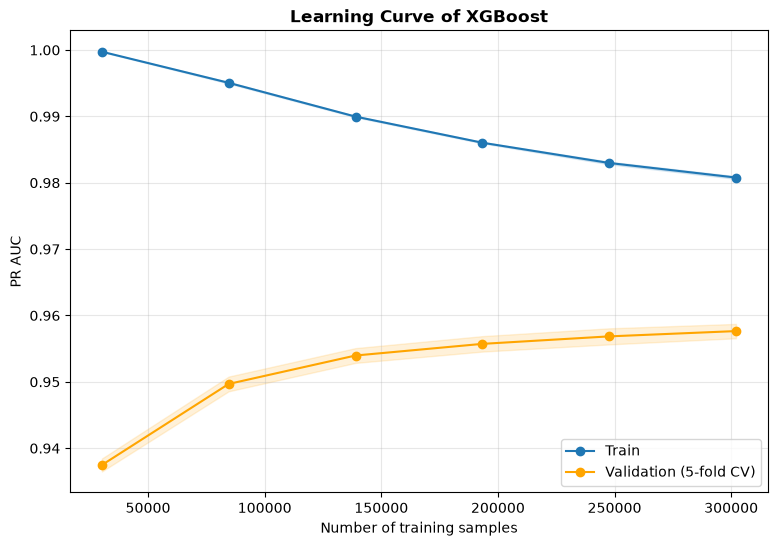

In [45]:
### --- Learning Curve of XGBoost --- ###
sizes, train_sc, val_sc = learning_curve(
    clone(xgb_model).set_params(n_jobs = 1), X_train, y_train, train_sizes = BUDGET['lc_sizes'],
    cv = CV, scoring = 'average_precision', n_jobs = -1)

plt.figure(figsize = (9, 6))
for scores, label, color in [(train_sc, 'Train', 'tab:blue'), (val_sc, 'Validation (5-fold CV)', 'orange')]:
    plt.plot(sizes, scores.mean(axis = 1), marker = 'o', color = color, label = label)
    plt.fill_between(sizes, scores.mean(axis = 1) - scores.std(axis = 1),
                     scores.mean(axis = 1) + scores.std(axis = 1), color = color, alpha = 0.15)
plt.xlabel('Number of training samples')
plt.ylabel('PR AUC')
plt.title('Learning Curve of XGBoost', fontweight = 'bold')
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()


> **Takeaway.** Tables 1 and 2 are the summary of the modelling.
>
> - **Ranking.** On the test set the PR AUC goes from 0.430 (logistic regression) to 0.840 (tree), 0.932 (forest), 0.958 (XGBoost) and 0.970 (MLP), against 0.225 for a random classifier; the ROC AUC goes 0.757, 0.947, 0.978, 0.987, 0.990. The bootstrap intervals (Section 13.4) are narrow (at most about 0.01 on the PR AUC) and every paired difference with the MLP excludes 0, so the ranking is real. The gain is large from linear to non-linear models and shrinks from the forest onwards: XGBoost is only 0.012 PR AUC (interval -0.014 to -0.011) and 0.003 ROC AUC (interval -0.004 to -0.003) below the MLP.
> - **Calibration (13.5).** The probabilities of the MLP and of XGBoost follow the diagonal of the reliability diagram (Brier score 0.032 and 0.038, log loss 0.105 and 0.128, against 0.174 and 0.533 for the constant prediction), so they can be read as probabilities of polymorphism. The forest is pulled towards the middle (observed frequencies below the predicted ones at low and medium probabilities and above them at high probabilities; Brier score 0.055). The tree (Brier 0.074, log loss 0.351) and above all the logistic regression (Brier 0.151) are much worse.
> - **Where the errors are (13.6).** XGBoost misses 21% of the parameter sets with 0 < `frac_polymorphic` <= 0.05, but only 0.6% to 1.8% of those above 0.05, and it raises a false alarm for 3.7% of the non polymorphic ones. Out of roughly 2,200 errors, about 1,200 are false alarms and about 900 are weakly polymorphic sets that are missed. This is what label noise looks like: the errors sit on the boundary, where a single replicate decides the label, and some of the false alarms are probably weakly polymorphic sets for which no replicate happened to keep the allele.
> - **Definition of the label (13.7).** With stricter definitions of the positive class the ROC AUC rises (0.987 for `> 0`, 0.994 for `> 0.25`) and so does the lift of the PR AUC over a random classifier (from 4.3 to 20.9). The PR AUC itself falls (0.958 to 0.907) only because the share of positives falls from 22.5% to 4.3%. Part of the error of the original task is therefore label noise.
> - **More simulations? (13.8).** The validation PR AUC of XGBoost rises from 0.937 with about 30,000 training rows to 0.958 with about 300,000 (the largest size of the 5-fold protocol), but the curve is almost flat at the end (less than 0.002 for the last 50,000 rows) while the train score stays higher (0.981). More simulations of the same kind would add little; a longer search or targeted simulations are more promising.
>
> The explanation below is applied to **XGBoost**, because TreeSHAP is exact and fast for tree ensembles. XGBoost is **not** the best model of Table 2: the MLP is better on both metrics (paired difference -0.012 on the PR AUC, interval excluding 0, Section 13.4), and XGBoost comes second. The explanations are therefore explanations of a very good but not optimal model; Section 14.11 and the direct checks on the raw data guard against that limit. The XGBoost configuration is also at the edge of several of its ranges (Table 1), so a longer search could improve it.


## **14. Interpreting XGBoost**

XGBoost is a black box. Before opening it, a word on what an explanation can and cannot tell us.

**What SHAP assumes.** SHAP borrows from cooperative game theory: the features are the *players*, the *payout* is the prediction minus the average prediction, and Shapley values share the payout according to fairness axioms. This needs

1. a rule for what *removing* a feature means. `TreeExplainer` integrates a feature out using the training data seen by each tree, which is only harmless if features are not strongly dependent. **Here they are independent by design** (Section 4.5), which is a real strength of this data set;
2. an additive decomposition **in log-odds**, not in probability;
3. the acceptance of the Shapley axioms as the *definition* of a feature's contribution.

Above all, SHAP values explain **the model, not the simulator**. They are only as good as the model's fit (Section 13).

**What we deliberately do not use.** SHAP *interaction* values add another layer: a second-order Shapley index, split symmetrically between two features, which is then read as a biological interaction. On top of an approximate model, this stacks assumption on assumption. We therefore keep SHAP simple (global importance, direction of the effects, dependence plots) and study interactions with tools that need fewer assumptions:

- **ICE curves and partial dependence plots** (model-based, but each curve answers one clear question: *what does the model predict if I change only this parameter?*);
- **jointplots and observed rates in bins** (no model at all).

Because the parameters are independent and uniformly distributed, the partial dependence of the *true* process equals the observed polymorphism rate in a bin. This gives us an independent check of the model, which a SHAP-only analysis cannot offer (Sections 14.5 and 14.6).

The analysis is organised as follows:

| Section | Question |
|---|---|
| 14.1 to 14.3 | SHAP: which parameters drive the predictions, and in which direction? |
| 14.4 | PDP and ICE: what is the shape of each effect? |
| 14.5 | Which parameters interact? Look at the data, then compare with the model. |
| 14.6 | A specific hypothesis: dominance in queens and workers. |
| 14.7 | Distillation: can a small readable model reproduce the black box? |
| 14.8 | Why did distillation struggle, and which student fits better? |
| 14.9 | Is there a readable model that matches the black box? (Explainable Boosting Machine) |
| 14.10 | Which pairs of parameters interact? A screen without SHAP interaction values. |
| 14.11 | What is new: does selection in males (`om`) change the picture? |
| 14.12 | How does the three-way model differ from the previous two-caste model? |

### **14.1 Computing the SHAP Values**

SHAP values are computed on the **test set**: it shows how the model behaves on parameter sets it did not train on, which is where the model is actually used. Each value is in **log-odds** units. The baseline (`expected value`) is the model's average output; converted to a probability it should be close to the real share of polymorphic parameter sets, since the data was not rebalanced. The last line checks the **local accuracy** property of SHAP: baseline plus the sum of the SHAP values of a sample must reproduce the model's output for that sample.

In [46]:
### --- SHAP Values on the Test Set --- ###
best_xgb = RESULTS['XGBoost']['model']
X_explain = X_test.copy()

explainer = shap.TreeExplainer(best_xgb)      # Exact for tree ensembles (tree-path-dependent, see the text above).
shap_expl = explainer(X_explain)

shap_vals = np.asarray(shap_expl.values)
if shap_vals.ndim == 3:                       # Some SHAP versions return one slice per class.
    shap_vals = shap_vals[:, :, 1]
base_value = float(np.ravel(shap_expl.base_values)[0])

print('SHAP array shape:', shap_vals.shape, '(samples x features)')
print(f'Baseline (expected value): {base_value:.3f} log-odds = {1 / (1 + np.exp(-base_value)):.1%} probability of polymorphism')
print(f'Share of polymorphic parameter sets in the training data: {y_train.mean():.1%}')

# Local accuracy: baseline + sum of SHAP values should equal the model output (log-odds).
margin = best_xgb.predict(X_explain, output_margin = True)
print(f'Local accuracy check: max |baseline + sum(SHAP) - model output| = {np.abs(base_value + shap_vals.sum(axis = 1) - margin).max():.2e}')

SHAP array shape: (41952, 11) (samples x features)
Baseline (expected value): -1.250 log-odds = 22.3% probability of polymorphism
Share of polymorphic parameter sets in the training data: 22.5%
Local accuracy check: max |baseline + sum(SHAP) - model output| = 5.34e-05


### **14.2 Global Explanation: Beeswarm and Importance**

**Beeswarm plot.** Every dot is one test sample. Its horizontal position is the SHAP value of the feature (how much it pushes the prediction, in log-odds), and its colour is the value of the feature (red is high, blue is low). Features are sorted from the most to the least influential. Read the plot feature by feature: *which colour is on the right?* tells the direction of the effect, and a mix of colours at a given position hints that other features modulate the effect.

**Global importance.** Averaging the absolute SHAP values over the samples gives a single ranking of the features. Since `Nq` and `Nm` are now single numeric columns, their importance is no longer spread over dummy variables and can be compared directly with the others.

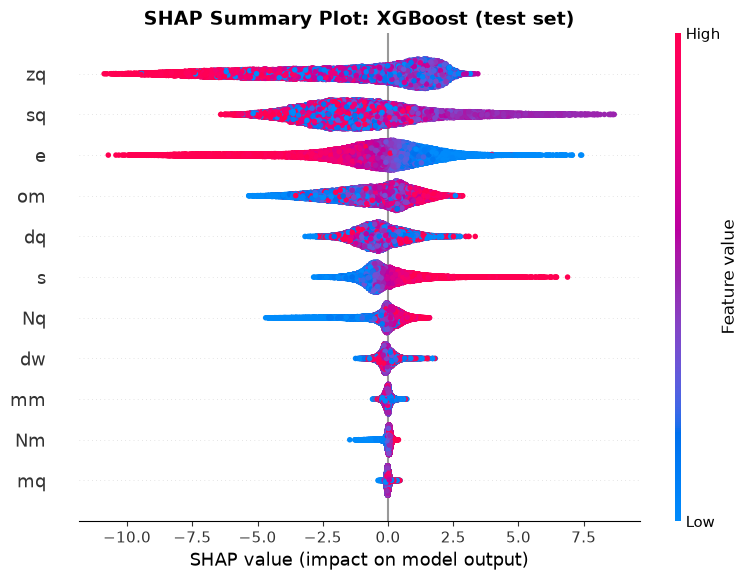

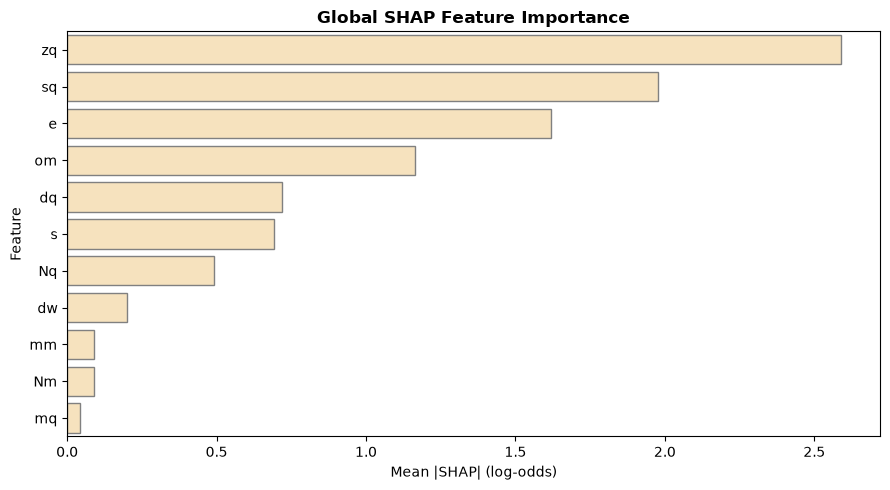

,Feature,Mean |SHAP| (log-odds)
0,zq,2.590
1,sq,1.977
2,e,1.618
3,om,1.164
4,dq,0.719
5,s,0.693
6,Nq,0.493
7,dw,0.200
8,mm,0.090
9,Nm,0.089


In [47]:
### --- SHAP Summary Plot (Beeswarm) --- ###
plt.figure(figsize = (10, 6))
shap.summary_plot(shap_vals, X_explain, show = False)
plt.title('SHAP Summary Plot: XGBoost (test set)', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

### --- Global SHAP Feature Importance --- ###
shap_importance = pd.DataFrame({
    'Feature': X_explain.columns,
    'Mean |SHAP| (log-odds)': np.abs(shap_vals).mean(axis = 0),
}).sort_values('Mean |SHAP| (log-odds)', ascending = False).reset_index(drop = True)

plt.figure(figsize = (9, 5))
sns.barplot(data = shap_importance, x = 'Mean |SHAP| (log-odds)', y = 'Feature', color = 'moccasin', edgecolor = 'gray')
plt.title('Global SHAP Feature Importance', fontweight = 'bold')
plt.tight_layout()
plt.show()
display(shap_importance.round(3))

**Permutation importance.** SHAP importance describes how much the model's *output* moves with each feature. Permutation importance asks a different question: how much does the **performance** (here the PR AUC on the test set) fall when the feature is shuffled? The two rankings usually agree; when they do not, a feature moves the predictions without improving them.

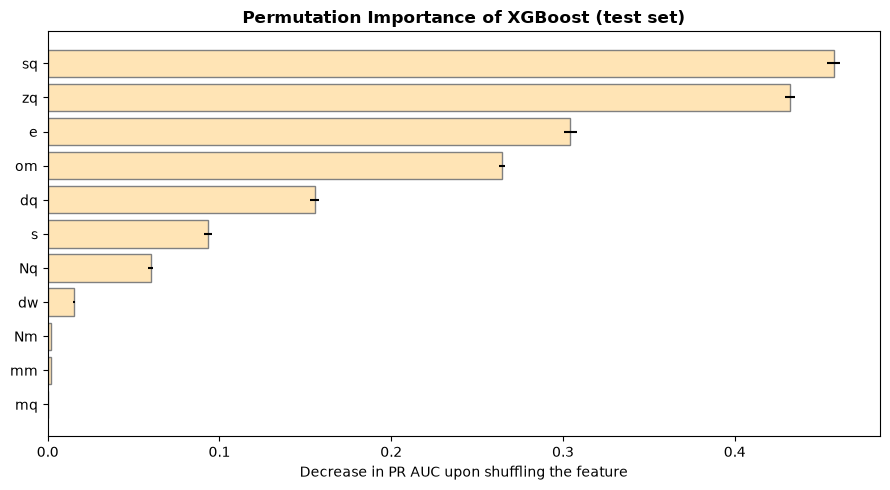

,Feature,Drop in PR AUC,sd
0,sq,0.4575,0.0040
1,zq,0.4321,0.0031
2,e,0.3042,0.0037
3,om,0.2645,0.0016
4,dq,0.1553,0.0026
5,s,0.0932,0.0024
6,Nq,0.0600,0.0013
7,dw,0.0154,0.0005
8,Nm,0.0020,0.0001
9,mm,0.0020,0.0001


In [48]:
### --- Permutation Importance of XGBoost on the PR AUC (test set) --- ###
perm_xgb = permutation_importance(best_xgb, X_test, y_test, scoring = 'average_precision', n_repeats = BUDGET['perm_repeats_xgb'],
                                  random_state = random_seed, n_jobs = 1)
perm_table = pd.DataFrame({'Feature': X_test.columns, 'Drop in PR AUC': perm_xgb.importances_mean,
                           'sd': perm_xgb.importances_std}).sort_values('Drop in PR AUC', ascending = False).reset_index(drop = True)
plt.figure(figsize = (9, 5))
order_p = perm_table.iloc[::-1]
plt.barh(order_p['Feature'], order_p['Drop in PR AUC'], xerr = order_p['sd'], color = 'moccasin', edgecolor = 'gray')
plt.xlabel('Decrease in PR AUC upon shuffling the feature')
plt.title('Permutation Importance of XGBoost (test set)', fontweight = 'bold')
plt.tight_layout()
plt.show()
display(perm_table.round(4))

### **14.3 Direction and Shape of the Effects: SHAP Dependence Plots**

One panel per parameter, ordered by importance. Each dot is a test sample: its horizontal position is the value of the parameter, its vertical position is its SHAP value (the push on the log-odds of polymorphism, above 0 favours polymorphism). The **black line is the average effect**: a flat line means that the parameter does nothing on average. The **colour is the value of the parameter that best explains the vertical spread of the dots** (`shap.approximate_interactions`, a quick heuristic on the ordinary SHAP values; no SHAP interaction values are computed). A clean separation of colours at a given x means that the effect of the parameter depends on that partner.

The table below the figure turns each panel into a verdict: **clear effect** (the average curve spans more than 0.5 log-odds), **only through a partner** (flat on average, but the dots spread widely around the curve), or **little or no effect**.

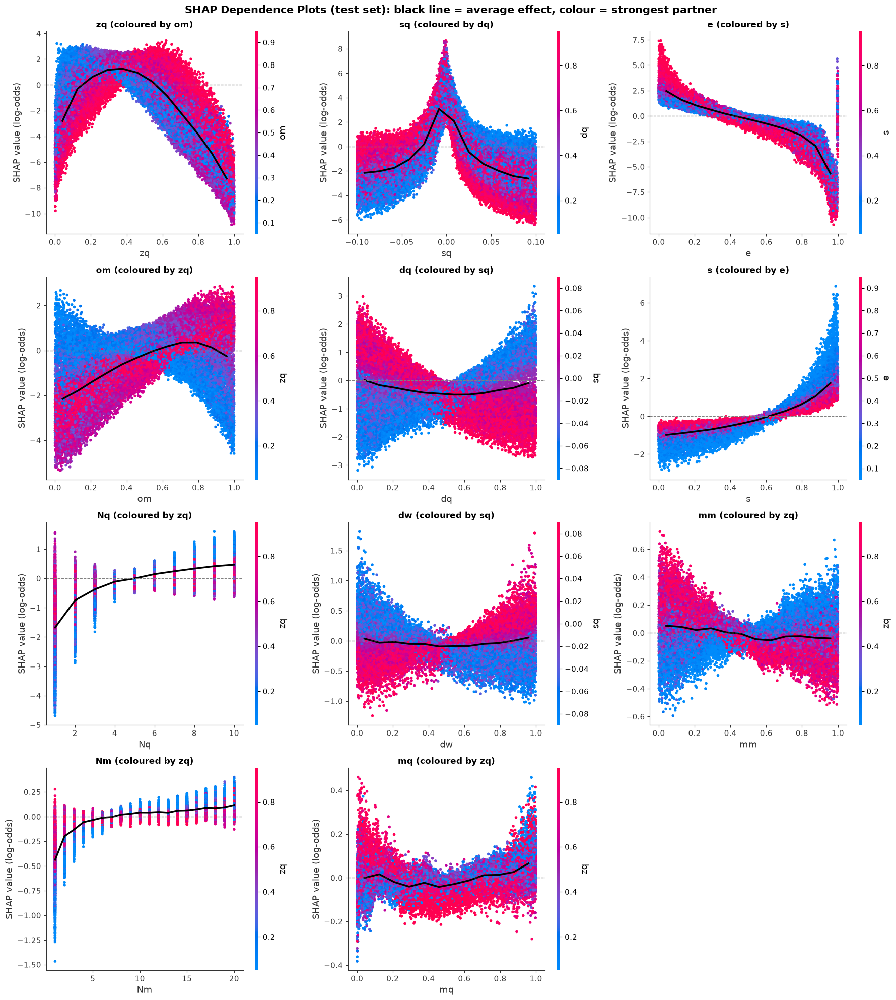

,mean |SHAP|,span of average curve,shape,spread around the curve,strongest partner,verdict
parameter,,,,,,
zq,2.590,8.539,non-monotone,1.463,om,clear effect
sq,1.977,5.697,non-monotone,1.378,dq,clear effect
e,1.618,8.135,decreases,0.802,s,clear effect
om,1.164,2.517,increases,1.130,zq,clear effect
dq,0.719,0.517,non-monotone,0.809,sq,clear effect
s,0.693,2.739,increases,0.400,e,clear effect
Nq,0.493,2.143,increases,0.484,zq,clear effect
dw,0.200,0.147,flat,0.258,sq,only through sq
mm,0.090,0.104,flat,0.119,zq,little or no effect


In [49]:
### --- SHAP Dependence Plots: Every Parameter, Coloured by Its Strongest Partner --- ###
# The colour feature is the one that best explains the vertical spread of the SHAP values (shap.approximate_interactions).
# This is a cheap heuristic on the ordinary SHAP values: it does NOT compute SHAP interaction values.
EFFECT_THRESHOLD = 0.5    # A parameter has a visible effect if its average curve spans more than this (log-odds).
SPREAD_THRESHOLD = 0.25   # ... or only through a partner if the dots spread around a flat curve by more than this.

effect_rows, partner_of = [], {}
fig, axes = plt.subplots(4, 3, figsize = (18, 20))
for ax, feat in zip(axes.ravel(), shap_importance['Feature']):
    j = list(X_explain.columns).index(feat)
    partner = X_explain.columns[shap.approximate_interactions(j, shap_vals, X_explain)[0]]
    partner_of[feat] = partner
    shap.dependence_plot(j, shap_vals, X_explain, interaction_index = partner, ax = ax, show = False)

    # Average SHAP value per integer (counts) or per bin (continuous features): the black line.
    x, y_s = X_explain[feat].to_numpy(), shap_vals[:, j]
    if len(np.unique(x)) <= 20:
        avg = pd.Series(y_s).groupby(x).mean()
        curve_x, curve_y = avg.index.to_numpy(), avg.to_numpy()
    else:
        binned = pd.DataFrame({'x': x, 'y': y_s, 'bin': pd.cut(x, 12)}).groupby('bin', observed = True).mean()
        curve_x, curve_y = binned['x'].to_numpy(), binned['y'].to_numpy()
    ax.plot(curve_x, curve_y, color = 'black', linewidth = 2.5)
    ax.axhline(0, color = 'gray', linestyle = '--', linewidth = 1)
    ax.set_title(f'{feat} (coloured by {partner})', fontweight = 'bold')
    ax.set_ylabel('SHAP value (log-odds)')

    span = curve_y.max() - curve_y.min()
    spread = np.std(y_s - np.interp(x, curve_x, curve_y))
    rho = stats.spearmanr(curve_x, curve_y).correlation
    shape = 'increases' if rho > 0.8 else 'decreases' if rho < -0.8 else 'non-monotone'
    effect_rows.append({'parameter': feat, 'mean |SHAP|': np.abs(y_s).mean(), 'span of average curve': span,
                        'shape': shape if span > EFFECT_THRESHOLD else 'flat',
                        'spread around the curve': spread, 'strongest partner': partner,
                        'verdict': 'clear effect' if span > EFFECT_THRESHOLD
                                   else f'only through {partner}' if spread > SPREAD_THRESHOLD else 'little or no effect'})
for ax in axes.ravel()[len(shap_importance):]:
    ax.set_visible(False)
fig.suptitle('SHAP Dependence Plots (test set): black line = average effect, colour = strongest partner', fontsize = 15, fontweight = 'bold', y=0.99)
plt.tight_layout()
plt.show()

display(pd.DataFrame(effect_rows).set_index('parameter').round(3))

### **14.4 Partial Dependence and ICE Curves**

A **partial dependence plot** (PDP) shows the *average* predicted probability of polymorphism when one parameter is set to each value of its range, all the other parameters keeping the values observed in the data. An **ICE curve** (individual conditional expectation) draws the same thing for a single parameter set. The thick line is the PDP, the thin lines are ICE curves of 150 parameter sets.

- If all ICE curves are parallel, the effect of the parameter is the same whatever the other parameters are.
- If they fan out or cross, the effect **depends on the other parameters**: there is an interaction, and the PDP, being an average, hides it.

PDPs assume that the feature of interest is independent of the others, so that setting it to any value produces a realistic parameter set. This holds here by design. The probabilities are on a real probability scale, because the data was not rebalanced.

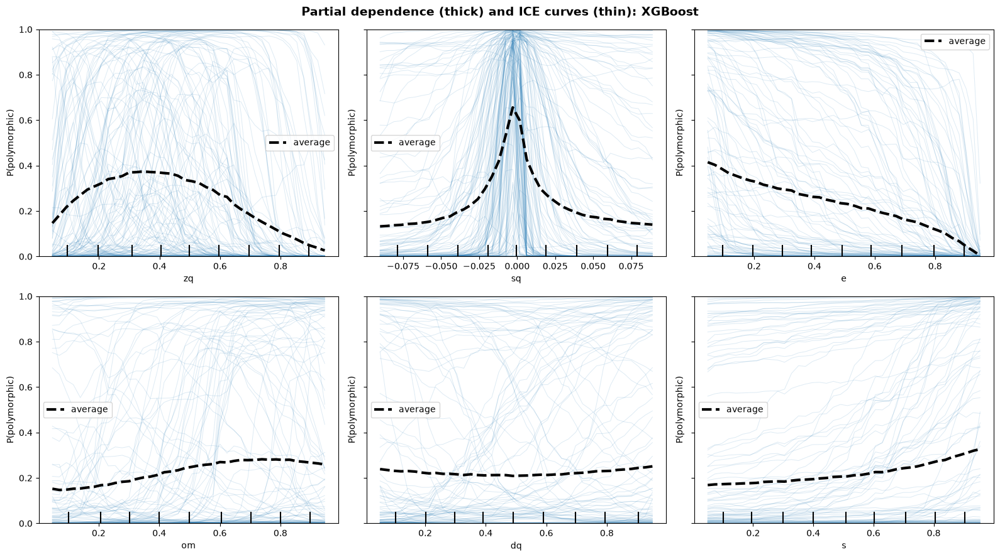

In [50]:
### --- 1D Partial Dependence and ICE Curves for the Six Most Important Features --- ###
top_features = list(shap_importance['Feature'].head(6))
fig, axes = plt.subplots(2, 3, figsize = (16, 9))
PartialDependenceDisplay.from_estimator(
    best_xgb, X_train.sample(5000, random_state = random_seed), features = top_features, kind = 'both',
    subsample = 150, grid_resolution = 40, random_state = random_seed,
    ice_lines_kw = {'color': 'tab:blue', 'alpha': 0.15, 'linewidth': 0.7},
    pd_line_kw = {'color': 'black', 'linewidth': 3},
    ax = axes)
for ax in axes.ravel():
    ax.set_ylim(0, 1)
    ax.set_ylabel('P(polymorphic)')
fig.suptitle('Partial dependence (thick) and ICE curves (thin): XGBoost', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

> **Takeaway (SHAP, permutation importance, partial dependence).**
>
> - **Same ranking, two methods.** By mean |SHAP| (log-odds) the order is `zq` (2.59), `sq` (1.98), `e` (1.62), `om` (1.16), `dq` (0.72), `s` (0.69) and `Nq` (0.49); `dw` (0.20), `mm` and `Nm` (0.09 each) and `mq` (0.04) are small. The drop in PR AUC after shuffling gives the same seven parameters in nearly the same order (`sq` 0.46, `zq` 0.43, `e` 0.30, `om` 0.26, `dq` 0.16, `s` 0.09, `Nq` 0.06) and almost nothing for the others (0.015 for `dw`, 0.002 or less for `Nm`, `mm` and `mq`). The baseline of the explainer (22.3%) is close to the observed share of polymorphic sets (22.5%) and the local accuracy check is met (5e-5).
> - **Shapes of the effects.** `e` has a monotone negative effect (the average probability falls from about 0.41 to about 0.02 between `e` = 0 and `e` = 1). `s` and `Nq` have a positive effect (the probability rises from about 0.17 to 0.33 with `s`, and `Nq` = 1, a colony with a single queen, is by far the worst case). `zq` is a **hump**: polymorphism is most likely for intermediate values (average probability of about 0.37 for `zq` around 0.35) and falls steeply above about 0.6. `sq` is a **sharp peak at 0** (average probability of about 0.65 at `sq` = 0 and about 0.13 at |`sq`| = 0.1): the allele is maintained mostly when its effect is small. `om` raises the probability on average (0.15 to 0.28, with a plateau between 0.6 and 0.9). `dq` and `dw` are flat on average (spans of 0.5 and 0.15 log-odds), and `mq`, `mm` and `Nm` hardly move the prediction (spans of 0.1 to 0.6 log-odds, the latter only because `Nm` = 1 differs from the other values).
> - **Interactions everywhere.** The ICE curves fan out and cross in every panel, so the effect of each parameter depends on the others. The SHAP colours say on which: `dq` and `dw` act **through `sq`** (the colours of the two signs of `sq` are opposite, with a high `dq` helping polymorphism for negative `sq` and a high `dw` for positive `sq`), `zq` and `om` modulate each other, and so do `e` and `s`. A flat average, as for `dq`, therefore hides a strong effect that changes sign with `sq` (Section 14.6).
> - **A caution on `sq`.** `frac_polymorphic` counts the replicates in which the allele is neither lost nor fixed at the end of the simulation. For an allele with a very small effect drift is slow, so part of the peak at `sq` = 0 may reflect an allele that has not yet been lost or fixed, rather than a polymorphism maintained by selection. The data of this notebook cannot separate the two; this is a question for targeted simulations (Section 15.3).


### **14.5 Which Parameters Interact? Look at the Data First**

We focus on the three most important parameters and look at each pair in two ways:

1. **Jointplots of the raw data** (no model): each dot is a simulated parameter set, coloured by outcome. The marginal curves show how the two classes differ along each axis, and the scatter shows where in the plane the classes separate.
2. **Observed polymorphism rate in bins, compared with the model's 2D partial dependence.** Because the parameters are independent, the two should agree if the model is good. Where they disagree, the model, not the biology, is to blame.

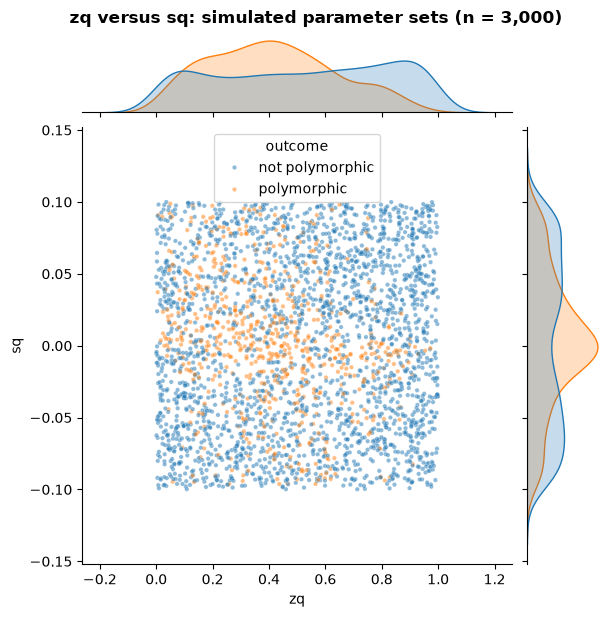

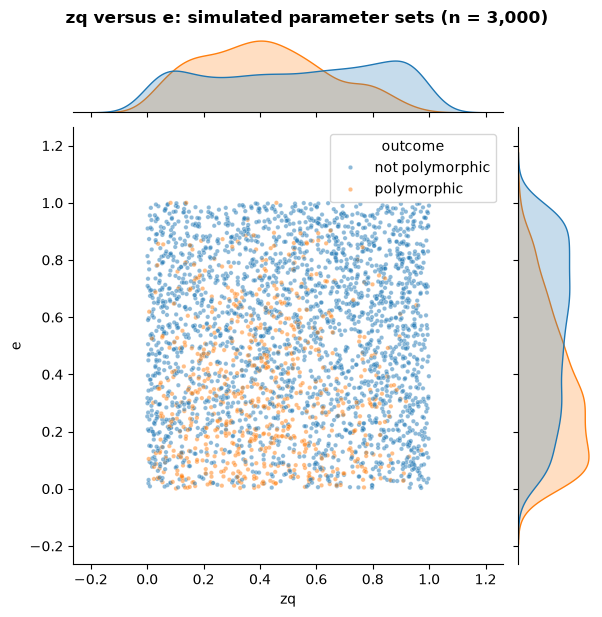

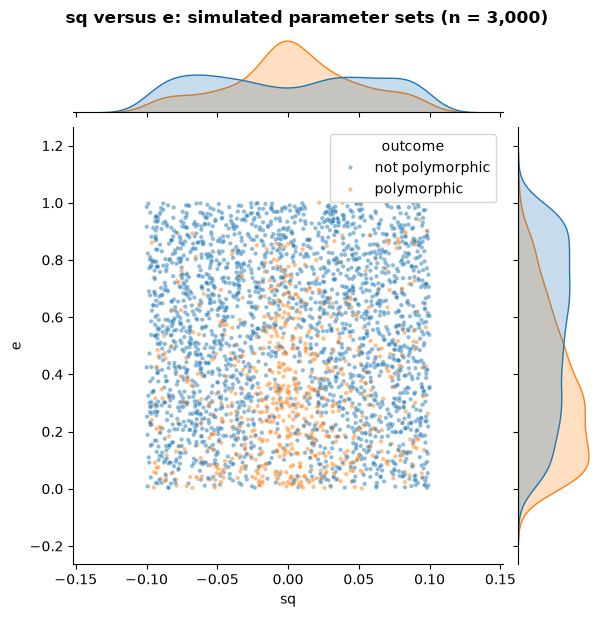

In [51]:
### --- Jointplots of the Top Pairs of Features (raw data, no model) --- ###
top3 = list(shap_importance['Feature'].head(3))
n_joint = min(3000, len(df_model))
plot_data = df_model.assign(outcome = df_model[target_col].map({0: 'not polymorphic', 1: 'polymorphic'})).sample(n_joint, random_state = random_seed)

for f1, f2 in itertools.combinations(top3, 2):
    g = sns.jointplot(data = plot_data, x = f1, y = f2, hue = 'outcome', kind = 'scatter',
                      s = 10, alpha = 0.5, height = 6, marginal_kws = {'common_norm': False})
    g.figure.suptitle(f'{f1} versus {f2}: simulated parameter sets (n = {n_joint:,})', y = 1.02, fontweight = 'bold')
    plt.show()

In [52]:
### --- Helpers: Binning, Observed Rates and 2D Partial Dependence --- ###
def bin_centers(feature, n_bins):
    """Centres of the bins of a feature (one value per integer for the counts Nq and Nm)."""
    lo_, hi_ = PARAM_RANGES[feature]
    if feature in ('Nq', 'Nm'):
        return np.arange(lo_, hi_ + 1, dtype = float)
    edges = np.linspace(lo_, hi_, n_bins + 1)
    return (edges[:-1] + edges[1:]) / 2

def bin_index(values, feature, n_bins):
    """Index of the bin of every value."""
    lo_, hi_ = PARAM_RANGES[feature]
    if feature in ('Nq', 'Nm'):
        return (np.rint(np.asarray(values)) - lo_).astype(int)
    edges = np.linspace(lo_, hi_, n_bins + 1)
    return np.clip(np.digitize(values, edges[1:-1]), 0, n_bins - 1)

def axis_extent(feature, n_bins):
    """Plot extent (left, right) of a feature axis."""
    lo_, hi_ = PARAM_RANGES[feature]
    return (lo_ - 0.5, hi_ + 0.5) if feature in ('Nq', 'Nm') else (lo_, hi_)

def empirical_rate_grid(data, f1, f2, n_bins):
    """Observed share of polymorphic parameter sets in every (f1, f2) cell. Rows follow f2, columns follow f1."""
    n1, n2 = len(bin_centers(f1, n_bins)), len(bin_centers(f2, n_bins))
    i = bin_index(data[f1].to_numpy(), f1, n_bins)
    j = bin_index(data[f2].to_numpy(), f2, n_bins)
    positives = np.zeros((n2, n1))
    counts = np.zeros((n2, n1))
    np.add.at(positives, (j, i), data[target_col].to_numpy())
    np.add.at(counts, (j, i), 1)
    return np.where(counts > 0, positives / np.maximum(counts, 1), np.nan), counts

def pdp_2d(model, background, f1, f2, grid1, grid2):
    """2D partial dependence: average predicted probability when (f1, f2) are set to every grid combination.

    All the other features keep the values of the `background` rows. Rows follow f2, columns follow f1.
    """
    out = np.zeros((len(grid2), len(grid1)))
    modified = background.copy()
    for a, v1 in enumerate(grid1):
        for b, v2 in enumerate(grid2):
            modified[f1] = v1
            modified[f2] = v2
            out[b, a] = model.predict_proba(modified)[:, 1].mean()
    return out

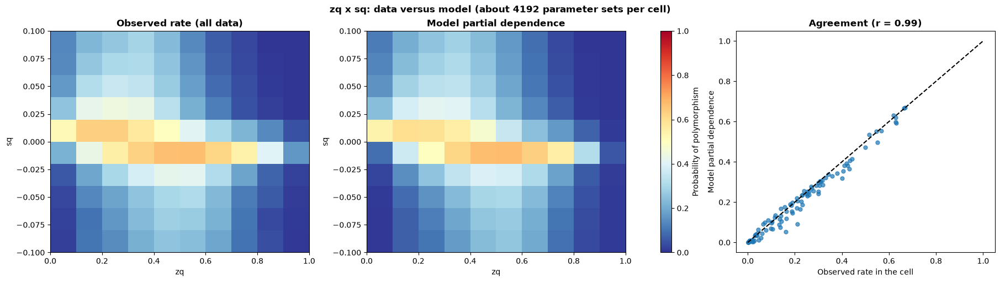

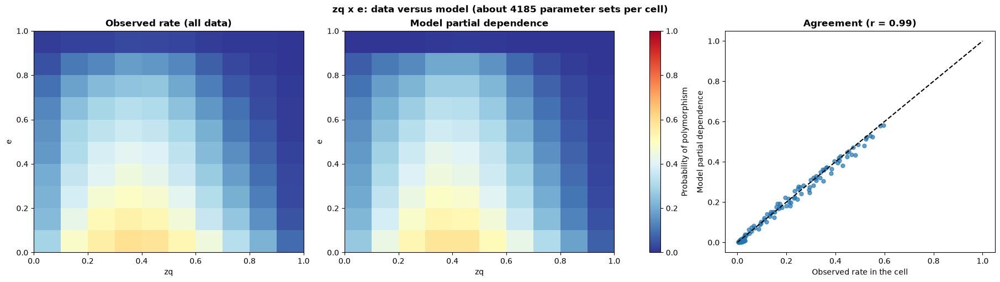

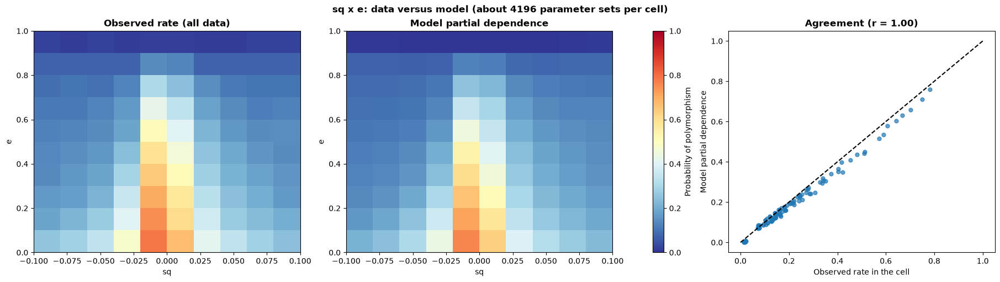

In [53]:
### --- Observed Rate Versus Model Partial Dependence for the Top Pairs --- ###
n_bins_pair = 10
background_pairs = X_train.sample(n = 300, random_state = random_seed)

for f1, f2 in itertools.combinations(top3, 2):
    g1, g2 = bin_centers(f1, n_bins_pair), bin_centers(f2, n_bins_pair)
    emp, counts = empirical_rate_grid(df_model, f1, f2, n_bins_pair)
    pdp = pdp_2d(best_xgb, background_pairs, f1, f2, g1, g2)

    fig, axes = plt.subplots(1, 3, figsize = (18, 5), layout = 'constrained')
    extent = [*axis_extent(f1, n_bins_pair), *axis_extent(f2, n_bins_pair)]
    for ax, arr, title in [(axes[0], emp, 'Observed rate (all data)'), (axes[1], pdp, 'Model partial dependence')]:
        im = ax.imshow(arr, origin = 'lower', extent = extent, aspect = 'auto', vmin = 0, vmax = 1, cmap = 'RdYlBu_r')
        ax.set_xlabel(f1); ax.set_ylabel(f2); ax.set_title(title, fontweight = 'bold')
    fig.colorbar(im, ax = axes[:2], label = 'Probability of polymorphism')

    ok = ~np.isnan(emp)
    axes[2].scatter(emp[ok], pdp[ok], s = 25, alpha = 0.7)
    axes[2].plot([0, 1], [0, 1], 'k--')
    axes[2].set_xlabel('Observed rate in the cell'); axes[2].set_ylabel('Model partial dependence')
    axes[2].set_title(f'Agreement (r = {np.corrcoef(emp[ok], pdp[ok])[0, 1]:.2f})', fontweight = 'bold')
    fig.suptitle(f'{f1} x {f2}: data versus model (about {int(np.median(counts[counts > 0]))} parameter sets per cell)', fontweight = 'bold')
    plt.show()

> **Takeaway.** The model reproduces the observed rates very well for the three pairs (correlation between observed and model cells of 0.99 for `zq` x `sq` and `zq` x `e`, 1.00 for `sq` x `e`, with about 4,200 parameter sets per cell, so the cells are well supported). The only systematic difference is a slight under-estimation by the model in the cells with the highest rates (`sq` x `e`). The analyses based on the model can therefore be trusted for these pairs. In the maps, the polymorphism of `zq` x `sq` is a horizontal band at `sq` close to 0 for `zq` between about 0.1 and 0.7, that of `sq` x `e` is a vertical band at `sq` close to 0 that is higher where `e` is small, and `zq` x `e` shows a hump in `zq` whose height falls as `e` increases. In these three maps the picture along one parameter changes mostly in height with the other, and Section 14.10 confirms that `zq` x `e` is almost additive (it closes 0.6% of the additive-to-full gap) and `sq` x `e` nearly so (2%), whereas `zq` x `sq` is the third strongest pair (10%). Interactions that appear as *diagonal* or *curved* boundaries are found for other pairs, in Sections 14.6, 14.10 and 14.11.

### **14.6 A Specific Hypothesis: Dominance in Queens and Workers**

**The expectation.** If an allele is good for one caste and bad for the other, theory on antagonistic selection suggests that polymorphism is easiest to maintain when the allele is **dominant in the caste that it benefits** and **recessive in the caste that it harms** (*dominance reversal*). Which caste an allele benefits follows from the generator: the colony fecundity is `max(0, (1 - queen phenotype) x worker phenotype)`, so raising the queen phenotype is costly and raising the worker phenotype is beneficial. A **positive** `sq` therefore favours **workers** and a **negative** `sq` favours **queens**. Applied to our model:

| Sign of `sq` | Allele favours | Expected relation for polymorphism | Where it lies in the (`dq`, `dw`) map |
|---|---|---|---|
| **Negative** | Queens | polymorphism more frequent when `dq > dw` | below the diagonal |
| **Positive** | Workers | polymorphism more frequent when `dq < dw` | above the diagonal |

**The approach.** We answer in three steps, from the fewest to the most assumptions:

1. **Directly on the simulation data.** The parameters were drawn independently of each other, so the dominance relation is **not confounded** with any other parameter: a difference in the observed polymorphism rate between `dq < dw` and `dq > dw`, within a sign of `sq`, can be attributed to the dominance relation. This uses all the simulated parameter sets and no model. We test the association of the relation with the **outcome** (polymorphism), not with the other inputs, which are independent by construction.
2. **With the model.** A 2D partial dependence in the (`dq`, `dw`) plane, computed separately for each sign of `sq`, on the **same grid** so that the two maps can be subtracted.
3. **Agreement** between the two.

**Step 1a. Observed rates, with confidence intervals.** For each sign of `sq`, the observed polymorphism rate when `dq < dw` and when `dq > dw`, with 95% Wilson intervals, and the difference between the two with a 95% bootstrap interval.

In [54]:
### --- Observed Polymorphism Rates by Sign of sq and dq / dw Relation (all data) --- ###
# Expected relation under dominance reversal, from the generator's fecundity max(0, (1 - queen phenotype) x worker phenotype):
# sq < 0 favours queens (dominant in queens, recessive in workers: dq > dw), sq > 0 favours workers (dq < dw).
EXPECTED_RELATION = {'sq < 0': 'dq > dw', 'sq > 0': 'dq < dw'}

dom = df_model.assign(
    sq_sign = np.where(df_model['sq'] < 0, 'sq < 0', 'sq > 0'),
    relation = np.where(df_model['dq'] < df_model['dw'], 'dq < dw', 'dq > dw'))

rng_dom = np.random.default_rng(random_seed)
rate_rows = []
for sign, expected in EXPECTED_RELATION.items():
    counts_ = {}
    for rel in ['dq < dw', 'dq > dw']:
        subset = dom[(dom['sq_sign'] == sign) & (dom['relation'] == rel)][target_col]
        k, n = int(subset.sum()), len(subset)
        low, high = wilson_ci(k, n)
        counts_[rel] = (n, k / n)
        rate_rows.append({'sq': sign, 'relation': rel, 'n': n, 'observed rate': k / n,
                          '95% CI low': low, '95% CI high': high})
    # Difference rate(dq < dw) - rate(dq > dw), with a parametric bootstrap interval.
    (n_lt, p_lt), (n_gt, p_gt) = counts_['dq < dw'], counts_['dq > dw']
    diff = p_lt - p_gt
    draws = rng_dom.binomial(n_lt, p_lt, 5000) / n_lt - rng_dom.binomial(n_gt, p_gt, 5000) / n_gt
    d_low, d_high = np.percentile(draws, [2.5, 97.5])
    expected_sign = +1 if expected == 'dq < dw' else -1
    if d_low > 0 or d_high < 0:
        verdict = 'consistent with dominance reversal' if np.sign(diff) == expected_sign else 'OPPOSITE to dominance reversal'
    else:
        verdict = 'inconclusive (the interval contains 0)'
    print(f'{sign}: rate(dq<dw) - rate(dq>dw) = {diff:+.3f}  [95% CI {d_low:+.3f}, {d_high:+.3f}]  ->  {verdict}')

display(pd.DataFrame(rate_rows).set_index(['sq', 'relation']).round(3))

sq < 0: rate(dq<dw) - rate(dq>dw) = -0.128  [95% CI -0.131, -0.124]  ->  consistent with dominance reversal
sq > 0: rate(dq<dw) - rate(dq>dw) = +0.120  [95% CI +0.117, +0.124]  ->  consistent with dominance reversal


n  observed rate  95% CI low  95% CI high
sq     relation                                                
sq < 0 dq < dw   104863          0.168       0.165        0.170
       dq > dw   104897          0.295       0.293        0.298
sq > 0 dq < dw   104970          0.278       0.276        0.281
       dq > dw   104790          0.158       0.156        0.160

**Step 1b. The whole picture along `dq - dw`.** The same observed rates, now along the *difference* `D = dq - dw` (bins of width 0.2) instead of just its sign, with 95% Wilson intervals. Under dominance reversal, the rate for negative `sq` should **decrease** with `D` and the rate for positive `sq` should **increase**.

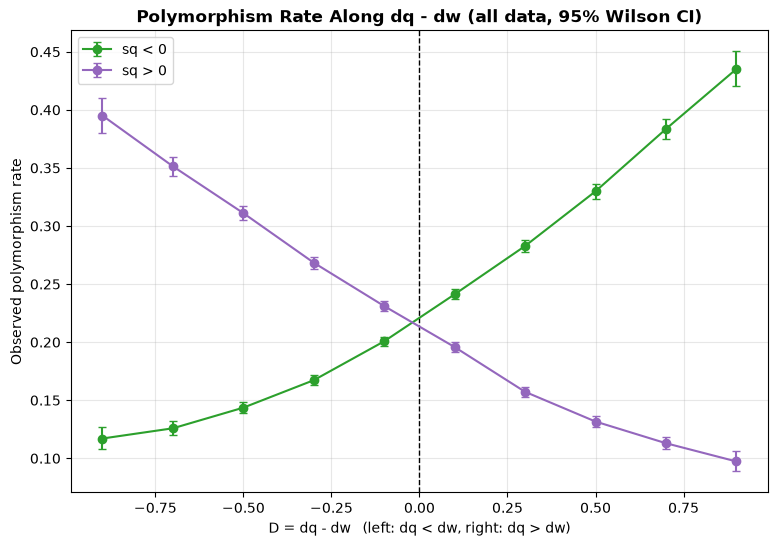

In [55]:
### --- Observed Polymorphism Rate Along D = dq - dw, by Sign of sq --- ###
dom['D'] = dom['dq'] - dom['dw']
dom['D_bin'] = pd.cut(dom['D'], np.linspace(-1, 1, 11), include_lowest = True)

fig, ax = plt.subplots(figsize = (9, 6))
for sign, color in [('sq < 0', 'tab:green'), ('sq > 0', 'tab:purple')]:
    g = dom[dom['sq_sign'] == sign].groupby('D_bin', observed = True)[target_col].agg(['sum', 'count'])
    centers = np.array([iv.mid for iv in g.index])
    rate = (g['sum'] / g['count']).to_numpy()
    ci = np.array([wilson_ci(k, n) for k, n in zip(g['sum'], g['count'])])
    ax.errorbar(centers, rate, yerr = [rate - ci[:, 0], ci[:, 1] - rate], marker = 'o', capsize = 3, color = color, label = sign)
ax.axvline(0, color = 'black', linestyle = '--', linewidth = 1)
ax.set_xlabel('D = dq - dw   (left: dq < dw, right: dq > dw)')
ax.set_ylabel('Observed polymorphism rate')
ax.set_title('Polymorphism Rate Along dq - dw (all data, 95% Wilson CI)', fontweight = 'bold')
ax.legend()
ax.grid(alpha = 0.3)
plt.show()

**Step 2. Maps in the (`dq`, `dw`) plane.** Top row: observed rates in 8 x 8 bins (all data). Bottom row: the model's partial dependence on the same grid, with 300 background parameter sets of the matching sign of `sq`. The dashed line is `dq = dw`. The right column is the difference *positive `sq` minus negative `sq`* (red: positive `sq` makes polymorphism more likely). The observed maps are noisy cell by cell; the model map is their smoothed version.

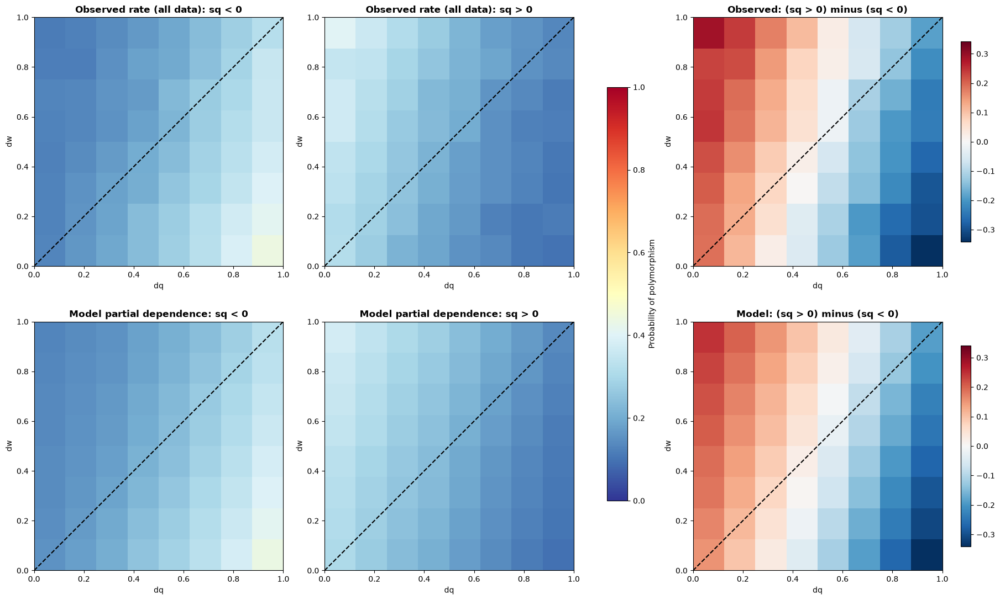

sq < 0: correlation between observed and model cells = 1.00, mean absolute difference = 0.010, median parameter sets per cell = 3270
sq > 0: correlation between observed and model cells = 0.99, mean absolute difference = 0.012, median parameter sets per cell = 3276


In [56]:
### --- Observed and Model-Based Maps in the (dq, dw) Plane --- ###
n_bins_dom = 8
grid_dom = bin_centers('dq', n_bins_dom)       # dq and dw share the same range, hence the same grid.
maps = {}
for sign, test_cond, all_cond in [('sq < 0', X_train['sq'] < 0, df_model['sq'] < 0),
                                  ('sq > 0', X_train['sq'] > 0, df_model['sq'] > 0)]:
    emp, counts = empirical_rate_grid(df_model[all_cond], 'dq', 'dw', n_bins_dom)
    background = X_train[test_cond].sample(n = 300, random_state = random_seed)
    maps[sign] = (emp, counts, pdp_2d(best_xgb, background, 'dq', 'dw', grid_dom, grid_dom))

fig, axes = plt.subplots(2, 3, figsize = (18, 11), layout = 'constrained')
for col, sign in enumerate(['sq < 0', 'sq > 0']):
    emp, counts, pdp = maps[sign]
    for row, (arr, name) in enumerate([(emp, 'Observed rate (all data)'), (pdp, 'Model partial dependence')]):
        ax = axes[row, col]
        im = ax.imshow(arr, origin = 'lower', extent = [0, 1, 0, 1], aspect = 'equal', vmin = 0, vmax = 1, cmap = 'RdYlBu_r')
        ax.plot([0, 1], [0, 1], 'k--')
        ax.set_title(f'{name}: {sign}', fontweight = 'bold')
        ax.set_xlabel('dq'); ax.set_ylabel('dw')
fig.colorbar(im, ax = axes[:, :2], shrink = 0.7, label = 'Probability of polymorphism')

for row, idx, name in [(0, 0, 'Observed'), (1, 2, 'Model')]:
    difference = maps['sq > 0'][idx] - maps['sq < 0'][idx]
    limit = np.nanmax(np.abs(difference))
    ax = axes[row, 2]
    im2 = ax.imshow(difference, origin = 'lower', extent = [0, 1, 0, 1], aspect = 'equal', vmin = -limit, vmax = limit, cmap = 'RdBu_r')
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_title(f'{name}: (sq > 0) minus (sq < 0)', fontweight = 'bold')
    ax.set_xlabel('dq'); ax.set_ylabel('dw')
    fig.colorbar(im2, ax = ax, shrink = 0.7)
plt.show()

### --- Step 3: Agreement Between the Observed Maps and the Model --- ###
for sign in ['sq < 0', 'sq > 0']:
    emp, counts, pdp = maps[sign]
    ok = ~np.isnan(emp)
    print(f'{sign}: correlation between observed and model cells = {np.corrcoef(emp[ok], pdp[ok])[0, 1]:.2f}, '
          f'mean absolute difference = {np.abs(emp[ok] - pdp[ok]).mean():.3f}, '
          f'median parameter sets per cell = {int(np.median(counts[counts > 0]))}')

> **Takeaway (dominance).** The three results agree, and they match the expectation of dominance reversal.
>
> 1. **Observed rates (Step 1a).** For negative `sq`, polymorphism is more frequent when `dq` > `dw` (29.5%) than when `dq` < `dw` (16.8%): the difference (rate for `dq` < `dw` minus rate for `dq` > `dw`) is -0.128 (95% interval -0.131 to -0.124), i.e. a factor 1.76. For positive `sq` it is the other way round: 27.8% when `dq` < `dw` against 15.8% when `dq` > `dw` (difference +0.120, interval +0.117 to +0.124), also a factor 1.76. Both are what the expectation predicts (dominant in the caste that the allele favours, recessive in the other), and since the parameters were drawn independently, the dominance relation is not confounded with another parameter.
> 2. **Shape (Step 1b).** Along `D` = `dq` - `dw` the two curves are monotone mirror images: the rate for negative `sq` rises from about 12% (`D` near -0.9) to about 44% (`D` near +0.9), and the rate for positive `sq` falls from about 40% to about 10%. They cross near `D` = 0 at a rate close to the overall 22%. It is the *difference* between the two dominance coefficients that matters, and its effect changes sign with `sq`, which is why `dq` and `dw` look flat on average in the SHAP curves of Section 14.3.
> 3. **Maps (Step 2).** The model reproduces the observed maps (correlation 1.00 for negative and 0.99 for positive `sq`, mean absolute difference 0.010 and 0.012, about 3,270 parameter sets per cell). A conclusion that holds in the raw data **and** in the model is much stronger than one that appears in the model alone.
>
> The effect is moderate in size (a factor of about 1.8 between the two sides) compared with `zq`, `sq` or `e`, and it depends on the sign of `sq`, which is why `dq` x `sq` is one of the strongest pairs of the screen (Section 14.10). The direction is the same as in the previous two-caste model (Section 14.12). Whether the mechanism is the one of the theory (dominance reversal) rests on the sign convention below.


> **Sign convention (checked against the generator).** The table above follows the generator `dataset_generator_3way_model_on_CPU.py`: the colony fecundity is `max(0, (1 - queen phenotype) x worker phenotype)` and `sq` raises both phenotypes, so a *positive* `sq` favours **workers** and a *negative* `sq` favours **queens**. The previous two-caste generator uses the same fecundity, which is why the pattern is the same in both models.

### **14.7 Distillation: Can a Small Model Reproduce the Black Box?**

SHAP and PDPs describe XGBoost one feature or one pair at a time. **Distillation** takes another route: train a small, readable **student** model to imitate the **teacher** (XGBoost). The student is a decision tree trained on the teacher's *predicted probabilities* (soft labels). It can see as many examples as we want, because querying XGBoost is almost free, while a new simulation takes minutes. We draw 200,000 new parameter sets uniformly from the documented ranges (the same distribution as the original design), label them with the teacher, and fit trees of increasing depth.

Two things are measured for every depth:

- **Fidelity**: how well the student reproduces the **teacher** on 50,000 held-out synthetic parameter sets (R^2 of the probabilities, and share of identical 0/1 decisions at the teacher's F1-optimal threshold).
- **PR AUC and ROC AUC on the real test labels**, compared with a tree of the same depth trained **directly** on the real training labels. This tells whether distillation actually helps.

> **Caveat.** The student explains the *teacher*, not the simulator. High fidelity means the rules describe XGBoost well; the rules are only as true as XGBoost is. Any rule that matters biologically should be checked with fresh simulations.

,model,depth,leaves,fidelity R2,agreement with teacher,test PR AUC,test ROC AUC,direct tree: test PR AUC,direct tree: test ROC AUC
0,Teacher (XGBoost),NaN,NaN,1.000,1.000,0.958,0.987,NaN,NaN
1,Distilled tree,2.0,4.0,0.157,0.773,0.351,0.713,0.352,0.714
2,Distilled tree,3.0,8.0,0.203,0.773,0.397,0.755,0.399,0.755
3,Distilled tree,4.0,16.0,0.296,0.807,0.484,0.801,0.494,0.804
4,Distilled tree,5.0,32.0,0.358,0.815,0.543,0.832,0.551,0.834
5,Distilled tree,6.0,64.0,0.435,0.831,0.599,0.861,0.613,0.865
6,Distilled tree,8.0,232.0,0.595,0.874,0.720,0.910,0.726,0.910
7,Distilled tree,10.0,646.0,0.701,0.900,0.788,0.935,0.799,0.937


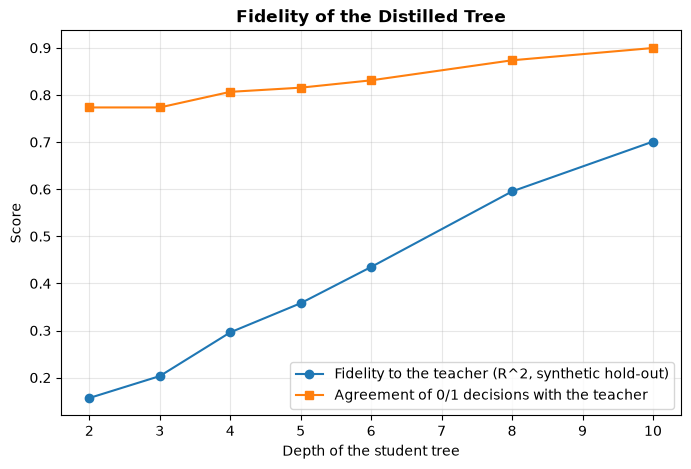

In [57]:
### --- Distillation: Student Trees Trained on the Teacher's Probabilities --- ###
def sample_parameter_space(n, rng):
    """Draw n parameter sets uniformly within the documented ranges (integers for Nq and Nm)."""
    columns = {}
    for f in feature_cols:
        lo_, hi_ = PARAM_RANGES[f]
        columns[f] = rng.integers(lo_, hi_ + 1, n).astype(float) if f in ('Nq', 'Nm') else rng.uniform(lo_, hi_, n)
    return pd.DataFrame(columns)[feature_cols]

thr_teacher = RESULTS['XGBoost']['threshold']      # F1-optimal threshold of the teacher, used for the 0/1 agreement.
rng_syn = np.random.default_rng(random_seed)
N_SYN = BUDGET['n_syn']                            # Synthetic parameter sets (three quarters to train the students, one quarter to test them).
N_SYN_TRAIN = int(0.75 * N_SYN)
X_syn = sample_parameter_space(N_SYN, rng_syn)
p_syn = best_xgb.predict_proba(X_syn)[:, 1]        # Teacher's soft labels.
X_syn_tr, X_syn_ho = X_syn.iloc[:N_SYN_TRAIN], X_syn.iloc[N_SYN_TRAIN:]
p_syn_tr, p_syn_ho = p_syn[:N_SYN_TRAIN], p_syn[N_SYN_TRAIN:]

teacher_test_proba = best_xgb.predict_proba(X_test)[:, 1]
rows = [{'model': 'Teacher (XGBoost)', 'depth': np.nan, 'leaves': np.nan, 'fidelity R2': 1.0, 'agreement with teacher': 1.0,
         'test PR AUC': average_precision_score(y_test, teacher_test_proba), 'test ROC AUC': roc_auc_score(y_test, teacher_test_proba),
         'direct tree: test PR AUC': np.nan, 'direct tree: test ROC AUC': np.nan}]

for depth in [2, 3, 4, 5, 6, 8, 10]:
    student = DecisionTreeRegressor(max_depth = depth, min_samples_leaf = 50, random_state = random_seed).fit(X_syn_tr, p_syn_tr)
    p_ho = student.predict(X_syn_ho)
    p_te = student.predict(X_test)
    direct = DecisionTreeClassifier(max_depth = depth, min_samples_leaf = 50, random_state = random_seed).fit(X_train, y_train)
    p_direct = direct.predict_proba(X_test)[:, 1]
    rows.append({'model': 'Distilled tree', 'depth': depth, 'leaves': student.get_n_leaves(),
                 'fidelity R2': r2_score(p_syn_ho, p_ho),
                 'agreement with teacher': ((p_ho >= thr_teacher) == (p_syn_ho >= thr_teacher)).mean(),
                 'test PR AUC': average_precision_score(y_test, p_te), 'test ROC AUC': roc_auc_score(y_test, p_te),
                 'direct tree: test PR AUC': average_precision_score(y_test, p_direct),
                 'direct tree: test ROC AUC': roc_auc_score(y_test, p_direct)})

distill_table = pd.DataFrame(rows)
display(distill_table.round(3))

plt.figure(figsize = (8, 5))
sub = distill_table.dropna(subset = ['depth'])
plt.plot(sub['depth'], sub['fidelity R2'], marker = 'o', label = 'Fidelity to the teacher (R^2, synthetic hold-out)')
plt.plot(sub['depth'], sub['agreement with teacher'], marker = 's', label = 'Agreement of 0/1 decisions with the teacher')
plt.xlabel('Depth of the student tree')
plt.ylabel('Score')
plt.title('Fidelity of the Distilled Tree', fontweight = 'bold')
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()

The table shows how deep the student has to be to reproduce the teacher, and whether a distilled tree beats a tree of the same size trained directly on the real labels. Below, one student is shown as rules (choose `STUDENT_DEPTH` where the fidelity curve starts to flatten, trading precision for readability). Each leaf gives the teacher's average predicted probability of polymorphism for all the parameter sets that satisfy the conditions on its path.

Student of depth 5: 32 leaves, fidelity R2 = 0.358 on held-out synthetic data.

|--- e <= 0.596
|   |--- zq <= 0.720
|   |   |--- sq <= -0.041
|   |   |   |--- dq <= 0.515
|   |   |   |   |--- s <= 0.693
|   |   |   |   |   |--- value: [0.070]
|   |   |   |   |--- s >  0.693
|   |   |   |   |   |--- value: [0.247]
|   |   |   |--- dq >  0.515
|   |   |   |   |--- zq <= 0.169
|   |   |   |   |   |--- value: [0.110]
|   |   |   |   |--- zq >  0.169
|   |   |   |   |   |--- value: [0.436]
|   |   |--- sq >  -0.041
|   |   |   |--- sq <= 0.024
|   |   |   |   |--- sq <= -0.018
|   |   |   |   |   |--- value: [0.419]
|   |   |   |   |--- sq >  -0.018
|   |   |   |   |   |--- value: [0.686]
|   |   |   |--- sq >  0.024
|   |   |   |   |--- dq <= 0.482
|   |   |   |   |   |--- value: [0.416]
|   |   |   |   |--- dq >  0.482
|   |   |   |   |   |--- value: [0.198]
|   |--- zq >  0.720
|   |   |--- sq <= 0.011
|   |   |   |--- sq <= -0.019
|   |   |   |   |--- om <= 0.752
|   |   |   |   |   |-

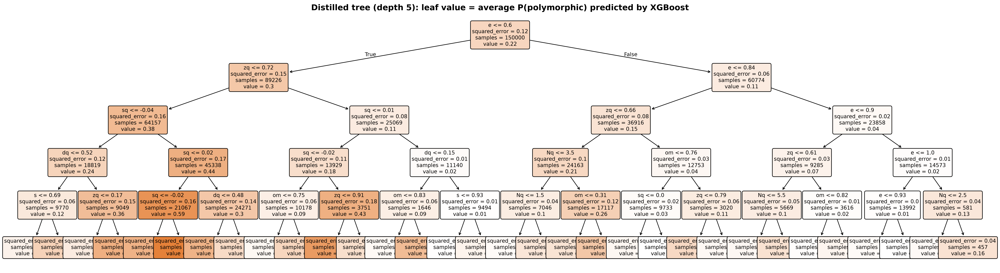

In [58]:
### --- The Chosen Student Tree as Readable Rules --- ###
STUDENT_DEPTH = 5
student = DecisionTreeRegressor(max_depth = STUDENT_DEPTH, min_samples_leaf = 50, random_state = random_seed).fit(X_syn_tr, p_syn_tr)

print(f'Student of depth {STUDENT_DEPTH}: {student.get_n_leaves()} leaves, '
      f'fidelity R2 = {r2_score(p_syn_ho, student.predict(X_syn_ho)):.3f} on held-out synthetic data.\n')
print(export_text(student, feature_names = feature_cols, decimals = 3))

plt.figure(figsize = (30, 8), dpi = 300)
plot_tree(student, feature_names = feature_cols, filled = True, rounded = True, fontsize = 9, precision = 2)
plt.title(f'Distilled tree (depth {STUDENT_DEPTH}): leaf value = average P(polymorphic) predicted by XGBoost', fontsize = 14, fontweight = 'bold')
plt.show()

> **Takeaway.** Distillation turns the black box into explicit conditions on the parameters, but only the coarse structure of XGBoost survives. The first split of the depth-5 student is on `e` (at 0.596), followed by splits on `zq`, `sq`, `dq`, `om`, `s` and `Nq`: these are the same seven parameters as the top of the SHAP ranking (`zq`, `sq`, `e`, `om`, `dq`, `s`, `Nq`), and `dw`, `mm`, `mq` and `Nm` never appear, so the two views agree on *which* parameters matter. The highest leaves (probability 0.69 and 0.55) correspond to `e` <= 0.6 with `sq` within about 0.02 of 0 and `zq` below 0.91, in line with the peaks seen in Section 14.4. The limit of the approach is the fidelity table: the depth-5 student reproduces only 36% of the variance of the teacher's probabilities (R^2 = 0.358), and 70% at depth 10 (646 leaves); its test PR AUC (0.543 at depth 5) is far from the teacher's (0.958), and it is no better than a tree of the same depth trained directly on the real labels (0.551), so distillation brings no gain in accuracy here. The rules are **hypotheses about the simulator**, generated by a model, and the decisive test of a rule is a set of fresh simulations at parameter values chosen to confirm or contradict it (Section 15). Sections 14.8 to 14.10 look for better alternatives.


### **14.8 Why Did Distillation Struggle, and Which Student Fits Better?**

The depth-5 student of Section 14.7 explains only about 36% of the variance of the teacher's probabilities (R^2 = 0.358), and even a depth-10 tree with 646 leaves reaches only 70%. A distilled tree is also no better than a tree of the same depth trained directly on the real labels (test PR AUC 0.543 against 0.551 at depth 5). This is information about the simulator, not only a weakness of the method:

1. **The boundaries are oblique.** The maps of Sections 14.5 and 14.11 show polymorphism concentrated in **diagonal bands** along `om - zq`, and the maps of Section 14.6 show gradients along `dq - dw` that change direction with the sign of `sq`. A tree can only cut parallel to the axes, so every oblique boundary has to be approximated by a staircase of splits.
2. **A few pairs carry most of the structure** (Section 14.10), and the probability goes from near 0 to high values across narrow bands, while 77.5% of the parameter sets are non polymorphic. A tree with few leaves has to spend a large part of them describing the flat region where the probability is close to 0.

Two simple changes of the student address these points. Both are compared with the depth-limited tree **at the same number of regions**, on the same 150,000 teacher-labelled parameter sets and the same 50,000 held-out ones:

| Student | Idea |
|---|---|
| **Best-first tree** (`max_leaf_nodes`) | Grows the leaf that reduces the error most, instead of growing every branch to the same depth. The leaves are spent where the teacher varies most. |
| **Model tree** | A shallow tree cuts the space into a few regions, and **one linear equation on the teacher's log-odds is fitted in every region**. A region is no longer a constant, so a slanted boundary costs one region instead of a staircase. |

> **Note.** A region of a model tree costs twelve numbers (an intercept and eleven coefficients) instead of one. The comparison at equal *regions* therefore favours the model tree.

fidelity R2  agreement with teacher  \
student                     regions                                        
Depth-limited tree          4              0.157                   0.773   
                            8              0.203                   0.773   
                            16             0.296                   0.807   
                            32             0.358                   0.815   
                            64             0.435                   0.831   
Best-first tree             4              0.171                   0.773   
                            8              0.268                   0.818   
                            16             0.352                   0.827   
                            32             0.464                   0.854   
                            64             0.563                   0.879   
Model tree (linear regions) 2             -0.029                   0.773   
                            4              0.096                   0.793   
                            8              0.264                   0.818   
                            16             0.337                   0.831   

                                     test PR AUC  test ROC AUC  
student                     regions                             
Depth-limited tree          4              0.351         0.713  
                            8              0.397         0.755  
                            16             0.484         0.801  
                            32             0.543         0.832  
                            64             0.599         0.861  
Best-first tree             4              0.376         0.709  
                            8              0.488         0.742  
                            16             0.553         0.807  
                            32             0.633         0.850  
                            64             0.697         0.875  
Model tree (linear regions) 2              0.427         0.769  
                            4              0.498         0.786  
                            8              0.580         0.851  
                            16             0.641         0.873

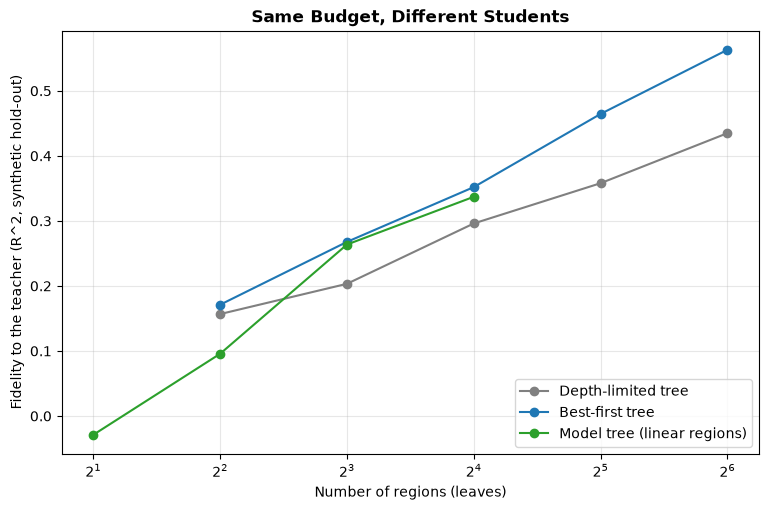

In [59]:
### --- Better Students: Best-First Trees and Model Trees at the Same Budget --- ###
def logit_clip(p, eps = 1e-3):
    """Log-odds of a probability, clipped away from 0 and 1."""
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def fit_model_tree(X_fit, p_fit, depth, min_leaf = 2000, alpha = 1e-3):
    """Model tree: a shallow tree partitions the space, a ridge regression on the log-odds is fitted in every region."""
    partition = DecisionTreeRegressor(max_depth = depth, min_samples_leaf = min_leaf, random_state = random_seed).fit(X_fit, p_fit)
    region_of = partition.apply(X_fit)
    equations = {r: Ridge(alpha = alpha).fit(X_fit[region_of == r], logit_clip(p_fit[region_of == r])) for r in np.unique(region_of)}
    return partition, equations


def predict_model_tree(model, X_new):
    """Probability predicted by a model tree (each region applies its own linear equation on the log-odds)."""
    partition, equations = model
    region_of = partition.apply(X_new)
    out = np.zeros(len(X_new))
    for r, reg in equations.items():
        mask = region_of == r
        if mask.any():
            out[mask] = 1 / (1 + np.exp(-reg.predict(X_new[mask])))
    return out


student_rows = []
def score_student(family, regions, p_holdout, p_test):
    """Fidelity to the teacher (synthetic hold-out) and PR AUC on the real test labels."""
    student_rows.append({'student': family, 'regions': regions,
                         'fidelity R2': r2_score(p_syn_ho, p_holdout),
                         'agreement with teacher': ((p_holdout >= thr_teacher) == (p_syn_ho >= thr_teacher)).mean(),
                         'test PR AUC': average_precision_score(y_test, p_test),
                         'test ROC AUC': roc_auc_score(y_test, p_test)})

for depth in [2, 3, 4, 5, 6]:
    t = DecisionTreeRegressor(max_depth = depth, min_samples_leaf = 50, random_state = random_seed).fit(X_syn_tr, p_syn_tr)
    score_student('Depth-limited tree', t.get_n_leaves(), t.predict(X_syn_ho), t.predict(X_test))
for leaves in [4, 8, 16, 32, 64]:
    t = DecisionTreeRegressor(max_leaf_nodes = leaves, min_samples_leaf = 50, random_state = random_seed).fit(X_syn_tr, p_syn_tr)
    score_student('Best-first tree', t.get_n_leaves(), t.predict(X_syn_ho), t.predict(X_test))
for depth in [1, 2, 3, 4]:
    mt = fit_model_tree(X_syn_tr, p_syn_tr, depth)
    score_student('Model tree (linear regions)', len(mt[1]), predict_model_tree(mt, X_syn_ho), predict_model_tree(mt, X_test))

student_table = pd.DataFrame(student_rows)
display(student_table.round(3).set_index(['student', 'regions']))

plt.figure(figsize = (9, 5.5))
for family, color in [('Depth-limited tree', 'gray'), ('Best-first tree', 'tab:blue'), ('Model tree (linear regions)', 'tab:green')]:
    sub = student_table[student_table['student'] == family]
    plt.plot(sub['regions'], sub['fidelity R2'], marker = 'o', color = color, label = family)
plt.xscale('log', base = 2)
plt.xlabel('Number of regions (leaves)')
plt.ylabel('Fidelity to the teacher (R^2, synthetic hold-out)')
plt.title('Same Budget, Different Students', fontweight = 'bold')
plt.legend(loc = 'lower right')
plt.grid(alpha = 0.3)
plt.show()

> **Takeaway.** At the same number of leaves, a **best-first tree follows the teacher better** than a depth-limited tree from 8 leaves onwards (64 leaves: R^2 = 0.56 against 0.44; 32 leaves: 0.46 against 0.36), because its leaves are not wasted on the flat region where the probability is near 0. The **model trees** are mixed. With 4 regions their fidelity is lower than that of a depth-limited tree (R^2 = 0.10 against 0.16, and negative with 2 regions), from 8 regions on they are as good as the best-first tree (R^2 = 0.26 against 0.27 at 8 regions, 0.34 against 0.35 at 16), and their test PR AUC is higher than that of both trees at the same number of regions (0.58 against 0.40 and 0.49 at 8 regions, 0.64 against 0.48 and 0.55 at 16), because a linear equation on the log-odds follows a slanted boundary better than a constant. They pay for it with twelve numbers per region (see the note above), so they are no easier to read than a larger tree. No student approaches the fidelity of the teacher with a handful of rules (best R^2: 0.56 with 64 leaves, 0.70 with the 646 leaves of a depth-10 tree): the next section asks whether a different kind of readable model does better.


### **14.9 A Glass-Box Alternative: the Explainable Boosting Machine**

Distillation tries to *copy* a black box into a readable form. Another route is to ask whether a model that is **readable by construction** can match the black box in the first place. The **Explainable Boosting Machine (EBM)** is a boosted additive model:

$$\text{log-odds} = \beta_0 + \sum_j f_j(x_j) + \sum_{(j,k)} f_{jk}(x_j, x_k)$$

Every term is a small function of one feature (a **shape function**) or of two features (a **heat map**) that can be plotted and read directly. The trees inside are only used to learn these functions, one feature at a time and with a very small learning rate, so the model never mixes more than two features in a term. A first automatic step (FAST) chooses which pairs are worth adding.

This matters for the point raised about **SHAP interaction values**. They give a Shapley credit to *every* pair of features, which raises the number of "players" from 11 to 66 and stacks one more assumption on top of an approximate model (Section 14). In the EBM, the pairs are **few, chosen on the data, and part of the model itself**: nothing is decomposed afterwards, and a term's contribution is read straight off its plot.

The number of pairs is tuned with the common protocol of Section 7.1 (5-fold CV, ROC AUC as the primary metric), from 0 (purely additive model) to 20. The EBM is registered with the other models, so the usual train / validation / test table is printed.

> **Note.** `interpret` is not pre-installed on Google Colab; the import cell installs it if needed. This search is the slowest cell of Section 14 (about 15 minutes on two cores), because every candidate is an ensemble of boosted models. Remove the largest value of `interactions` to shorten it.

In [65]:
### --- Best Explainable Boosting Machine (Common Protocol) --- ###
ebm_space = {'interactions': BUDGET['ebm_interactions']}
ebm_rationale = {
    'interactions': 'Number of pairwise terms added to the eleven main effects. 0 = purely additive model (a GAM). The pairs are '
                    'chosen by the EBM itself (FAST). 20 is far below the 55 possible pairs, so the model stays readable.',
}

best_ebm_model = tune_model('EBM', ExplainableBoostingClassifier(random_state = random_seed, n_jobs = 1, outer_bags = 4),
                            ebm_space, ebm_rationale, n_iter = None)
display(hyperparam_table('EBM'))
display(RESULTS['EBM']['search_cv'][['param_interactions', 'mean_test_pr_auc', 'mean_test_roc_auc']]
        .rename(columns = {'param_interactions': 'pairs', 'mean_test_pr_auc': 'search PR AUC', 'mean_test_roc_auc': 'search ROC AUC'})
        .round(4).set_index('pairs'))
print('Terms of the selected EBM:', ', '.join(best_ebm_model.term_names_))


--- EBM: 4 configuration(s) x 5 folds searched on 40,000 rows, selected on ROC AUC; scores below: 5-fold CV on all 377,568 training rows ---
Selected hyperparameters: {'interactions': 20}


,PR AUC,ROC AUC
Train (mean of the 5 training folds),0.9165,0.9735
Validation (mean of the 5 validation folds),0.9066,0.9701
Validation (sd across the 5 folds),0.0014,0.0005
Test (held-out set),0.9077,0.9708


Random classifier: PR AUC = 0.225  |  ROC AUC = 0.500
Decision threshold maximising the F1 on the out-of-fold predictions: 0.414


,precision,recall,F1,MCC,balanced accuracy
out-of-fold (training rows),0.816,0.856,0.836,0.787,0.900
test set,0.814,0.859,0.836,0.787,0.901


,Model,Hyperparameter,Searched values,Chosen,Edge of range,Why this range
0,EBM,interactions,"[0, 5, 10, 20]",20,at upper cap,Number of pairwise terms added to the eleven main effects. 0 = purely additive model (a GAM). The pairs are chosen b...


,search PR AUC,search ROC AUC
pairs,,
0,0.6713,0.8634
5,0.8414,0.9474
10,0.8793,0.9597
20,0.8886,0.9635


Terms of the selected EBM: s, e, mq, mm, zq, dw, dq, sq, om, Nq, Nm, s & e, s & zq, s & sq, s & om, e & zq, e & dq, e & sq, e & om, e & Nq, mm & zq, zq & dw, zq & dq, zq & sq, zq & om, zq & Nq, dw & dq, dw & sq, dq & sq, sq & om, om & Nq


In [66]:
### --- Does the Glass Box Lose Anything? Comparison With XGBoost --- ###
p_ebm = best_ebm_model.predict_proba(X_test)[:, 1]
p_teacher = best_xgb.predict_proba(X_test)[:, 1]
y_arr = y_test.to_numpy()
thr_teacher = RESULTS['XGBoost']['threshold']       # F1-optimal threshold of the teacher (also used for the 0/1 agreement below).

# Paired bootstrap on the test set (1,000 resamples, same resamples for both models).
rng_ebm = np.random.default_rng(random_seed)
resamples = rng_ebm.integers(0, len(y_arr), size = (BUDGET['n_boot'], len(y_arr)))
d_pr = np.array([average_precision_score(y_arr[i], p_ebm[i]) - average_precision_score(y_arr[i], p_teacher[i]) for i in resamples])
d_auc = np.array([roc_auc_score(y_arr[i], p_ebm[i]) - roc_auc_score(y_arr[i], p_teacher[i]) for i in resamples])

compare = pd.DataFrame({
    'test PR AUC': [average_precision_score(y_test, p_teacher), average_precision_score(y_test, p_ebm)],
    'test ROC AUC': [roc_auc_score(y_test, p_teacher), roc_auc_score(y_test, p_ebm)],
    'Brier score': [brier_score_loss(y_test, p_teacher), brier_score_loss(y_test, p_ebm)],
    'log loss': [log_loss(y_test, p_teacher), log_loss(y_test, p_ebm)],
}, index = ['XGBoost (black box)', 'EBM (glass box)'])
display(compare.round(4))
print(f'EBM minus XGBoost, test PR AUC:  {d_pr.mean():+.4f}  [95% CI {np.percentile(d_pr, 2.5):+.4f}, {np.percentile(d_pr, 97.5):+.4f}]')
print(f'EBM minus XGBoost, test ROC AUC: {d_auc.mean():+.4f}  [95% CI {np.percentile(d_auc, 2.5):+.4f}, {np.percentile(d_auc, 97.5):+.4f}]')

# Fidelity, measured exactly like the students of Sections 14.7 and 14.8 (EBM trained on the real labels, not on the teacher's).
p_ebm_ho = best_ebm_model.predict_proba(X_syn_ho)[:, 1]
print(f'Fidelity of the EBM to XGBoost on the synthetic hold-out: R^2 = {r2_score(p_syn_ho, p_ebm_ho):.3f}, '
      f'agreement of the 0/1 decisions (at the teacher threshold {thr_teacher:.3f}) = {((p_ebm_ho >= thr_teacher) == (p_syn_ho >= thr_teacher)).mean():.3f}')


,test PR AUC,test ROC AUC,Brier score,log loss
XGBoost (black box),0.9576,0.9868,0.0380,0.1278
EBM (glass box),0.9077,0.9708,0.0546,0.1832


EBM minus XGBoost, test PR AUC:  -0.0499  [95% CI -0.0532, -0.0466]
EBM minus XGBoost, test ROC AUC: -0.0160  [95% CI -0.0171, -0.0151]
Fidelity of the EBM to XGBoost on the synthetic hold-out: R^2 = 0.905, agreement of the 0/1 decisions (at the teacher threshold 0.458) = 0.953


**Reading the EBM.** The first figure ranks the terms by their mean absolute contribution to the log-odds (main effects in one colour, pairs in another). The second shows the shape function of every main effect: the line is the contribution to the log-odds (above 0 favours polymorphism), and the band is the variation between the bagged models that the EBM averages, a direct measure of how well the data constrain that part of the curve. The third shows the strongest pairs as heat maps: **a pair term is what remains once the two main effects have been taken out**, so a blank map means that the two features act additively. Unlike a partial dependence plot, the contribution of a term does not change with the other features.

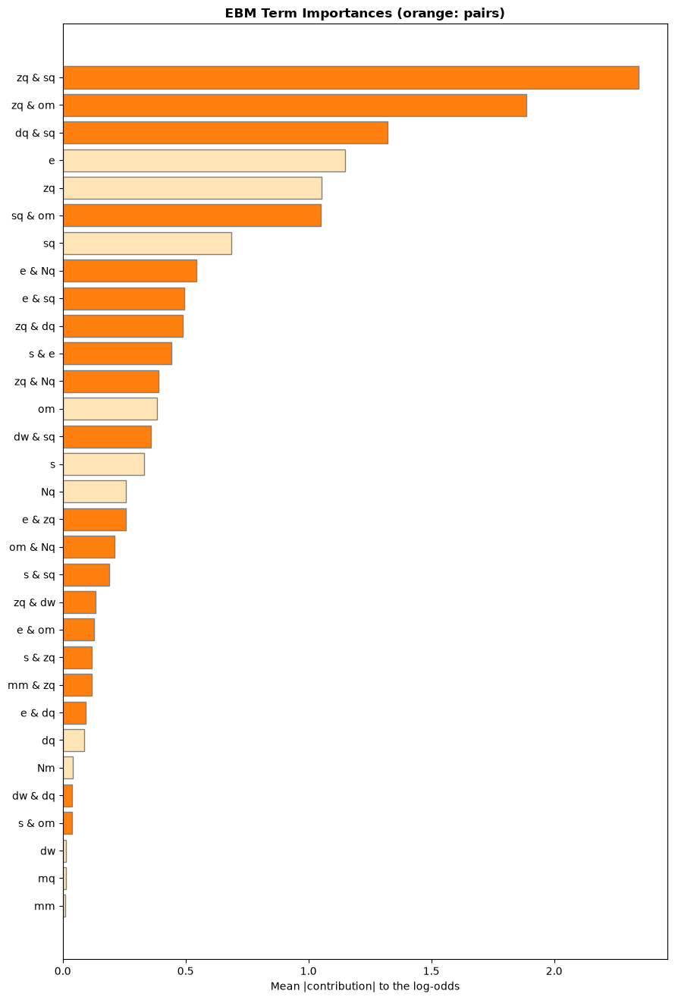

Main effects, most important first: e, zq, sq, om, s, Nq, dq, Nm, dw, mq, mm


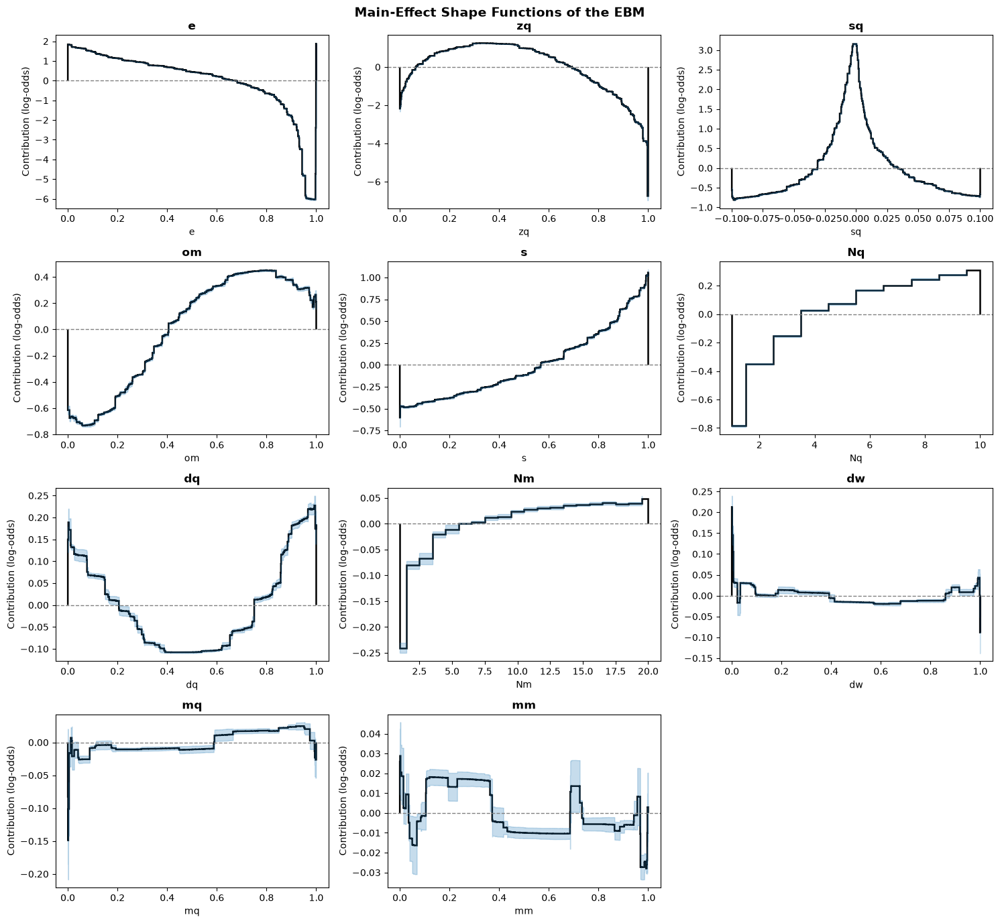

In [67]:
### --- Term Importances and Main-Effect Shape Functions of the EBM --- ###
ebm_global = best_ebm_model.explain_global()
term_names = list(best_ebm_model.term_names_)
term_importance = pd.Series(best_ebm_model.term_importances(), index = term_names).sort_values()

plt.figure(figsize = (9, 0.38 * len(term_importance) + 1.5))
plt.barh(term_importance.index, term_importance.values,
         color = ['tab:orange' if ' & ' in n else 'moccasin' for n in term_importance.index], edgecolor = 'gray')
plt.xlabel('Mean |contribution| to the log-odds')
plt.title('EBM Term Importances (orange: pairs)', fontweight = 'bold')
plt.tight_layout()
plt.show()

main_order = [n for n in term_importance.sort_values(ascending = False).index if ' & ' not in n]
print('Main effects, most important first:', ', '.join(main_order))
fig, axes = plt.subplots(4, 3, figsize = (15, 14))
for ax, name in zip(axes.ravel(), main_order):
    d = ebm_global.data(term_names.index(name))
    edges, score = np.asarray(d['names'], dtype = float), np.asarray(d['scores'], dtype = float)
    ax.stairs(score, edges, color = 'black', linewidth = 1.8)
    ax.fill_between(edges[:-1], d['lower_bounds'], d['upper_bounds'], step = 'post', color = 'tab:blue', alpha = 0.25)
    ax.axhline(0, color = 'gray', linestyle = '--', linewidth = 1)
    ax.set_title(name, fontweight = 'bold')
    ax.set_xlabel(name)
    ax.set_ylabel('Contribution (log-odds)')
for ax in axes.ravel()[len(main_order):]:
    ax.set_visible(False)
fig.suptitle('Main-Effect Shape Functions of the EBM', fontsize = 14, fontweight = 'bold')
plt.tight_layout()
plt.show()

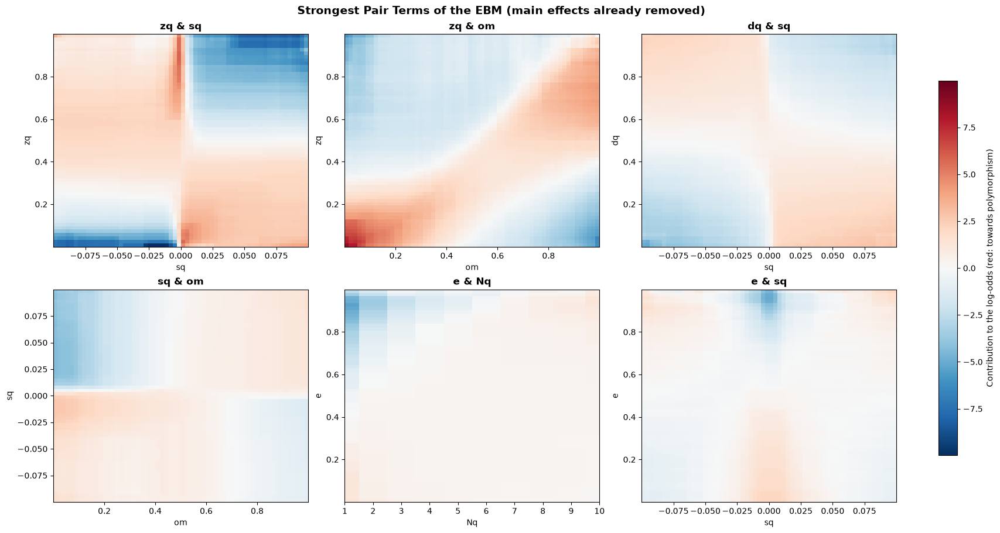

In [68]:
### --- Strongest Pair Terms of the EBM as Heat Maps --- ###
pair_terms = [n for n in term_importance.sort_values(ascending = False).index if ' & ' in n][:6]
fig, axes = plt.subplots(2, 3, figsize = (17, 9), layout = 'constrained')
limit = max(np.abs(np.asarray(ebm_global.data(term_names.index(n))['scores'], dtype = float)).max() for n in pair_terms)
for ax, name in zip(axes.ravel(), pair_terms):
    d = ebm_global.data(term_names.index(name))
    f_left, f_right = name.split(' & ')                # Rows follow the first feature, columns the second.
    im = ax.pcolormesh(np.asarray(d['right_names'], dtype = float), np.asarray(d['left_names'], dtype = float),
                       np.asarray(d['scores'], dtype = float), cmap = 'RdBu_r', vmin = -limit, vmax = limit, shading = 'flat')
    ax.set_xlabel(f_right); ax.set_ylabel(f_left)
    ax.set_title(name, fontweight = 'bold')
for ax in axes.ravel()[len(pair_terms):]:
    ax.set_visible(False)
fig.colorbar(im, ax = axes, shrink = 0.8, label = 'Contribution to the log-odds (red: towards polymorphism)')
fig.suptitle('Strongest Pair Terms of the EBM (main effects already removed)', fontsize = 14, fontweight = 'bold')
plt.show()

> **Takeaway.** The EBM is a readable model that does much better than any student, but it **does not fully match XGBoost** here: its test PR AUC is 0.908 against 0.958 (paired difference -0.050, 95% interval -0.053 to -0.047) and its test ROC AUC 0.971 against 0.987 (difference -0.016), while its fidelity to XGBoost on the synthetic hold-out is R^2 = 0.905 with 95.3% agreement of the 0/1 decisions. Its probabilities are also less sharp (Brier score 0.055 against 0.038, log loss 0.183 against 0.128). The search selected the largest number of pairs offered (20) and the search PR AUC was still rising, but more slowly each time (0.671, 0.841, 0.879 and 0.889 for 0, 5, 10 and 20 pairs), so a model with more pairs would probably close only part of the gap; the rest comes from interactions that involve three or more parameters (Section 14.10). The jump from 0 to 5 pairs shows how much of the signal is interaction: the additive model (0 pairs) does clearly better than a random classifier (search PR AUC 0.671, ROC AUC 0.863) but is far below the models with pairs. The EBM ranks its main effects as `e`, `zq`, `sq`, `om`, `s`, `Nq`, `dq` (SHAP: `zq`, `sq`, `e`, `om`, `dq`, `s`, `Nq`), i.e. the same four parameters first, in a different order because the EBM books part of the effect of `zq`, `sq` and `dq` in its pair terms. Among all the terms, three pairs come before any main effect: `zq` x `sq` (importance 2.3), `zq` x `om` (1.9) and `dq` x `sq` (1.3), followed by `e` (1.15), `zq` (1.05) and `sq` x `om` (1.05). These are the interactions to look at in Section 14.10.
>
> **Limits.** The EBM, like every model here, describes the simulator only inside the explored ranges, and a term shown as a heat map is as good as the data in its cells (see the bands of the shape functions and the sparse coverage of Section 6.3). The pair terms are the *model's* decomposition; Section 14.10 checks them against a second, independent screen and against the raw data.

### **14.10 Which Parameters Interact? A Screen Without SHAP Interaction Values**

Section 14.5 looked at the three pairs formed by the three most important parameters. That choice is arbitrary: the parameters that interact most are not necessarily the ones that matter most on their own. A screen over *all* 55 pairs needs a tool that does not rely on Shapley credit, so we use **constrained boosting**, which only needs the data:

1. **Additive ceiling.** Boosted trees of depth 1 (stumps) cannot represent any interaction, so they are an additive model. Their cross-validated score is the ceiling of what the eleven parameters can do *without* interacting.
2. **One pair at a time.** A boosted model of depth 2 in which **only one chosen pair of features may appear together in a branch** (`interaction_constraints`), all the other features being kept additive. The improvement in cross-validated log loss over the additive ceiling is the strength of that pair. This is repeated for the 55 pairs. To fit the compute budget, the screen runs on a stratified subsample of 40,000 training rows with 3 folds: it only has to **rank** the pairs.
3. **Cumulative curve.** The best pairs are added one after the other to see how many are needed to close the gap between the additive model and the full model (depth 6).

Gains of different pairs are **not additive** (two pairs can share the same information), so they are used only to rank the pairs. The EBM pairs of Section 14.9 give a second ranking, obtained with a different model family.

                    CV log loss  CV PR AUC
Additive (depth 1)       0.3656     0.6700
Any pair (depth 2)       0.2188     0.8734
Full (depth 6)           0.1664     0.9253
Letting every pair interact closes 74% of the gap between the additive and the full model; the rest needs three or more parameters at once.



,f1,f2,log loss gain,PR AUC gain,share of additive-to-full gap,EBM importance
0,zq,om,0.038,0.041,0.191,1.886
1,dq,sq,0.031,0.044,0.157,1.322
2,zq,sq,0.019,0.039,0.097,2.344
3,s,e,0.006,0.011,0.030,0.443
4,e,Nq,0.004,0.007,0.022,0.544
5,e,sq,0.004,0.005,0.020,0.494
6,sq,om,0.004,0.014,0.019,1.051
7,dw,sq,0.003,0.003,0.014,0.358
8,zq,Nq,0.003,0.003,0.013,0.389
9,om,Nq,0.001,0.002,0.006,0.212


Spearman correlation between the screen and the EBM importances over the 55 pairs: 0.83
4 of the 5 strongest pairs of the screen are also among the 5 strongest pairs of the EBM.
The strongest single pair closes 19% of the gap between the additive and the full model.


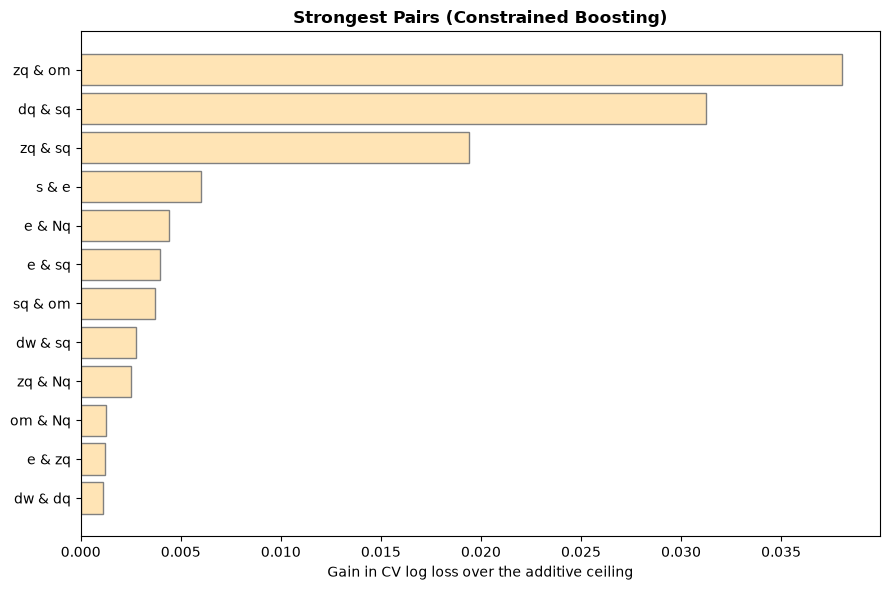

In [69]:
### --- Interaction Screen: Additive Ceiling and One Pair at a Time (Constrained Boosting) --- ###
# Compute budget: the screen fits one boosted model per pair and per fold, so it runs on a stratified subsample of the
# training set with 3 folds. Its output is a RANKING of the pairs, which does not need the precision of the full data.
SCREEN_ROWS, SCREEN_FOLDS = BUDGET['screen_rows'], BUDGET['screen_folds']
X_scr, _, y_scr, _ = train_test_split(X_train, y_train, train_size = SCREEN_ROWS, stratify = y_train, random_state = random_seed)
SCREEN_CV = StratifiedKFold(n_splits = SCREEN_FOLDS, shuffle = True, random_state = random_seed)

def cv_boosting(constraints, depth):
    """Mean CV log loss and PR AUC of a small boosted model on the screening subsample.

    `constraints` lists the groups of features allowed to appear together in a branch (None = no restriction).
    Every model is trained until an inner hold-out (15% of its training fold) stops improving, so that no model is
    penalised by too few trees: stumps and depth-2 trees need many more rounds than deep trees.
    """
    losses, prs = [], []
    for tr, va in SCREEN_CV.split(X_scr, y_scr):
        X_fit, X_stop, y_fit, y_stop = train_test_split(X_scr.iloc[tr], y_scr.iloc[tr], test_size = 0.15,
                                                        stratify = y_scr.iloc[tr], random_state = random_seed)
        m = XGBClassifier(n_estimators = 4000, max_depth = depth, learning_rate = 0.1, subsample = 0.7,
                          min_child_weight = 1, reg_lambda = 5, interaction_constraints = constraints,
                          early_stopping_rounds = 50, random_state = random_seed, eval_metric = 'logloss', n_jobs = -1)
        m.fit(X_fit, y_fit, eval_set = [(X_stop, y_stop)], verbose = False)
        p = m.predict_proba(X_scr.iloc[va])[:, 1]
        losses.append(log_loss(y_scr.iloc[va], p)); prs.append(average_precision_score(y_scr.iloc[va], p))
    return np.mean(losses), np.mean(prs)


additive_ll, additive_pr = cv_boosting(None, depth = 1)       # Stumps: no interaction is possible.
full_ll, full_pr = cv_boosting(None, depth = 6)               # Everything may interact.
pairwise_ll, pairwise_pr = cv_boosting(None, depth = 2)       # Any pair may interact, nothing higher.
gap = additive_ll - full_ll
print(pd.DataFrame({'CV log loss': [additive_ll, pairwise_ll, full_ll], 'CV PR AUC': [additive_pr, pairwise_pr, full_pr]},
                   index = ['Additive (depth 1)', 'Any pair (depth 2)', 'Full (depth 6)']).round(4).to_string())
print(f'Letting every pair interact closes {(additive_ll - pairwise_ll) / gap:.0%} of the gap between the additive and the full model; '
      f'the rest needs three or more parameters at once.\n')

rows = []
for f1, f2 in itertools.combinations(feature_cols, 2):
    groups = [[f] for f in feature_cols if f not in (f1, f2)] + [[f1, f2]]
    ll, pr = cv_boosting(groups, depth = 2)
    rows.append({'f1': f1, 'f2': f2, 'log loss gain': additive_ll - ll, 'PR AUC gain': pr - additive_pr})
pair_table = pd.DataFrame(rows).sort_values('log loss gain', ascending = False).reset_index(drop = True)
pair_table['share of additive-to-full gap'] = pair_table['log loss gain'] / gap
ebm_pair_importance = {frozenset(n.split(' & ')): v for n, v in zip(best_ebm_model.term_names_, best_ebm_model.term_importances()) if ' & ' in n}
pair_table['EBM importance'] = [ebm_pair_importance.get(frozenset((a, b)), 0.0) for a, b in zip(pair_table['f1'], pair_table['f2'])]
display(pair_table.head(12).round(3))

# Second, independent ranking: the EBM importance of every pair (0 if the EBM did not select it).
rho = stats.spearmanr(pair_table['log loss gain'], pair_table['EBM importance']).correlation
top5_screen = set(zip(pair_table['f1'].head(5), pair_table['f2'].head(5)))
ebm_top = pair_table.sort_values('EBM importance', ascending = False).head(5)
top5_ebm = set(zip(ebm_top['f1'], ebm_top['f2']))
print(f'Spearman correlation between the screen and the EBM importances over the {len(pair_table)} pairs: {rho:.2f}')
print(f'{len(top5_screen & top5_ebm)} of the 5 strongest pairs of the screen are also among the 5 strongest pairs of the EBM.')
print(f'The strongest single pair closes {pair_table["share of additive-to-full gap"].iloc[0]:.0%} of the gap between the additive and the full model.')

top = pair_table.head(12).iloc[::-1]
plt.figure(figsize = (9, 6))
plt.barh([f'{a} & {b}' for a, b in zip(top['f1'], top['f2'])], top['log loss gain'], color = 'moccasin', edgecolor = 'gray')
plt.xlabel('Gain in CV log loss over the additive ceiling')
plt.title('Strongest Pairs (Constrained Boosting)', fontweight = 'bold')
plt.tight_layout()
plt.show()

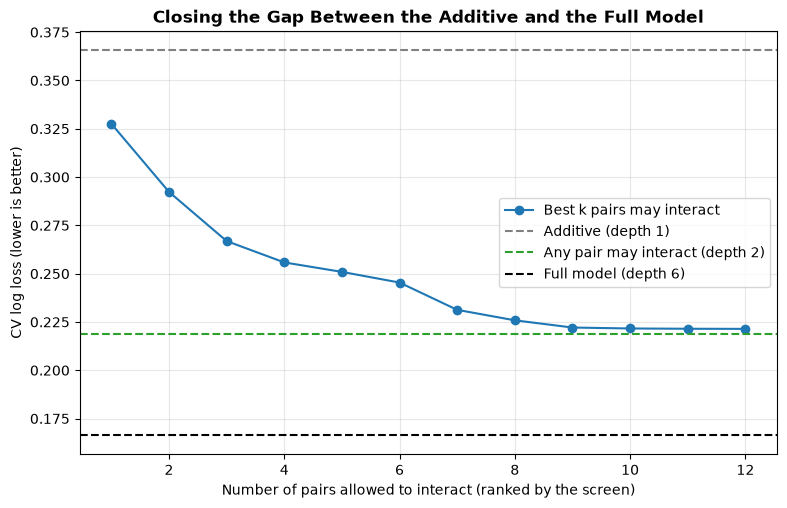

Share of the additive-to-full gap closed: all pairs 74%, best 5 pairs 58%, best 10 pairs 72%.


In [70]:
### --- How Many Pairs Are Needed? Cumulative Curve --- ###
ranked_pairs = list(zip(pair_table['f1'], pair_table['f2']))
curve = []
for k in range(1, BUDGET['n_curve_pairs'] + 1):
    chosen = ranked_pairs[:k]
    used = {f for pair in chosen for f in pair}
    groups = [list(pair) for pair in chosen] + [[f] for f in feature_cols if f not in used]
    curve.append(cv_boosting(groups, depth = 2)[0])

plt.figure(figsize = (9, 5.5))
plt.plot(range(1, len(curve) + 1), curve, marker = 'o', color = 'tab:blue', label = 'Best k pairs may interact')
plt.axhline(additive_ll, color = 'gray', linestyle = '--', label = 'Additive (depth 1)')
plt.axhline(pairwise_ll, color = 'tab:green', linestyle = '--', label = 'Any pair may interact (depth 2)')
plt.axhline(full_ll, color = 'black', linestyle = '--', label = 'Full model (depth 6)')
plt.xlabel('Number of pairs allowed to interact (ranked by the screen)')
plt.ylabel('CV log loss (lower is better)')
plt.title('Closing the Gap Between the Additive and the Full Model', fontweight = 'bold')
plt.legend()
plt.grid(alpha = 0.3)
plt.show()
closed = ', '.join(f'best {k} pairs {(additive_ll - curve[k - 1]) / gap:.0%}' for k in (5, 10) if k <= len(curve))
print(f'Share of the additive-to-full gap closed: all pairs {(additive_ll - pairwise_ll) / gap:.0%}, {closed}.')

The two strongest pairs of the screen, **`zq` x `om`** (the current phenotype against the male optimum) and **`dq` x `sq`** (dominance in queens against the size and sign of the allelic effect), were not among the pairs examined in Section 14.5 (the third strongest, `zq` x `sq`, was). The second is exactly what the dominance hypothesis of Section 14.6 is about, the first is what Section 14.11 is about, so they deserve the same check against the raw data: the observed polymorphism rate in bins (no model) on the left, the partial dependence of XGBoost in the middle, and the agreement between the two on the right. In both cases the model reproduces the data (r = 1.00, about 4,200 parameter sets per cell): `zq` x `om` shows a diagonal band on the `om` > `zq` side, and for `dq` x `sq` the rate rises with `dq` when `sq` is negative and falls with `dq` when `sq` is positive. The model is a little below the data in the cells with the highest rates (`dq` x `sq`).


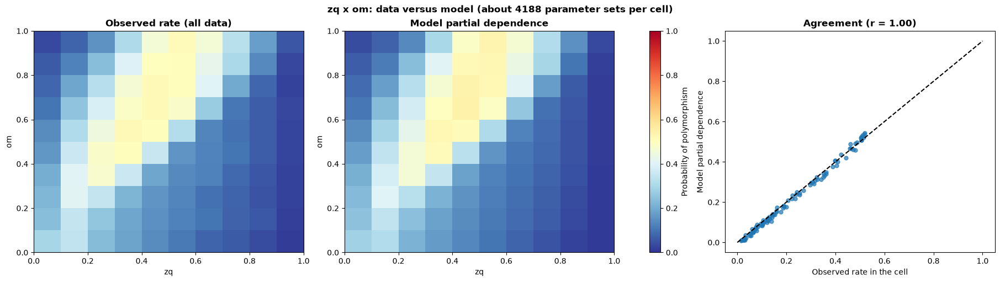

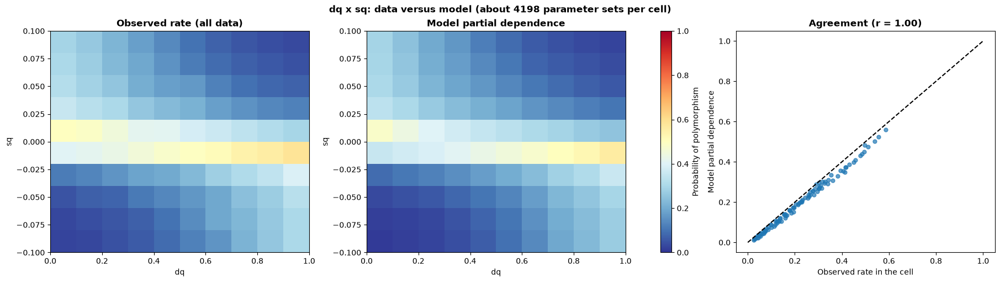

In [71]:
### --- Observed Rate Versus Model Partial Dependence for the Strongest New Pairs --- ###
already_checked = {frozenset(p) for p in itertools.combinations(top3, 2)}          # The pairs of Section 14.5.
new_pairs = [(a, b) for a, b in zip(pair_table['f1'], pair_table['f2']) if frozenset((a, b)) not in already_checked][:2]

for f1, f2 in new_pairs:
    g1, g2 = bin_centers(f1, n_bins_pair), bin_centers(f2, n_bins_pair)
    emp, counts = empirical_rate_grid(df_model, f1, f2, n_bins_pair)
    pdp = pdp_2d(best_xgb, background_pairs, f1, f2, g1, g2)

    fig, axes = plt.subplots(1, 3, figsize = (18, 5), layout = 'constrained')
    extent = [*axis_extent(f1, n_bins_pair), *axis_extent(f2, n_bins_pair)]
    for ax, arr, title in [(axes[0], emp, 'Observed rate (all data)'), (axes[1], pdp, 'Model partial dependence')]:
        im = ax.imshow(arr, origin = 'lower', extent = extent, aspect = 'auto', vmin = 0, vmax = 1, cmap = 'RdYlBu_r')
        ax.set_xlabel(f1); ax.set_ylabel(f2); ax.set_title(title, fontweight = 'bold')
    fig.colorbar(im, ax = axes[:2], label = 'Probability of polymorphism')

    ok = ~np.isnan(emp)
    axes[2].scatter(emp[ok], pdp[ok], s = 25, alpha = 0.7)
    axes[2].plot([0, 1], [0, 1], 'k--')
    axes[2].set_xlabel('Observed rate in the cell'); axes[2].set_ylabel('Model partial dependence')
    axes[2].set_title(f'Agreement (r = {np.corrcoef(emp[ok], pdp[ok])[0, 1]:.2f})', fontweight = 'bold')
    fig.suptitle(f'{f1} x {f2}: data versus model (about {int(np.median(counts[counts > 0]))} parameter sets per cell)', fontweight = 'bold')
    plt.show()

> **Takeaway.** Two routes that share nothing but the data, constrained boosting and the pairs chosen by the EBM, rank the pairs in a consistent way (Spearman correlation 0.83 over the 55 pairs; 4 of the 5 strongest pairs are common), which is more convincing than either alone. The interaction content is **concentrated in a few pairs**: `zq` x `om` closes 19% of the gap between the additive and the full model, `dq` x `sq` 16% and `zq` x `sq` 10%, and no other pair closes more than 3% (`s` x `e` 3.0%, `e` x `Nq` 2.2%, `e` x `sq` 2.0%, `sq` x `om` 1.9%). The EBM puts the same three pairs first, in a slightly different order (importance 2.3 for `zq` x `sq`, 1.9 for `zq` x `om`, 1.3 for `dq` x `sq`, against 1.05 or less for the other pairs). Letting every pair interact closes 74% of the gap (log loss 0.366 for the additive model, 0.219 when any pair may interact, 0.166 for the full model) and the best five pairs 58%; about nine pairs are needed to reach the level of "any pair", and the remaining 26% involves three or more parameters at once (for instance `dq`, `dw` and `sq` together, Section 14.6). The `zq` x `om` and `dq` x `sq` pairs are visible in the maps: a **diagonal band** on the `om` > `zq` side for the first, and a dominance effect that changes sign with `sq` for the second. The diagonal band is one structural reason why a small tree could not summarise XGBoost in Section 14.7. The pair `zq` x `om` is the signature of selection in males (Section 14.11).


### **14.11 What Is New: Does Selection in Males Change the Picture?**

In the three-way model, males carry the allele in a single copy (no dominance) and are selected towards their own optimum `om`. In the data set, the male phenotype and the allelic effect are tied to the others (`zm = zq`, `sm = sq`), so **`om` is the only parameter that is specific to male selection**. Its role is therefore read through three questions, with the same logic as for dominance in Section 14.6: first on the raw data, then with the model.

**The expectation.** With the small-effect reading of Section 2.1, the allele is favoured in males when `sq x (om - zq) > 0`. Let `E = om - zq` be the distance from the current phenotype to the male optimum. Then:

| Sign of `sq` | Males favour the allele when | Seen along `E = om - zq` |
|---|---|---|
| **Positive** | `E > 0` (the optimum is above the current phenotype) | rate expected to **rise** with `E` if male selection matters |
| **Negative** | `E < 0` (the optimum is below the current phenotype) | rate expected to **fall** with `E`: the **mirror image** |

A mirror-image pattern for the two signs is the signature of male selection, because it cannot come from anything that depends on `E` alone. Whether polymorphism needs the males to favour the allele (to compensate the other groups) or to oppose it (to add antagonism) is **not** assumed: it is what the data say.

**Step 1. Directly on the data.** The parameters were drawn independently, so comparing rates between the two directions of male selection, within a sign of `sq`, is not confounded with any other parameter.

In [72]:
### --- Observed Polymorphism Rates by Sign of sq and Direction of Male Selection (all data) --- ###
male = df_model.assign(
    E = df_model['om'] - df_model['zq'],
    sq_sign = np.where(df_model['sq'] < 0, 'sq < 0', 'sq > 0'))
male['males'] = np.where(male['sq'] * male['E'] > 0, 'favour the allele', 'oppose the allele')

rng_male = np.random.default_rng(random_seed)
male_rows = []
for sign in ['sq < 0', 'sq > 0']:
    rates = {}
    for sel in ['favour the allele', 'oppose the allele']:
        subset = male[(male['sq_sign'] == sign) & (male['males'] == sel)][target_col]
        k, n = int(subset.sum()), len(subset)
        low, high = wilson_ci(k, n)
        rates[sel] = (n, k / n)
        male_rows.append({'sq': sign, 'males': sel, 'n': n, 'observed rate': k / n, '95% CI low': low, '95% CI high': high})
    (n_f, p_f), (n_o, p_o) = rates['favour the allele'], rates['oppose the allele']
    draws = rng_male.binomial(n_f, p_f, 5000) / n_f - rng_male.binomial(n_o, p_o, 5000) / n_o
    d_low, d_high = np.percentile(draws, [2.5, 97.5])
    print(f'{sign}: rate(males favour) - rate(males oppose) = {p_f - p_o:+.4f}  [95% CI {d_low:+.4f}, {d_high:+.4f}]  '
          f'(ratio {p_f / p_o:.2f})')
display(pd.DataFrame(male_rows).set_index(['sq', 'males']).round(4))

sq < 0: rate(males favour) - rate(males oppose) = -0.1108  [95% CI -0.1145, -0.1073]  (ratio 0.61)
sq > 0: rate(males favour) - rate(males oppose) = +0.3291  [95% CI +0.3259, +0.3323]  (ratio 7.12)


n  observed rate  95% CI low  95% CI high
sq     males                                                            
sq < 0 favour the allele  104935         0.1760      0.1737       0.1783
       oppose the allele  104825         0.2869      0.2841       0.2896
sq > 0 favour the allele  104885         0.3828      0.3799       0.3858
       oppose the allele  104875         0.0537      0.0524       0.0551

**Step 1b. The whole picture along `E = om - zq`.** The same observed rates, along `E` (bins of width 0.2) instead of its sign, for each sign of `sq`, with 95% Wilson intervals. A mirror image between the two curves means that the direction of male selection matters; a flat curve means that `om` does nothing on its own.

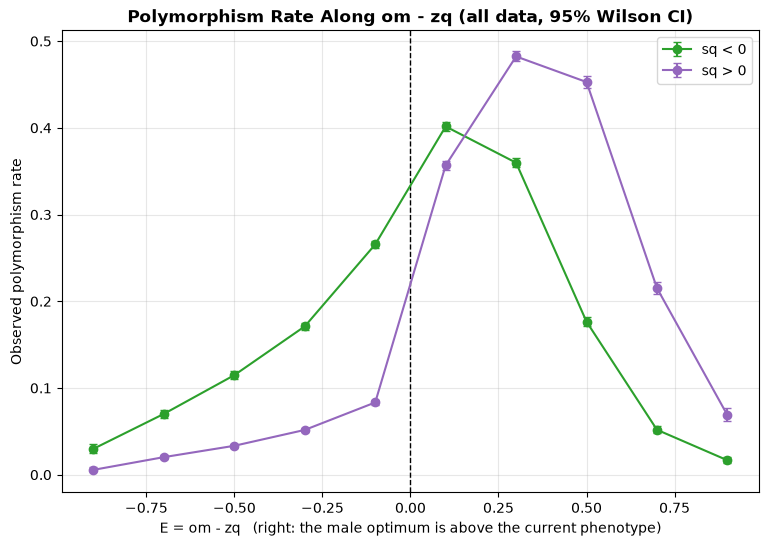

In [73]:
### --- Observed Polymorphism Rate Along E = om - zq, by Sign of sq --- ###
male['E_bin'] = pd.cut(male['E'], np.linspace(-1, 1, 11), include_lowest = True)

fig, ax = plt.subplots(figsize = (9, 6))
for sign, color in [('sq < 0', 'tab:green'), ('sq > 0', 'tab:purple')]:
    g = male[male['sq_sign'] == sign].groupby('E_bin', observed = True)[target_col].agg(['sum', 'count'])
    centers = np.array([iv.mid for iv in g.index])
    rate = (g['sum'] / g['count']).to_numpy()
    ci = np.array([wilson_ci(k, n) for k, n in zip(g['sum'], g['count'])])
    ax.errorbar(centers, rate, yerr = [rate - ci[:, 0], ci[:, 1] - rate], marker = 'o', capsize = 3, color = color, label = sign)
ax.axvline(0, color = 'black', linestyle = '--', linewidth = 1)
ax.set_xlabel('E = om - zq   (right: the male optimum is above the current phenotype)')
ax.set_ylabel('Observed polymorphism rate')
ax.set_title('Polymorphism Rate Along om - zq (all data, 95% Wilson CI)', fontweight = 'bold')
ax.legend()
ax.grid(alpha = 0.3)
plt.show()


**Step 2. Maps in the (`om`, `zq`) plane.** As for dominance in Section 14.6: top row, observed rates in 8 x 8 bins (all data); bottom row, the model's partial dependence on the same grid, for each sign of `sq`; right column, positive minus negative `sq`. The dashed diagonal `om = zq` is the line where males feel no directional push (`E = 0`).

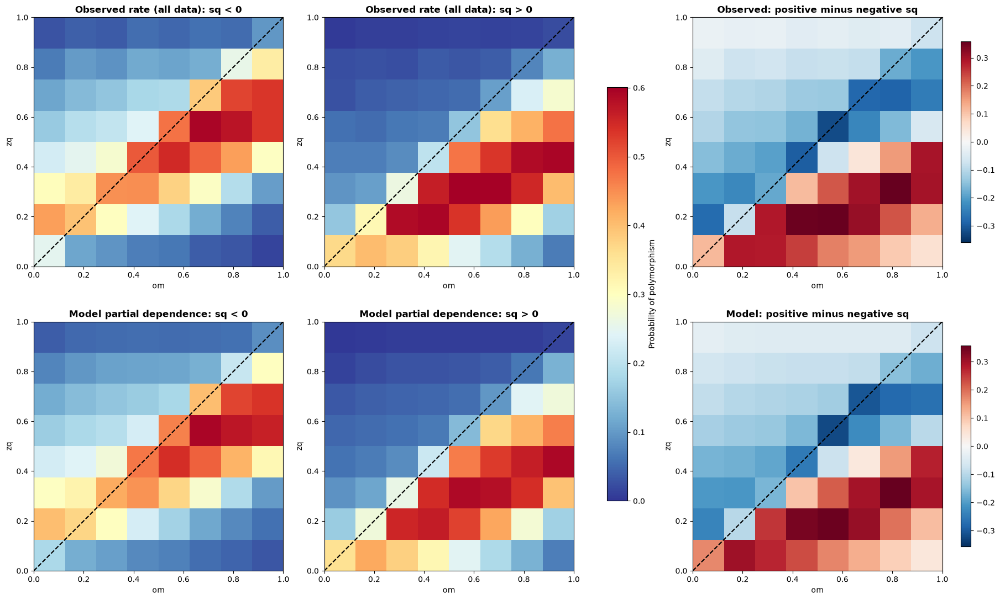

sq < 0: correlation between observed and model cells = 1.00, median parameter sets per cell = 3281
sq > 0: correlation between observed and model cells = 1.00, median parameter sets per cell = 3274


In [74]:
### --- Observed and Model-Based Maps in the (om, zq) Plane, for Each Sign of sq --- ###
def plot_sign_maps(f1, f2, n_bins = 8, diagonal = True):
    """Observed rates (top) and model partial dependence (bottom) in the (f1, f2) plane for sq < 0 and sq > 0, and their difference."""
    grid = bin_centers(f1, n_bins)
    maps_ = {}
    for sign, train_mask, all_mask in [('sq < 0', X_train['sq'] < 0, df_model['sq'] < 0), ('sq > 0', X_train['sq'] > 0, df_model['sq'] > 0)]:
        emp, counts = empirical_rate_grid(df_model[all_mask], f1, f2, n_bins)
        background = X_train[train_mask].sample(n = 300, random_state = random_seed)
        maps_[sign] = (emp, counts, pdp_2d(best_xgb, background, f1, f2, grid, bin_centers(f2, n_bins)))
    vmax = max(np.nanmax(m[0]) for m in maps_.values())
    fig, axes = plt.subplots(2, 3, figsize = (18, 11), layout = 'constrained')
    for col, sign in enumerate(['sq < 0', 'sq > 0']):
        emp, counts, pdp = maps_[sign]
        for row, (arr, name) in enumerate([(emp, 'Observed rate (all data)'), (pdp, 'Model partial dependence')]):
            ax = axes[row, col]
            im = ax.imshow(arr, origin = 'lower', extent = [0, 1, 0, 1], aspect = 'equal', vmin = 0, vmax = vmax, cmap = 'RdYlBu_r')
            if diagonal:
                ax.plot([0, 1], [0, 1], 'k--')
            ax.set_title(f'{name}: {sign}', fontweight = 'bold')
            ax.set_xlabel(f1); ax.set_ylabel(f2)
    fig.colorbar(im, ax = axes[:, :2], shrink = 0.7, label = 'Probability of polymorphism')
    for row, idx, name in [(0, 0, 'Observed'), (1, 2, 'Model')]:
        difference = maps_['sq > 0'][idx] - maps_['sq < 0'][idx]
        limit = np.nanmax(np.abs(difference))
        ax = axes[row, 2]
        im2 = ax.imshow(difference, origin = 'lower', extent = [0, 1, 0, 1], aspect = 'equal', vmin = -limit, vmax = limit, cmap = 'RdBu_r')
        if diagonal:
            ax.plot([0, 1], [0, 1], 'k--')
        ax.set_title(f'{name}: positive minus negative sq', fontweight = 'bold')
        ax.set_xlabel(f1); ax.set_ylabel(f2)
        fig.colorbar(im2, ax = ax, shrink = 0.7)
    plt.show()
    for sign in ['sq < 0', 'sq > 0']:
        emp, counts, pdp = maps_[sign]
        ok = ~np.isnan(emp)
        print(f'{sign}: correlation between observed and model cells = {np.corrcoef(emp[ok], pdp[ok])[0, 1]:.2f}, '
              f'median parameter sets per cell = {int(np.median(counts[counts > 0]))}')

plot_sign_maps('om', 'zq')

**Step 3. SHAP dependence of `om`.** The dependence plot below is the one used for `dq` coloured by `sq` earlier: each dot is a test parameter set, the vertical axis is the push of `om` on the log-odds of polymorphism, and the colour is `sq`. If male selection acts through the sign of `sq`, the two colours should follow **opposite** trends along `om`.

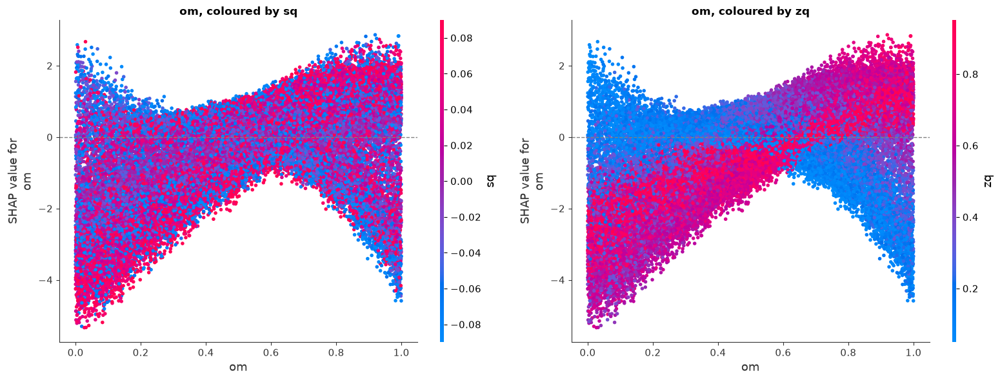

In [75]:
### --- SHAP Dependence of om, Coloured by sq --- ###
fig, axes = plt.subplots(1, 2, figsize = (16, 6))
shap.dependence_plot('om', shap_vals, X_explain, interaction_index = 'sq', ax = axes[0], show = False)
axes[0].axhline(0, color = 'gray', linestyle = '--', linewidth = 1)
axes[0].set_title('om, coloured by sq', fontweight = 'bold')
shap.dependence_plot('om', shap_vals, X_explain, interaction_index = 'zq', ax = axes[1], show = False)
axes[1].axhline(0, color = 'gray', linestyle = '--', linewidth = 1)
axes[1].set_title('om, coloured by zq', fontweight = 'bold')
plt.tight_layout()
plt.show()

**How much does each parameter bring? Drop-one refits.** Permutation importance (Section 14.2) says how much the fitted model uses a feature. A complementary, model-free-of-that-fit question is: *how much predictive information is lost if the feature is not available at all?* The cell refits XGBoost, with the configuration selected in Section 11, without one feature at a time, and reports the **test** PR AUC and ROC AUC. A parameter whose removal changes nothing is either irrelevant or **redundant** with the others; this separates `om` from the parameters that have been known to matter since the first model.

,test PR AUC,test ROC AUC,PR AUC lost
feature removed,,,
sq,0.6494,0.8715,0.3082
zq,0.6659,0.8647,0.2917
e,0.7969,0.9429,0.1607
om,0.8013,0.9297,0.1563
dq,0.8823,0.9624,0.0753
Nq,0.9247,0.9772,0.0329
s,0.9280,0.9760,0.0296
dw,0.9519,0.9848,0.0057
(none),0.9576,0.9868,0.0000


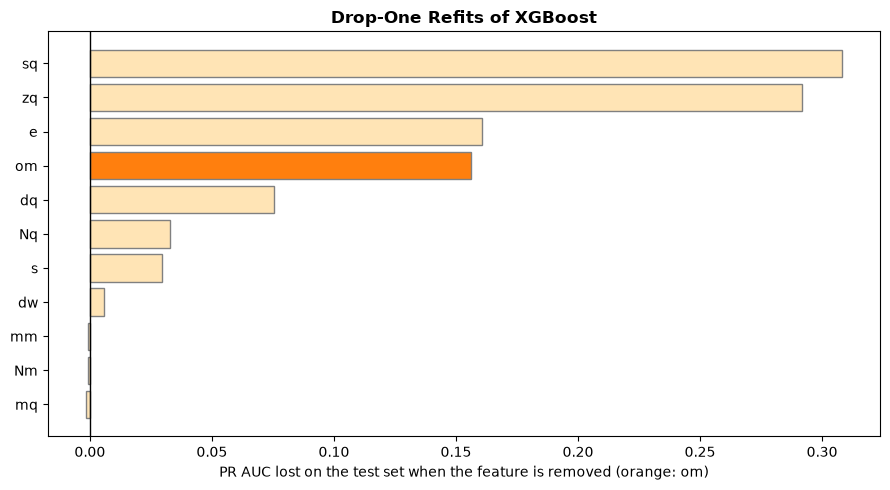

In [76]:
### --- Drop-One Refits: Test Performance of XGBoost Without Each Feature --- ###
p_full = best_xgb.predict_proba(X_test)[:, 1]
ablation_rows = [{'feature removed': '(none)', 'test PR AUC': average_precision_score(y_test, p_full), 'test ROC AUC': roc_auc_score(y_test, p_full)}]
for f in feature_cols:
    cols = [c for c in feature_cols if c != f]
    m = clone(best_xgb).set_params(n_jobs = -1).fit(X_train[cols], y_train)
    p = m.predict_proba(X_test[cols])[:, 1]
    ablation_rows.append({'feature removed': f, 'test PR AUC': average_precision_score(y_test, p), 'test ROC AUC': roc_auc_score(y_test, p)})
ablation = pd.DataFrame(ablation_rows).set_index('feature removed')
ablation['PR AUC lost'] = ablation.loc['(none)', 'test PR AUC'] - ablation['test PR AUC']
display(ablation.sort_values('PR AUC lost', ascending = False).round(4))

order_a = ablation.drop(index = '(none)').sort_values('PR AUC lost')
plt.figure(figsize = (9, 5))
plt.barh(order_a.index, order_a['PR AUC lost'], color = ['tab:orange' if f == 'om' else 'moccasin' for f in order_a.index], edgecolor = 'gray')
plt.axvline(0, color = 'black', linewidth = 1)
plt.xlabel('PR AUC lost on the test set when the feature is removed (orange: om)')
plt.title('Drop-One Refits of XGBoost', fontweight = 'bold')
plt.tight_layout()
plt.show()

> **Takeaway (males).** The expectation of Section 14.11 (a mirror image between the signs of `sq`) is only **half supported**, and what the data show is more specific.
>
> 1. **Step 1: the two signs are not mirror images.** For positive `sq`, polymorphism is 7.1 times more frequent when the males favour the allele (`E` > 0) than when they oppose it (38.3% against 5.4%; difference +0.329, interval +0.326 to +0.332), as expected. For negative `sq` the sign is the opposite of the expected one: it is *less* frequent when the males favour the allele (`E` < 0: 17.6%) than when they oppose it (`E` > 0: 28.7%; difference -0.111, interval -0.115 to -0.107, ratio 0.61). In both cases the favourable side is `E` > 0, that is, a male optimum **above** the current phenotype.
> 2. **Step 1b: a window along `E`.** The rate is a bell-shaped function of `E` for both signs. For negative `sq` it peaks at about 40% for `E` around 0.1 and falls below 18% beyond `E` = 0.5; for positive `sq` it peaks at about 48% for `E` around 0.3, stays at about 45% up to `E` = 0.5 and drops to about 7% at `E` = 0.9. For `E` < 0 both curves are low (below 27% for negative `sq`, decreasing to 3% at `E` = -0.9; below 9% for positive `sq`). The sign of `sq` shifts the window, towards larger `E` for positive `sq`, but does not mirror it.
> 3. **Step 2: a diagonal band.** In the (`om`, `zq`) plane the polymorphism sits in a band just on the `om` > `zq` side of the line `om` = `zq`. The band lies at higher `zq` for negative `sq` and at lower `zq` for positive `sq`. The model reproduces these maps (correlation 1.00 for both signs, about 3,270 parameter sets per cell).
> 4. **Step 3: `om` acts together with `zq`, not with `sq`.** In the SHAP dependence plot of `om`, the colours of `sq` are mixed, whereas those of `zq` separate cleanly: for a high `om` the push is positive when `zq` is high and negative when `zq` is low. This is what a dependence on `om - zq` produces.
> 5. **`om` is a major parameter.** It ranks 4th by mean |SHAP| (1.16, after `zq` 2.59, `sq` 1.98 and `e` 1.62), 4th by permutation importance (0.26 of PR AUC, after `sq`, `zq` and `e`) and 4th by drop-one refit, where removing it costs 0.156 of PR AUC (the test ROC AUC falls from 0.987 to 0.930), as much as removing `e` (0.161) and more than removing `dq` (0.075), `Nq` (0.033), `s` (0.030) or `dw` (0.006). By contrast `mq`, `mm` and `Nm` bring nothing: the model without them is as good as the full one (PR AUC differences of -0.002 to -0.0006, i.e. very slightly higher without them).
> 6. **It acts together with `zq`**: `zq` x `om` is the strongest pair of the screen (19% of the additive-to-full gap, Section 14.10) and the second strongest pair term of the EBM.
>
> **What this does and does not say.** The window is a statement about the simulated data. In this model queens are selected towards low phenotypes, workers towards high phenotypes and males towards `om`; `E` > 0 therefore means that the male optimum lies on the worker side of the current phenotype, so male selection pushes in the same direction as worker selection and against queen selection, whichever the sign of `sq`. The data show that this is the configuration in which polymorphism is most frequent, but they do not say why. The remaining questions (is the window real when all the other parameters are fixed, what is the mechanism, is there a ceiling effect on the male phenotype) can be settled by a few targeted simulations (Section 15.3).


### **14.12 Comparison With the Previous Two-Caste Model**

The previous model had no males under selection and a single migration rate `m`; the three-way model adds `om` (and, through `sm` and `zm`, the same `sq` and `zq` apply to males) and splits `m` into `mq` and `mm`. The questions here are what changed in the **outcome** (how often is polymorphism maintained?) and in the **explanation** (which parameters matter, and does the dominance pattern survive?).

The previous data set, `ant_simple_model_dataset.csv`, is loaded from the same place as the current one (local file if present, otherwise GitHub). Two cautions: the two data sets were produced by different simulations, so a difference can come from the biology **or** from other choices of the simulations (for example the number of generations or the ranges); and the previous model is fitted below with a **fixed, reasonable configuration** (the one selected in the previous analysis), not re-tuned, since the aim is to compare explanations, not to maximise a score.

In [77]:
### --- The Previous Data Set: Size, Prevalence and Label Noise --- ###
old_file = 'ant_simple_model_dataset.csv'
if os.path.exists(old_file):
    print(f'Using local file {old_file}.')
    old_raw = pd.read_csv(old_file, index_col = 0)
else:
    print(f'Downloading {old_file} from GitHub...')
    old_raw = pd.read_csv(repo_url + old_file, index_col = 0)
old_raw = old_raw.reset_index(drop = True)

old_features = ['s', 'e', 'm', 'zq', 'dw', 'dq', 'sq', 'Nq', 'Nm']
assert np.allclose(old_raw['zq'], old_raw['zw']) and np.allclose(old_raw['sq'], old_raw['sw'])
old_model = old_raw[old_features + ['frac_polymorphic']].copy()
old_model[target_col] = (old_model['frac_polymorphic'] > POLYMORPH_THRESHOLD).astype(int)

def summarise(frame, label):
    """Size, prevalence and weight of the weak positives of a modelling table."""
    pos = frame.loc[frame[target_col] == 1, 'frac_polymorphic']
    return {'model': label, 'parameter sets': len(frame), 'features': len(frame.columns) - 2,
            'share polymorphic': frame[target_col].mean(),
            'share polymorphic (frac > 0.05)': (frame['frac_polymorphic'] > 0.05).mean(),
            'positives with frac <= 0.05': (pos <= 0.05).mean(), 'positives with frac >= 0.5': (pos >= 0.5).mean()}

display(pd.DataFrame([summarise(old_model, 'two-caste (previous)'), summarise(df_model, 'three-way (this notebook)')]).set_index('model').round(3))

,parameter sets,features,share polymorphic,share polymorphic (frac > 0.05),positives with frac <= 0.05,positives with frac >= 0.5
model,,,,,,
two-caste (previous),11882,9,0.281,0.136,0.517,0.056
three-way (this notebook),419520,11,0.225,0.121,0.460,0.076


,prevalence (random PR AUC),test PR AUC,PR AUC / prevalence,test ROC AUC
two-caste (previous),0.281,0.909,3.237,0.963
three-way (this notebook),0.225,0.958,4.259,0.987


,two-caste (previous),three-way (this notebook)
zq,0.255,0.268
sq,0.249,0.204
e,0.198,0.167
om,0.000,0.120
s,0.090,0.072
dq,0.083,0.074
Nq,0.054,0.051
dw,0.043,0.021
m,0.017,0.000
Nm,0.011,0.009


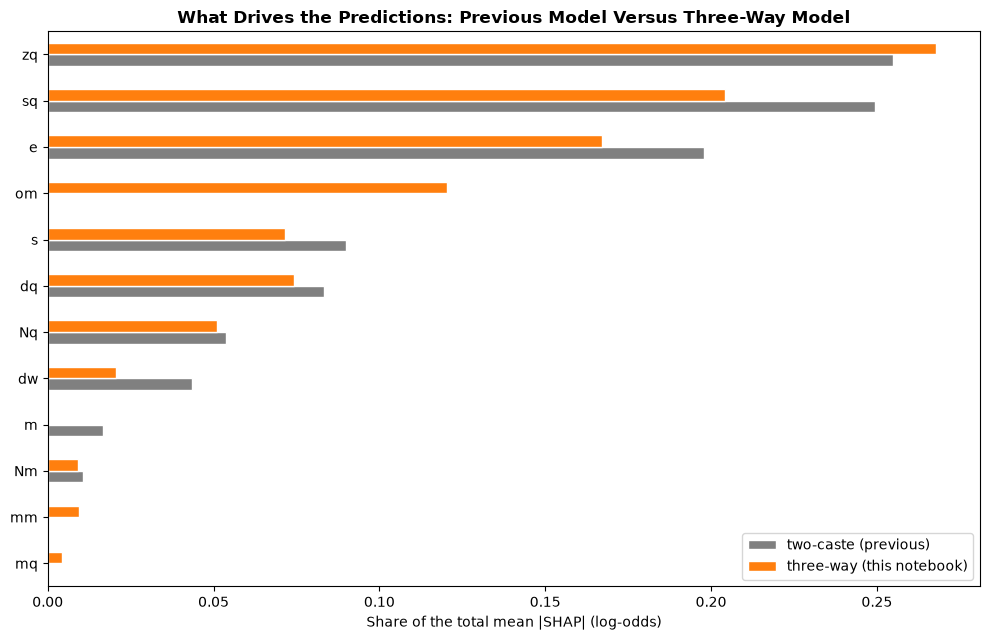

Features that exist in one model only: m (previous); mq, mm, om (three-way).


In [78]:
### --- Same Question, Both Models: XGBoost Performance and SHAP Importance Shares --- ###
# Previous model: fixed configuration (the one selected in the previous analysis), same split protocol and seed.
old_cfg = dict(n_estimators = 1000, max_depth = 6, learning_rate = 0.03, subsample = 0.6, colsample_bytree = 0.7,
               min_child_weight = 10, reg_alpha = 6, reg_lambda = 9)
Xo, yo = old_model[old_features].astype('float64'), old_model[target_col]
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(Xo, yo, test_size = 0.1, stratify = yo, random_state = random_seed)
old_xgb = XGBClassifier(random_state = random_seed, eval_metric = 'logloss', n_jobs = -1, **old_cfg).fit(Xo_tr, yo_tr)
p_old = old_xgb.predict_proba(Xo_te)[:, 1]

perf = pd.DataFrame({
    'prevalence (random PR AUC)': [yo_te.mean(), y_test.mean()],
    'test PR AUC': [average_precision_score(yo_te, p_old), average_precision_score(y_test, p_full)],
    'PR AUC / prevalence': [average_precision_score(yo_te, p_old) / yo_te.mean(), average_precision_score(y_test, p_full) / y_test.mean()],
    'test ROC AUC': [roc_auc_score(yo_te, p_old), roc_auc_score(y_test, p_full)],
}, index = ['two-caste (previous)', 'three-way (this notebook)'])
display(perf.round(3))

# SHAP importance as a share of the total, so that models with a different number of features and prevalence are comparable.
sv_old = np.asarray(shap.TreeExplainer(old_xgb)(Xo_te).values)
share_old = pd.Series(np.abs(sv_old).mean(axis = 0), index = old_features)
share_old = share_old / share_old.sum()
share_new = shap_importance.set_index('Feature')['Mean |SHAP| (log-odds)']
share_new = share_new / share_new.sum()
share_table = pd.DataFrame({'two-caste (previous)': share_old, 'three-way (this notebook)': share_new}).fillna(0.0)
share_table = share_table.loc[share_table.max(axis = 1).sort_values(ascending = False).index]
display(share_table.round(3))

share_table.iloc[::-1].plot(kind = 'barh', figsize = (10, 6.5), color = ['gray', 'tab:orange'], edgecolor = 'white')
plt.xlabel('Share of the total mean |SHAP| (log-odds)')
plt.title('What Drives the Predictions: Previous Model Versus Three-Way Model', fontweight = 'bold')
plt.tight_layout()
plt.show()
print('Features that exist in one model only: m (previous); mq, mm, om (three-way).')

In [79]:
### --- Does the Dominance Pattern of Section 14.6 Survive in the Three-Way Model? --- ###
def dominance_table(frame, label, seed = random_seed):
    """Observed rate when dq < dw and when dq > dw, for each sign of sq, with the difference, its bootstrap interval and the ratio."""
    rng_ = np.random.default_rng(seed)
    out = []
    for sign, mask in [('sq < 0', frame['sq'] < 0), ('sq > 0', frame['sq'] > 0)]:
        sub = frame[mask]
        lt, gt = sub[sub['dq'] < sub['dw']][target_col], sub[sub['dq'] > sub['dw']][target_col]
        p_lt, p_gt = lt.mean(), gt.mean()
        draws = rng_.binomial(len(lt), p_lt, 5000) / len(lt) - rng_.binomial(len(gt), p_gt, 5000) / len(gt)
        out.append({'model': label, 'sq': sign, 'rate dq<dw': p_lt, 'rate dq>dw': p_gt, 'difference': p_lt - p_gt,
                    'CI low': np.percentile(draws, 2.5), 'CI high': np.percentile(draws, 97.5), 'ratio dq<dw / dq>dw': p_lt / p_gt})
    return out

dom_compare = pd.DataFrame(dominance_table(old_model, 'two-caste (previous)') + dominance_table(df_model, 'three-way (this notebook)'))
display(dom_compare.set_index(['model', 'sq']).round(3))

### --- Is the Drop in Prevalence Explained by Male Selection? Rates in Subsets of the Three-Way Data --- ###
E_abs = (df_model['om'] - df_model['zq']).abs()
subsets = {'all rows': np.ones(len(df_model), dtype = bool), '|om - zq| < 0.1 (males almost neutral)': (E_abs < 0.1).to_numpy(),
           '|om - zq| > 0.5 (strong male selection)': (E_abs > 0.5).to_numpy()}
rows_sub = []
for label, mask in subsets.items():
    k, n = int(df_model.loc[mask, target_col].sum()), int(mask.sum())
    low, high = wilson_ci(k, n)
    rows_sub.append({'subset of the three-way data': label, 'n': n, 'share polymorphic': k / n, '95% CI low': low, '95% CI high': high})
rows_sub.append({'subset of the three-way data': '(previous model, all rows, for reference)', 'n': len(old_model),
                 'share polymorphic': old_model[target_col].mean(), '95% CI low': np.nan, '95% CI high': np.nan})
display(pd.DataFrame(rows_sub).set_index('subset of the three-way data').round(4))

rate dq<dw  rate dq>dw  difference  CI low  \
model                     sq                                                   
two-caste (previous)      sq < 0       0.287       0.430      -0.143  -0.166   
                          sq > 0       0.288       0.116       0.171   0.151   
three-way (this notebook) sq < 0       0.168       0.295      -0.128  -0.131   
                          sq > 0       0.278       0.158       0.120   0.117   

                                  CI high  ratio dq<dw / dq>dw  
model                     sq                                    
two-caste (previous)      sq < 0   -0.119                0.667  
                          sq > 0    0.191                2.474  
three-way (this notebook) sq < 0   -0.124                0.567  
                          sq > 0    0.124                1.760

,n,share polymorphic,95% CI low,95% CI high
subset of the three-way data,,,,
all rows,419520,0.2249,0.2236,0.2261
|om - zq| < 0.1 (males almost neutral),79290,0.2752,0.2721,0.2783
|om - zq| > 0.5 (strong male selection),105287,0.1073,0.1054,0.1092
"(previous model, all rows, for reference)",11882,0.2805,NaN,NaN


> **Takeaway.** The comparison must be read with the caution given at the start of the section: the two data sets come from different simulations, and the previous one is 35 times smaller (11,882 against 419,520 parameter sets).
>
> - **Outcome.** Polymorphism is a little less frequent in the three-way model (22.5% of the parameter sets against 28.1% with the definition `> 0`; 12.1% against 13.6% with `> 0.05`), and the share of weak positives (`frac_polymorphic` of 0.05 or less) is similar (46% against 52%). XGBoost predicts the three-way data better (test PR AUC 0.958 against 0.909, ROC AUC 0.987 against 0.963, lift over a random classifier 4.3 against 3.2), which cannot be attributed to the biology alone because the training set is also much larger.
> - **Explanation.** The same three parameters lead in both models, with similar shares of the mean |SHAP| (`zq` 25.5% then 26.8%, `sq` 24.9% then 20.4%, `e` 19.8% then 16.7%). `om` is new and takes the fourth place with 12.0% of the total; the shares of `sq`, `e`, `dw` and `s` fall (from 24.9% to 20.4%, 19.8% to 16.7%, 4.3% to 2.1% and 9.0% to 7.2%) while `zq` is stable. The migration rate `m` of the previous model (1.7%) is replaced by `mq` and `mm`, which together make only 1.3%, so migration matters little in both.
> - **Dominance.** The pattern survives: the differences between the two sides of `dq` = `dw` have the same sign as before (-0.143 and +0.171 in the previous model, -0.128 and +0.120 here). For negative `sq` the previous interval (-0.166 to -0.119) contains the new one (-0.131 to -0.124); for positive `sq` the effect is weaker here (rate ratio 1.76 against 2.47) and the intervals do not overlap (+0.151 to +0.191 against +0.117 to +0.124).
> - **Males.** Where male selection is almost neutral (|`om` - `zq`| < 0.1, 79,290 parameter sets), 27.5% of the parameter sets are polymorphic (interval 27.2% to 27.8%), close to the 28.1% of the previous model, whereas it is only 10.7% where male selection is strong (|`om` - `zq`| > 0.5). This is compatible with the lower prevalence of the three-way model coming from the males rather than from other differences between the two data sets, but it is a comparison across two simulations: the targeted simulation of Section 15.3 would settle it.


## **15. Conclusions, Limitations and Next Steps**

### **15.1 Summary of the Run**

The cell below collects the headline numbers of the run from the tables above, so that the text of the report can be written from numbers produced by the notebook.

In [80]:
### --- Summary of the Run --- ###
print(f'Parameter sets: {len(df_model):,} (train {len(X_train):,}, test {len(X_test):,}); share polymorphic: {df_model[target_col].mean():.2%}')
print(f'Random classifier: PR AUC = {prevalence_train:.3f}; always-negative accuracy = {majority_baseline:.3f}\n')
for n, r in RESULTS.items():
    m = r['metrics']
    print(f'{n:<22} validation PR AUC {m["pr_auc"]["val"]:.3f} (sd {m["pr_auc"]["val_sd"]:.3f}) | validation ROC AUC {m["roc_auc"]["val"]:.3f} | '
          f'test PR AUC {m["pr_auc"]["test"]:.3f} | test ROC AUC {m["roc_auc"]["test"]:.3f} | '
          f'test F1 {r["thr_test"]["F1"]:.3f} (precision {r["thr_test"]["precision"]:.3f}, recall {r["thr_test"]["recall"]:.3f})')
print(f'\nBest model on validation {METRIC_LABEL[PRIMARY_METRIC]}: {ref_name}')
print('Most important features (mean |SHAP|):', ', '.join(shap_importance["Feature"].head(4)))
print('Most important features (permutation, PR AUC):', ', '.join(perm_table["Feature"].head(4)))


Parameter sets: 419,520 (train 377,568, test 41,952); share polymorphic: 22.49%
Random classifier: PR AUC = 0.225; always-negative accuracy = 0.775

Logistic Regression    validation PR AUC 0.423 (sd 0.001) | validation ROC AUC 0.755 | test PR AUC 0.430 | test ROC AUC 0.757 | test F1 0.496 (precision 0.379, recall 0.715)
Decision Tree          validation PR AUC 0.841 (sd 0.003) | validation ROC AUC 0.946 | test PR AUC 0.840 | test ROC AUC 0.947 | test F1 0.773 (precision 0.738, recall 0.811)
Random Forest          validation PR AUC 0.930 (sd 0.001) | validation ROC AUC 0.977 | test PR AUC 0.932 | test ROC AUC 0.978 | test F1 0.847 (precision 0.826, recall 0.869)
XGBoost                validation PR AUC 0.958 (sd 0.001) | validation ROC AUC 0.987 | test PR AUC 0.958 | test ROC AUC 0.987 | test F1 0.886 (precision 0.876, recall 0.897)
Multilayer Perceptron  validation PR AUC 0.968 (sd 0.001) | validation ROC AUC 0.989 | test PR AUC 0.970 | test ROC AUC 0.990 | test F1 0.899 (precision 0.

### **15.2 Conclusions**

All numbers come from the tables and figures above (419,520 parameter sets, 22.49% polymorphic with the definition `frac_polymorphic > 0` and 18.5% with `> 0.01`, always-negative accuracy 0.775, PR AUC of a random classifier 0.225).

1. **How non-linear is the problem? Strongly.** The logistic regression reaches a test PR AUC of only 0.430 (ROC AUC 0.757), the tree 0.840, the forest 0.932, XGBoost 0.958 and the MLP 0.970. The signal is made of non-monotone effects (peaks in `zq` and `sq`) and of interactions: additive models reach a PR AUC of about 0.67 (additive EBM on the search subsample, depth-1 boosting in the interaction screen), against 0.93 for the full boosted model of the screen.
2. **Which model is the best?** The MLP (test PR AUC 0.970, ROC AUC 0.990, F1 0.899 at its out-of-fold threshold) is better than XGBoost (0.958, 0.987, F1 0.886): the paired difference is -0.012 with a 95% interval of -0.014 to -0.011. The EBM (0.908, F1 0.836) stays readable at a cost of 0.050 PR AUC relative to XGBoost. The probabilities are well calibrated for the MLP and XGBoost (Brier scores 0.032 and 0.038 against 0.174 for the constant prediction). Several models sit at the edge of their search range (tree and forest depth, forest size, XGBoost learning rate and rounds, MLP epochs; Table 1), and the search used 40,000 of the 377,568 training rows, so the ranking of the strongest models could move with a longer search. The learning curve is almost flat at the end (Section 13.8), so more simulations of the same kind would add little.
3. **Which parameters matter?** By mean |SHAP|: `zq` (2.59), `sq` (1.98), `e` (1.62), `om` (1.16), `dq` (0.72), `s` (0.69) and `Nq` (0.49). `dw`, `mm`, `Nm` and `mq` are close to irrelevant (0.04 to 0.20). Permutation importance and drop-one refits give the same top four (`sq`, `zq`, `e`, `om`), and removing `mq`, `mm` or `Nm` does not reduce the performance. The effect of `e` is monotone and negative, those of `s` and `Nq` positive, `zq` has a hump (best at intermediate values) and `sq` a sharp peak at 0.
4. **Interactions.** An additive boosted model reaches a CV log loss of 0.366 on the screening subsample against 0.166 for the full model; letting every pair interact closes 74% of the gap. Three pairs carry most of the pair structure: `zq` x `om` (19% of the additive-to-full gap), `dq` x `sq` (16%) and `zq` x `sq` (10%); no other pair closes more than 3%. The remaining 26% involves three or more parameters.
5. **Dominance.** For negative `sq`, polymorphism is 1.76 times more frequent when `dq` > `dw` (29.5% against 16.8%); for positive `sq`, it is 1.76 times more frequent when `dq` < `dw` (27.8% against 15.8%). The rate varies monotonically with `dq` - `dw`, in mirror-image directions for the two signs. This is the same direction as in the previous model and is consistent with dominance reversal, given that a positive `sq` favours workers and a negative `sq` favours queens (sign convention checked against the generator, Section 14.6).
6. **Males (new).** `om` is a major parameter (4th by every importance measure). Polymorphism is most frequent when the male optimum is moderately **above** the current phenotype (a band along `0 < om - zq < 0.5`, with peaks of about 40% for negative `sq` and 48% for positive `sq`), for both signs of `sq`: the mirror image expected from the small-effect reading is not supported. Where male selection is almost neutral, the prevalence (27.5%) is close to that of the previous model (28.1%).
7. **Label noise.** Parameter sets whose `frac_polymorphic` is between 0 and 0.05 are missed 21% of the time, those between 0.05 and 0.2 1.8% of the time, and the most polymorphic ones (above 0.2) less than 1%, against a false-alarm rate of 3.7% among the non polymorphic ones. With stricter definitions of the positive class the lift over a random classifier rises from 4.3 to 20.9 (threshold 0.25).
8. **Interpretation tools.** Distillation does not work well (a depth-5 tree reproduces 36% of the variance of XGBoost, a 64-leaf best-first tree 56%, a depth-10 tree with 646 leaves 70%). The EBM (fidelity R^2 = 0.905) and the direct checks on the raw data (observed rates in bins, which agree with the model at r = 0.99 or more on every map examined) are the more useful readable views.

### **15.3 Limitations and Next Steps**

- **The explained model is XGBoost, not the best model.** TreeSHAP is exact for trees; the MLP has no equally cheap exact explanation. The direct checks on the raw data protect against the difference, but a SHAP analysis of the MLP (for instance with a sampled kernel explainer) would be a useful check.
- **Compute budget.** The hyperparameter search used a 40,000-row subsample, the interaction screen 40,000 rows and 3 folds, and the EBM at most 20 pairs. The screen ranks pairs; its absolute values are less precise than those of the main models.
- **Coverage.** Even with 419,520 parameter sets the nine continuous dimensions are sparsely filled (median nearest-neighbour distance 0.21, Section 6.3), and the polymorphic region is a set of narrow bands. Space-filling or adaptive designs (Section 6.2: centred discrepancy 0.0002 for a Sobol sequence against 0.0024 for random draws) concentrated near the polymorphic bands (`0 < om - zq < 0.5`, `sq` close to 0, `dq` and `dw` on the side given by the sign of `sq`) would give more information per simulation than uniform draws.
- **Near-neutral alleles.** The peak at `sq` = 0 (Sections 14.3 and 14.4) may partly come from alleles that are neither lost nor fixed at the end of the run because drift is slow, and not from a maintained polymorphism. Looking at `frac_polymorphic`, `mean_pA` and `sd_pA` of the original file for small |`sq`|, or running longer simulations for a few of these parameter sets, would show it.
- **Targeted simulations** would settle the open questions: (a) `om - zq = +0.2` against `-0.2` for both signs of `sq` and all the other parameters fixed (is the window real, and what is the mechanism?); (b) `dq` > `dw` against `dq` < `dw` at a fixed `sq`; (c) the previous model's settings with `om` set to a neutral value, to confirm that the prevalence of about 28% comes back (Section 14.12 suggests that it does).
- **The label** (`frac_polymorphic > 0`) is fragile for weak positives (Sections 6.5, 13.6 and 13.7: 46% of the positives have `frac_polymorphic` of 0.05 or less). If the biological question concerns *stable* polymorphism, a higher threshold (for example 0.05 or 0.10) is a better definition.
- **Hurdle model.** A regressor for `frac_polymorphic` among the positives (Section 4.2) would answer *how much* polymorphism is maintained once the classifier has said *whether*.
